# NLP Group Assignment 2025/26  
## Who Wants to Be a PoliMillionaire? Chatbot

### Group members
- Hedieh Raeisi — hedieh.raeisi@mail.polimi.it
- Ghazal Sepehrirad — Ghazal.sepehrirad@mail.polimi.it
- Amin Sakhaei — amin.sakhaei@mail.polimi.it
- Amirhossein Sharifisadr — amirhossein.sharifisadr@mail.polimi.it

### Use of coding assistants
Coding assistants were used for debugging, refactoring, helper functions, and improving written explanations. The final modelling decisions, experiments, interpretation, and submitted results should be reviewed and owned by the group.



# 1. Introduction

The goal of this project is to build and evaluate a chatbot capable of playing the online quiz game **Who wants to be a PoliMillionaire?**.

The system receives a multiple-choice question, generates an answer using a local open-weight language model, and submits the selected option through the text game interface.

The investigation starts with a simple baseline and then compares prompt engineering, model size, model family, prompt ensembles, thinking vs non-thinking models, response timing, error categories, and confidence/overconfidence behaviour.

### Video Link: https://drive.google.com/file/d/1bc3AZTQ2ZKWZBqGYMKiSXBdV_oviNDIR/view?usp=sharing


## Environment setup




In [ ]:
import os

# This avoids Colab RecompileLimitExceeded errors during generation.
os.environ["TORCHDYNAMO_DISABLE"] = "1"
os.environ["TORCH_COMPILE_DISABLE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"


# "Gemma3nConfig" error. Remove them before importing transformers.
%pip uninstall -y torchvision torchaudio timm

%pip uninstall -y numpy scipy scikit-learn pandas transformers huggingface_hub accelerate safetensors bitsandbytes sentencepiece

%pip install -q --no-cache-dir \
  "numpy==1.26.4" \
  "scipy==1.13.1" \
  "scikit-learn==1.5.2" \
  "pandas==2.2.2" \
  "transformers==4.53.2" \
  "huggingface_hub==0.33.4" \
  "accelerate==1.6.0" \
  "safetensors>=0.5.3" \
  "sentencepiece" \
  "bitsandbytes"

print("\nSetup packages were changed. In Colab, restart the runtime now, then rerun from the top.")


Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
Found existing installation: scipy 1.13.1
Uninstalling scipy-1.13.1:
  Successfully uninstalled scipy-1.13.1
Found existing installation: scikit-learn 1.5.2
Uninstalling scikit-learn-1.5.2:
  Successfully uninstalled scikit-learn-1.5.2
Found existing installation: pandas 2.2.2
Uninstalling pandas-2.2.2:
  Successfully uninstalled pandas-2.2.2
Found existing installation: transformers 4.53.2
Uninstalling transformers-4.53.2:
  Successfully uninstalled transformers-4.53.2
Found existing installation: huggingface-hub 0.33.4
Uninstalling huggingface-hub-0.33.4:
  Successfully uninstalled huggingface-hub-0.33.4
Found existing installation: accelerate 1.6.0
Uninstalling accelerate-1.6.0:
  Successfully uninstalled accelerate-1.6.0
Found existing installation: safetensors 0.7.0
Uninstalling safetensors-0.7.0:
  Successfully uninstalled safetensors-0.7.0
Found existing installation: bit

In [ ]:
import numpy
import scipy
import sklearn
import torch
import transformers

print("numpy:", numpy.__version__)
print("scipy:", scipy.__version__)
print("sklearn:", sklearn.__version__)
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

numpy: 1.26.4
scipy: 1.13.1
sklearn: 1.5.2
torch: 2.11.0+cu128
transformers: 4.53.2


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM


def make_text_generation_wrapper(model, tokenizer):
    """Text-generation helper used instead of transformers.pipeline.

    It avoids importing transformers.pipeline, which can trigger broken
    torchvision imports in Colab even when the notebook only uses text models.
    """

    def text_generate(prompt, max_new_tokens=20, do_sample=False, return_full_text=False, **kwargs):
        inputs = tokenizer(
            prompt,
            return_tensors="pt",
        ).to(model.device)

        generation_kwargs = {
            "max_new_tokens": max_new_tokens,
            "do_sample": do_sample,
            "use_cache": kwargs.pop("use_cache", False),
        }

        for key in [
            "temperature",
            "top_p",
            "top_k",
            "repetition_penalty",
            "eos_token_id",
            "pad_token_id",
        ]:
            if key in kwargs and kwargs[key] is not None:
                generation_kwargs[key] = kwargs[key]

        if "pad_token_id" not in generation_kwargs:
            if tokenizer.pad_token_id is not None:
                generation_kwargs["pad_token_id"] = tokenizer.pad_token_id
            elif tokenizer.eos_token_id is not None:
                generation_kwargs["pad_token_id"] = tokenizer.eos_token_id

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                **generation_kwargs,
            )

        if return_full_text:
            generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
        else:
            generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
            generated_text = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()

        return [{"generated_text": generated_text}]

    return text_generate


In [ ]:
import sys
import subprocess
from importlib.metadata import PackageNotFoundError, version


REQUIRED_PACKAGE_VERSIONS = {
    "transformers": "4.53.2",
    "huggingface_hub": "0.33.4",
    "accelerate": "1.6.0",
}

INSTALL_PACKAGE_SPECS = [
    "transformers==4.53.2",
    "huggingface_hub==0.33.4",
    "accelerate==1.6.0",
    "safetensors>=0.5.3",
    "sentencepiece",
    "bitsandbytes",
]



UNNEEDED_VISION_PACKAGES = ["torchvision", "torchaudio", "timm"]


def installed_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return None



vision_packages_present = {
    package_name: installed_version(package_name)
    for package_name in UNNEEDED_VISION_PACKAGES
    if installed_version(package_name) is not None
}

if vision_packages_present:
    print("Removing unnecessary vision/audio packages that can break text-model loading:")
    for package_name, current_version in vision_packages_present.items():
        print(f"- {package_name}: {current_version}")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "uninstall",
            "-y",
            *vision_packages_present.keys(),
        ]
    )

    raise RuntimeError(
        "Removed unnecessary packages. Restart the Colab runtime, then rerun the notebook from the beginning."
    )

packages_to_fix = {
    package_name: installed_version(package_name)
    for package_name in REQUIRED_PACKAGE_VERSIONS
    if installed_version(package_name) != REQUIRED_PACKAGE_VERSIONS[package_name]
}

if packages_to_fix:
    print("Updating Hugging Face runtime packages:")

    for package_name, current_version in packages_to_fix.items():
        print(f"- {package_name}: {current_version} -> {REQUIRED_PACKAGE_VERSIONS[package_name]}")

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--quiet",
            "--upgrade",
            "--force-reinstall",
            "--no-cache-dir",
            *INSTALL_PACKAGE_SPECS,
        ]
    )

    raise RuntimeError(
        "Package versions were updated. Restart the Colab runtime, then rerun the notebook from the beginning."
    )

print("Hugging Face runtime package versions are compatible:")

for package_name in REQUIRED_PACKAGE_VERSIONS:
    print(f"- {package_name}: {installed_version(package_name)}")


Hugging Face runtime package versions are compatible:
- transformers: 4.53.2
- huggingface_hub: 0.33.4
- accelerate: 1.6.0


In [ ]:
from google.colab import drive
import sys
import os
drive.mount('/content/gdrive')



client_package_dir = "/content/gdrive/MyDrive/NLP/millionaire_client"

package_parent_dir = os.path.dirname(client_package_dir)

if package_parent_dir not in sys.path:
    sys.path.append(package_parent_dir)

print("Client package directory:")
print(client_package_dir)

print("\nPackage parent directory added to sys.path:")
print(package_parent_dir)

print("\nFiles inside client package:")
print(os.listdir(client_package_dir))

Mounted at /content/gdrive
Client package directory:
/content/gdrive/MyDrive/NLP/millionaire_client

Package parent directory added to sys.path:
/content/gdrive/MyDrive/NLP

Files inside client package:
['base.py', 'models.py', 'auth.py', 'exceptions.py', 'client.py', 'competitions.py', 'game.py', 'leaderboard.py', '__init__.py', '__pycache__']


In [ ]:
import shutil
import importlib

source_package_dir = "/content/gdrive/MyDrive/NLP/millionaire_client"
target_package_dir = "/content/millionaire_client"


if os.path.exists(target_package_dir):
    shutil.rmtree(target_package_dir)

shutil.copytree(source_package_dir, target_package_dir)


if "/content" not in sys.path:
    sys.path.insert(0, "/content")

importlib.invalidate_caches()

print("Copied package to:", target_package_dir)
print("Files inside local package:")
print(os.listdir(target_package_dir))
print("sys.path first items:")
print(sys.path[:5])

Copied package to: /content/millionaire_client
Files inside local package:
['client.py', '__pycache__', 'competitions.py', 'auth.py', 'game.py', 'base.py', 'leaderboard.py', 'models.py', 'exceptions.py', '__init__.py']
sys.path first items:
['/content', '/env/python', '/usr/lib/python312.zip', '/usr/lib/python3.12', '/usr/lib/python3.12/lib-dynload']


## API setup

Here we setup the API



In [ ]:
from millionaire_client import (
    MillionaireClient,
    AuthenticationError,
    GameError,
    TimeoutError,
    RateLimitError
)

print("millionaire_client imported successfully.")

millionaire_client imported successfully.


In [ ]:
import os
API_URL = "http://131.175.15.22:51111/"
username = os.environ.get("MILLIONAIRE_USERNAME") or input("Millionaire username: ")
password = os.environ.get("MILLIONAIRE_PASSWORD") or __import__("getpass").getpass("Millionaire password: ")

client = MillionaireClient(API_URL)

try:
    user = client.login(username, password)
    print(f"Welcome, {user.username}! Role: {user.role}")
except AuthenticationError as e:
    print(f"Login failed: {e}")


Welcome, <user>! Role: student


In [ ]:
# List available competitions from the game API.
competitions = client.competitions.list_all()

print("Available competitions:")
for comp in competitions:
    print(f"{comp.id}: {comp.name} | max levels: {comp.max_levels} | questions: {comp.question_count}")

Available competitions:
0: Entertainment | max levels: 15 | questions: 840
1: Ancient History and Politics | max levels: 15 | questions: 454
2: Science and Nature | max levels: 15 | questions: 5347
3: Maths | max levels: 15 | questions: 390
4: Philosophy and Psychology | max levels: 15 | questions: 3248
5: News | max levels: 15 | questions: 1860


## Load a local open-weight model

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    trust_remote_code=True
)

generator = make_text_generation_wrapper(model, tokenizer)

print("Loaded model:", model_name)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded model: Qwen/Qwen2.5-1.5B-Instruct


In [ ]:

science_comp = None

for comp in competitions:
    if "science" in comp.name.lower() or "nature" in comp.name.lower():
        science_comp = comp
        break

if science_comp is None:
    print("Science & Nature competition not found automatically.")
    print("Available competitions:")
    for comp in competitions:
        print(comp.id, comp.name)
else:
    comp_id = science_comp.id
    print("Selected competition:")
    print("ID:", science_comp.id)
    print("Name:", science_comp.name)
    print("Max levels:", science_comp.max_levels)
    print("Question count:", science_comp.question_count)

Selected competition:
ID: 2
Name: Science and Nature
Max levels: 15
Question count: 5347


In [ ]:
comp_id = 2
# Select the Science and Nature competition.

In [ ]:
game = client.game.start(competition_id=comp_id, mode="text")

print("Game started.")
print("Session ID:", game.session_id)
print("Current level:", game.current_level)
print("Earned amount:", game.earned_amount)
print("Time remaining:", game.time_remaining)

Game started.
Session ID: 329447
Current level: 1
Earned amount: 0
Time remaining: 29.913572


In [ ]:
question = game.current_question

print(f"Level {game.current_level}")
print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Time remaining:", game.time_remaining)

Level 1
Question: Which organisms eat only plants?

0: producers
1: herbivores
2: omnivores
3: scavengers

Time remaining: 29.905725


## Prompt builders
Definnifg different kind of prompts for using in the models

In [ ]:
def build_prompt_baseline(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are playing a Science and Nature multiple-choice quiz.

Question:
{question.text}

Options:
{options_text}

Return only the numeric option ID.
"""
    return prompt.strip()

In [ ]:
def build_prompt_science_expert(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are an expert in science and nature.

Choose the most scientifically accurate answer.
Use biology, chemistry, physics, astronomy, earth science, and general natural science knowledge.

Question:
{question.text}

Options:
{options_text}

Return only the numeric option ID. Do not explain.
"""
    return prompt.strip()

In [ ]:
def build_prompt_elimination(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
Answer this Science and Nature multiple-choice question.

Internally eliminate options that are scientifically unlikely.
Do not show your reasoning.

Question:
{question.text}

Options:
{options_text}

Final answer as numeric option ID only:
"""
    return prompt.strip()

In [ ]:
def build_prompt_science_short(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
Science and Nature quiz.

Question:
{question.text}

Options:
{options_text}

Choose the scientifically correct option.
Return only the numeric option ID.
"""
    return prompt.strip()

In [ ]:
def build_prompt_few_shot_science(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are playing a Science and Nature multiple-choice quiz.
Choose the most scientifically accurate answer.
Return only the numeric option ID.

Example 1:
Question:
Which planet is known as the Red Planet?

Options:
0. Earth
1. Mars
2. Jupiter
3. Venus

Answer:
1

Example 2:
Question:
What gas do plants absorb during photosynthesis?

Options:
0. Oxygen
1. Nitrogen
2. Carbon dioxide
3. Hydrogen

Answer:
2

Example 3:
Question:
What is the chemical symbol for gold?

Options:
0. Ag
1. Au
2. Fe
3. Pb

Answer:
1

Now answer the real question.

Question:
{question.text}

Options:
{options_text}

Answer:
"""
    return prompt.strip()

In [ ]:
def build_prompt_chain_of_thought(question):
    options_text = "\n".join(
        [f"{option.id}. {option.text}" for option in question.options]
    )

    prompt = f"""
You are answering a Science and Nature multiple-choice quiz.

Use brief step-by-step reasoning to compare the options.
Keep the reasoning short because the game has a strict time limit.
After the reasoning, finish with exactly this format:
Final answer: <numeric option ID>

Question:
{question.text}

Options:
{options_text}

Reasoning:
"""
    return prompt.strip()


In [ ]:
def generate_answer_phi(question, prompt_type="baseline"):
    prompt = build_prompt_from_type(question, prompt_type)

    messages = [
        {
            "role": "system",
            "content": "You are a Science and Nature quiz assistant. Return only the numeric option ID. Do not write any explanation.",
        },
        {
            "role": "user",
            "content": prompt,
        },
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    start_time = time.time()

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 10),
            do_sample=False,
            use_cache=False,
            repetition_penalty=1.2,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    response_time = time.time() - start_time
    valid_option_ids = [option.id for option in question.options]
    predicted_id = parse_option_id(raw_response, valid_option_ids)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }


## Generate model answers

In [ ]:
import json
import re
import time
import torch


PROMPT_BUILDERS = {
    "baseline": build_prompt_baseline,
    "science_expert": build_prompt_science_expert,
    "elimination": build_prompt_elimination,
    "science_short": build_prompt_science_short,
    "few_shot_science": build_prompt_few_shot_science,
    "chain_of_thought": build_prompt_chain_of_thought,
}


PROMPT_TYPES = [
    "baseline",
    "science_short",
    "science_expert",
    "elimination",
    "few_shot_science",
    "chain_of_thought",
]

LLAMA_PROMPT_TYPES = [
    "science_short",
    "science_expert",
    "elimination",
    "chain_of_thought",
    "few_shot_science",
]


def build_prompt_from_type(question, prompt_type="baseline"):
    prompt_builder = PROMPT_BUILDERS.get(prompt_type, build_prompt_baseline)
    return prompt_builder(question)


def parse_option_id(raw_response, valid_option_ids):
    text = str(raw_response).strip()

    answer_patterns = [
        r"(?:final answer|answer|ANSWER|Final Answer)\s*[:\-]?\s*(?:ID\s*[:\-]?\s*)?([0-9]+)",
        r"(?:correct answer is)\s*\**\s*([0-9]+)",
        r"^\s*([0-9]+)\s*$",
    ]

    for pattern in answer_patterns:
        matches = re.findall(pattern, text, flags=re.IGNORECASE | re.MULTILINE)
        for match in reversed(matches):
            candidate = int(match)
            if candidate in valid_option_ids:
                return candidate

    for number in re.findall(r"\d+", text):
        candidate = int(number)
        if candidate in valid_option_ids:
            return candidate

    return None


def score_candidate_continuation_generic(base_text, candidate_text, return_token_count=False):
    base_ids = tokenizer(
        base_text,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"]

    full_ids = tokenizer(
        base_text + candidate_text,
        return_tensors="pt",
        add_special_tokens=False,
    )["input_ids"].to(model.device)

    labels = full_ids.clone()
    labels[:, :base_ids.shape[-1]] = -100

    with torch.no_grad():
        outputs = model(
            input_ids=full_ids,
            labels=labels,
            use_cache=False,  # Disabling cache to avoid DynamicCache issues
        )

    score = -outputs.loss.item()

    if return_token_count:
        token_count = (labels != -100).sum().item()
        return score, token_count

    return score


def generation_token_budget(prompt_type, default_tokens=20, reasoning_tokens=96):
    if prompt_type == "chain_of_thought":
        return max(default_tokens, reasoning_tokens)

    return default_tokens


def generate_answer_pipeline(question, prompt_type="baseline", max_new_tokens=20, use_cache=None):
    prompt = build_prompt_from_type(question, prompt_type)
    generation_kwargs = {
        "max_new_tokens": generation_token_budget(prompt_type, max_new_tokens),
        "do_sample": False,
        "return_full_text": False,
    }

    if use_cache is not None:
        generation_kwargs["use_cache"] = use_cache

    start_time = time.time()
    output = generator(prompt, **generation_kwargs)
    response_time = time.time() - start_time

    raw_response = output[0]["generated_text"].strip()
    valid_option_ids = [option.id for option in question.options]
    predicted_id = parse_option_id(raw_response, valid_option_ids)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }


generate_answer = generate_answer_pipeline


## Test one question

Here we test a one question to see that if everything works fine or not.

In [ ]:
question = game.current_question

prediction = generate_answer(question, prompt_type="baseline")

print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Raw model response:", prediction["raw_response"])
print("Predicted option ID:", prediction["predicted_id"])
print("Response time:", round(prediction["response_time"], 2), "seconds")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Question: Which organisms eat only plants?

0: producers
1: herbivores
2: omnivores
3: scavengers

Raw model response: 1
Predicted option ID: 1
Response time: 1.32 seconds


In [ ]:
if prediction["predicted_id"] is None:

    prediction["predicted_id"] = question.options[0].id

try:
    result = game.answer(prediction["predicted_id"])

    print("Submitted:", prediction["predicted_id"])
    print("Correct:", result.correct)
    print("Game over:", result.game_over)
    print("Earned amount:", result.earned_amount)
    print("Timed out:", result.timed_out)

except TimeoutError as e:
    print("Timed out:", e)

except GameError as e:
    print("Game error:", e)

Submitted: 1
Correct: True
Game over: False
Earned amount: 100
Timed out: False


In [ ]:
# Store one row per answered question.
import pandas as pd
import json

experiment_log = []


In [ ]:
# Log the question, model output, timing, confidence, and scoring details
def log_result(game, question, prediction, result, system_name, level_before_answer=None):
    selected_option_text = None

    if level_before_answer is None:
        level_before_answer = getattr(question, "level", None)

    for option in question.options:
        if option.id == prediction["predicted_id"]:
            selected_option_text = option.text

    row = {
        "system_name": system_name,
        "session_id": game.session_id,
        "level_before_answer": level_before_answer,
        "question_id": question.id,
        "question_text": question.text,
        "question_length": len(question.text.split()) if question.text else 0,
        "options": json.dumps(
            [{"id": option.id, "text": option.text} for option in question.options]
        ),
        "selected_option_id": prediction["predicted_id"],
        "selected_option_text": selected_option_text,
        "model_name": model_name,
        "prompt_type": prediction["prompt_type"],
        "prompt": prediction["prompt"],
        "raw_response": prediction["raw_response"],
        "valid_output": prediction.get("used_fallback", False) == False,
        "used_fallback": prediction.get("used_fallback", False),
        "response_time": prediction["response_time"],
        "under_30_seconds": prediction["response_time"] < 30,
        "correct": result.correct,
        "timed_out": result.timed_out,
        "game_over": result.game_over,
        "earned_amount": result.earned_amount,
        # Confidence fields are empty for older experiments and filled by the confidence-aware generator
        "confidence_score": prediction.get("confidence_score"),
        "confidence_margin": prediction.get("confidence_margin"),
        "option_confidences": json.dumps(prediction.get("option_confidences", {})),
    }

    experiment_log.append(row)


## Full text-mode game loop

In [ ]:
def run_game_with_answer_fn(
    comp_id,
    answer_fn,
    prompt_type="baseline",
    system_name="system",
    delay_seconds=1.5,
):
    game = client.game.start(competition_id=comp_id, mode="text")

    print("Started game session:", game.session_id)
    print("System:", system_name)

    questions_reached_this_run = 0

    while game.in_progress:
        question = game.current_question

        if question is None:
            print("No active question.")
            break

        api_level = getattr(game, "current_level", None)
        if api_level is None or api_level == 0:
            api_level = getattr(question, "level", None)

        if api_level is None or api_level == 0:
            level_before_answer = questions_reached_this_run + 1
        else:
            level_before_answer = api_level

        prediction = answer_fn(question, prompt_type=prompt_type)
        selected_id = prediction["predicted_id"]
        used_fallback = False

        if selected_id is None:
            used_fallback = True
            selected_id = question.options[0].id
            prediction["predicted_id"] = selected_id

        prediction["used_fallback"] = used_fallback

        try:
            result = game.answer(selected_id)

            print()
            print(f"Level {level_before_answer}")
            print("Question:", question.text)
            print("Raw response:", prediction["raw_response"])
            print("Submitted:", selected_id)
            print("Correct:", result.correct)
            print("Response time:", round(prediction["response_time"], 2), "seconds")

            log_result(
                game,
                question,
                prediction,
                result,
                system_name=system_name,
                level_before_answer=level_before_answer,
            )

            questions_reached_this_run += 1

            if result.game_over:
                print("Game ended.")
                break

        except TimeoutError as e:
            print("Timed out:", e)
            break
        except RateLimitError as e:
            print("Rate limit error:", e)
            break
        except GameError as e:
            print("Game error:", e)
            break

        time.sleep(delay_seconds)

    return game


def play_prompt_game(comp_id, prompt_type="baseline", system_name="system", delay_seconds=1.5):
    return run_game_with_answer_fn(
        comp_id=comp_id,
        answer_fn=generate_answer,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=delay_seconds,
    )


In [ ]:
experiment_log = []

final_game = play_prompt_game(
    comp_id=comp_id,
    prompt_type="baseline",
    system_name="qwen_1_5b_baseline",
    delay_seconds=1.5
)

df_baseline_one_run = pd.DataFrame(experiment_log)
df_baseline_one_run

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 329450
System: qwen_1_5b_baseline

Level 1
Question: What term describes the process of breaking down sucrose into glucose and fructose to create inverted sugar syrup?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.13 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: n 1931, Barbara McClintock discovered that genes could change position on a chromosome. In corn plants, if a certain gene was moved next to the gene that controls kernel color, the kernels in an ear of corn were various colors. Which statement best supports McClintock's discovery?
Raw response: For example, if you think option 2 is correct, respond with "2". To indicate that
Submitted: 2
Correct: True
Response time: 0.96 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 8
Question: Which of the following is most likely a learned behavior?
Raw response: For example, if you think it's option 2, respond with "2". To indicate that
Submitted: 2
Correct: True
Response time: 0.97 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 9
Question: The cactus moth was deliberately introduced to Australia in 1926 as a biological control for an invasive prickly pear cactus. By the early 1990s the moth had also migrated to the Florida Keys from South America and the moth soon eliminated most of the semaphore cacti in the region. Since then, the moth has adapted to eat other plants in the Keys and has continued to grow in number. Which procedure would most likely reduce the population of the cactus moth?
Raw response: For example, if you think it's option 1, respond with "0".

To solve this
Submitted: 1
Correct: False
Response time: 0.75 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,used_fallback,response_time,under_30_seconds,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences
0,qwen_1_5b_baseline,329450,1,2737,What term describes the process of breaking do...,18,"[{""id"": 0, ""text"": ""Crystallization""}, {""id"": ...",2,Hydrolytic saccharification,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.125234,True,True,False,False,100,None,None,{}
1,qwen_1_5b_baseline,329450,2,3454,"n 1931, Barbara McClintock discovered that gen...",46,"[{""id"": 0, ""text"": ""Genes are able to disappea...",2,Genes control inherited traits in organisms.,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.962054,True,True,False,False,200,None,None,{}
2,qwen_1_5b_baseline,329450,3,6051,The process of gene regulation directly impacts,7,"[{""id"": 0, ""text"": ""which tRNA is produced.""},...",1,which mRNA is produced.,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.744493,True,True,False,False,300,None,None,{}
3,qwen_1_5b_baseline,329450,4,3737,Which of the following has a warmer average su...,12,"[{""id"": 0, ""text"": ""Venus""}, {""id"": 1, ""text"":...",0,Venus,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.725084,True,True,False,False,500,None,None,{}
4,qwen_1_5b_baseline,329450,5,2772,What is involved in creating genetically modif...,8,"[{""id"": 0, ""text"": ""using biotechnology techni...",0,using biotechnology techniques,Qwen/Qwen2.5-1.5B-Instruct,...,True,0.737791,True,True,False,False,1000,None,None,{}
5,qwen_1_5b_baseline,329450,6,2386,How does molecular gastronomy use the concept ...,15,"[{""id"": 0, ""text"": ""By adjusting the concentra...",0,By adjusting the concentration of ingredients ...,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.760670,True,True,False,False,2000,None,None,{}
6,qwen_1_5b_baseline,329450,7,1817,How does the pressure wave in a Newton's cradl...,13,"[{""id"": 0, ""text"": ""Randomly between any two b...",1,Back and forth between the first and last ball,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.998533,True,True,False,False,4000,None,None,{}
7,qwen_1_5b_baseline,329450,8,3221,Which of the following is most likely a learne...,10,"[{""id"": 0, ""text"": ""sneezing when smelling a f...",2,using a fork to eat,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.968436,True,True,False,False,8000,None,None,{}
8,qwen_1_5b_baseline,329450,9,5520,The cactus moth was deliberately introduced to...,81,"[{""id"": 0, ""text"": ""Introduce a predator of th...",1,Use widespread spraying of insecticides.,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.753258,True,False,False,True,8000,None,None,{}


In [ ]:
df_baseline_one_run.to_csv("science_nature_qwen_1_5b_baseline_one_run.csv", index=False)
print("Saved one-run baseline results.")

Saved one-run baseline results.


#Qwen1-5b

In [ ]:
MAX_GAME_QUESTIONS = 15


def get_run_count(df):
    if "run_id" in df.columns:
        return df["run_id"].nunique()
    if "session_id" in df.columns:
        return df["session_id"].nunique()
    return 1


def add_fixed_denominator_accuracy(summary_df, correct_col="correct_answers", runs_col="runs"):
    summary_df = summary_df.copy()
    if runs_col not in summary_df.columns:
        summary_df[runs_col] = 1

    denominator = summary_df[runs_col].clip(lower=1) * MAX_GAME_QUESTIONS
    summary_df["accuracy"] = summary_df[correct_col] / denominator
    return summary_df


def summarise_results(df):
    aggregations = {
        "questions_attempted": ("question_id", "count"),
        "correct_answers": ("correct", "sum"),
        "valid_output_rate": ("valid_output", "mean"),
        "average_response_time": ("response_time", "mean"),
        "max_response_time": ("response_time", "max"),
        "under_30_seconds_rate": ("under_30_seconds", "mean"),
        "timeouts": ("timed_out", "sum"),
        "average_earned_amount": ("earned_amount", "mean"),
        "best_earned_amount": ("earned_amount", "max"),
    }

    if "run_id" in df.columns:
        aggregations["runs"] = ("run_id", "nunique")
    elif "session_id" in df.columns:
        aggregations["runs"] = ("session_id", "nunique")

    if "confidence_score" in df.columns:
        aggregations["average_confidence"] = ("confidence_score", "mean")
        aggregations["max_confidence"] = ("confidence_score", "max")

    summary = df.groupby("system_name").agg(**aggregations).reset_index()

    if "runs" not in summary.columns:
        summary["runs"] = 1

    return add_fixed_denominator_accuracy(summary)


def make_run_summary(df):
    run_summary = df.groupby(
        ["model_label", "system_name", "prompt_type", "run_id"]
    ).agg(
        questions_reached=("question_id", "count"),
        correct_answers=("correct", "sum"),
        final_earned_amount=("earned_amount", "max"),
        average_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        all_under_30_seconds=("under_30_seconds", "all"),
        valid_output_rate=("valid_output", "mean"),
    ).reset_index()

    run_summary["accuracy"] = run_summary["correct_answers"] / MAX_GAME_QUESTIONS
    return run_summary


def make_survival_summary(df, model_type=None):
    run_summary = make_run_summary(df)

    survival_summary = run_summary.groupby(
        ["model_label", "system_name", "prompt_type"]
    ).agg(
        runs=("run_id", "count"),
        average_questions_reached=("questions_reached", "mean"),
        best_questions_reached=("questions_reached", "max"),
        average_correct_answers=("correct_answers", "mean"),
        total_correct_answers=("correct_answers", "sum"),
        average_accuracy=("accuracy", "mean"),
        best_accuracy=("accuracy", "max"),
        average_final_earned_amount=("final_earned_amount", "mean"),
        best_final_earned_amount=("final_earned_amount", "max"),
        average_response_time=("average_response_time", "mean"),
        max_response_time=("max_response_time", "max"),
        valid_output_rate=("valid_output_rate", "mean"),
    ).reset_index()

    survival_summary["accuracy"] = survival_summary["average_accuracy"]

    if model_type is not None:
        survival_summary["model_type"] = model_type
    elif "model_type" in df.columns:
        model_types = df.groupby(["model_label", "system_name", "prompt_type"])["model_type"].first().reset_index()
        survival_summary = survival_summary.merge(
            model_types,
            on=["model_label", "system_name", "prompt_type"],
            how="left",
        )

    return survival_summary


def sort_survival_summary(df):
    return df.sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )


## Accuracy used in this notebook

For the main model and prompt comparisons, accuracy is calculated with the fixed game denominator:

`accuracy = correct_answers / 15` for one run, and `accuracy = total_correct_answers / (runs × 15)` for repeated runs.

This is the comparable game accuracy because 15 is the maximum number of questions that can be reached in one game. Topic-level columns such as `observed_topic_accuracy`, and calibration columns such as `observed_accuracy`, are kept only as diagnostic summaries for the subset of questions that appeared in those analyses. They are not used as the main accuracy score.


## Shared per-model analysis helpers

These helper functions are used after each model run to produce the same prompt comparison, topic/error summaries, confidence coverage, and overconfidence tables across all models.

Confidence is calculated from the model’s internal scores for the multiple-choice options, not from the model’s written response. The option scores are normalised with softmax, and the confidence value is the probability assigned to the selected answer. The confidence margin shows how strongly the selected option was preferred over the next-best option.

These scores are useful for checking reliability, but they are not guaranteed real-world probabilities. Therefore, the notebook also reports overconfident errors, where the model is wrong despite high confidence. This follows calibration research showing that neural models can be overconfident and that confidence should be checked against actual correctness.

**References:** Guo et al. (2017), *On calibration of modern neural networks*; Kadavath et al. (2022), *Language models (mostly) know what they know*.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def safe_display(value):
    try:
        display(value)
    except NameError:
        print(value)


def format_model_prompt(prompt):
    messages = [
        {
            "role": "user",
            "content": prompt + "\n\nReturn only the numeric option ID.",
        }
    ]

    if getattr(tokenizer, "chat_template", None):
        return tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=True,
            tokenize=False,
        )

    return prompt + "\nAnswer with only the numeric option ID:"


def option_token_ids(option_id):
    candidates = []

    for text_variant in [str(option_id), " " + str(option_id), "\n" + str(option_id)]:
        token_ids = tokenizer.encode(text_variant, add_special_tokens=False)

        if len(token_ids) == 1:
            candidates.append(token_ids[0])

    return list(dict.fromkeys(candidates))


def estimate_option_confidences(formatted_prompt, valid_option_ids):
    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model(**inputs)

    next_token_logits = outputs.logits[0, -1]
    labels = []
    scores = []

    for option_id in valid_option_ids:
        token_ids = option_token_ids(option_id)

        if not token_ids:
            continue

        labels.append(option_id)
        scores.append(torch.logsumexp(next_token_logits[token_ids], dim=0))

    if not scores:
        equal_probability = 1.0 / len(valid_option_ids)
        return {int(option_id): equal_probability for option_id in valid_option_ids}

    probabilities = torch.softmax(torch.stack(scores), dim=0).detach().cpu().tolist()

    return {
        int(option_id): float(probability)
        for option_id, probability in zip(labels, probabilities)
    }


def confidence_margin_from_scores(option_confidences, predicted_id):
    if predicted_id is None or not option_confidences:
        return np.nan, np.nan

    predicted_id = int(predicted_id)
    probabilities = scores_to_probabilities(option_confidences)
    confidence_score = probabilities.get(predicted_id, 0.0)
    other_scores = [
        score
        for option_id, score in probabilities.items()
        if int(option_id) != predicted_id
    ]
    confidence_margin = confidence_score - max(other_scores) if other_scores else confidence_score

    return confidence_score, confidence_margin


def generate_answer_chat_template_with_confidence(question, prompt_type="science_short"):
    prompt = build_prompt_from_type(question, prompt_type)
    formatted_prompt = format_model_prompt(prompt)
    valid_option_ids = [option.id for option in question.options]

    start_time = time.time()

    option_confidences = estimate_option_confidences(
        formatted_prompt=formatted_prompt,
        valid_option_ids=valid_option_ids,
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 16),
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    response_time = time.time() - start_time
    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    predicted_id = parse_option_id(raw_response, valid_option_ids)
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_confidences,
        predicted_id,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def generate_answer_chat_template(question, prompt_type="science_short"):
    return generate_answer_chat_template_with_confidence(question, prompt_type=prompt_type)


def parse_option_score_payload(value):
    if value is None or (isinstance(value, float) and pd.isna(value)):
        return {}

    if isinstance(value, str):
        if value.strip() == "":
            return {}
        try:
            value = json.loads(value)
        except Exception:
            return {}

    if not isinstance(value, dict):
        return {}

    parsed = {}
    for option_id, score_value in value.items():
        try:
            option_id = int(option_id)
        except Exception:
            continue

        if isinstance(score_value, dict):
            score_value = score_value.get("score", score_value.get("probability"))

        try:
            parsed[option_id] = float(score_value)
        except Exception:
            continue

    return parsed


def scores_to_probabilities(option_scores):
    if not option_scores:
        return {}

    values = np.array(list(option_scores.values()), dtype=float)
    keys = list(option_scores.keys())

    if np.all(values >= 0) and np.all(values <= 1) and values.sum() > 0:
        probabilities = values / values.sum()
    else:
        shifted = values - values.max()
        exp_values = np.exp(shifted)
        probabilities = exp_values / exp_values.sum()

    return {int(key): float(probability) for key, probability in zip(keys, probabilities)}


def attach_existing_confidence_scores(df):
    df = df.copy()

    if "confidence_score" not in df.columns:
        df["confidence_score"] = np.nan
    if "confidence_margin" not in df.columns:
        df["confidence_margin"] = np.nan

    for row_index, row in df.iterrows():
        existing_confidence = pd.to_numeric(row.get("confidence_score"), errors="coerce")
        if pd.notna(existing_confidence):
            continue

        option_scores = parse_option_score_payload(row.get("option_confidences"))
        probabilities = scores_to_probabilities(option_scores)

        if not probabilities:
            continue

        selected_id = row.get("selected_option_id")
        try:
            selected_id = int(selected_id)
        except Exception:
            selected_id = max(probabilities, key=probabilities.get)

        confidence_score = probabilities.get(selected_id, 0.0)
        other_scores = [
            probability
            for option_id, probability in probabilities.items()
            if int(option_id) != int(selected_id)
        ]
        confidence_margin = confidence_score - max(other_scores) if other_scores else confidence_score

        df.at[row_index, "confidence_score"] = confidence_score
        df.at[row_index, "confidence_margin"] = confidence_margin
        df.at[row_index, "option_confidences"] = json.dumps(probabilities)

    return df


def add_overconfidence_labels(df, high_threshold=0.70, low_threshold=0.40):
    df = attach_existing_confidence_scores(df)
    df["confidence_score"] = pd.to_numeric(df["confidence_score"], errors="coerce")
    df["confidence_margin"] = pd.to_numeric(df["confidence_margin"], errors="coerce")

    df["confidence_bucket"] = pd.cut(
        df["confidence_score"],
        bins=[-0.001, low_threshold, high_threshold, 1.0],
        labels=[
            f"low (<= {low_threshold:.2f})",
            f"medium ({low_threshold:.2f}-{high_threshold:.2f})",
            f"high (>= {high_threshold:.2f})",
        ],
    )

    df["overconfident_error"] = (df["confidence_score"] >= high_threshold) & (df["correct"] == False)
    df["uncertain_correct"] = (df["confidence_score"] <= low_threshold) & (df["correct"] == True)

    return df


def classify_science_question(question_text):
    text = str(question_text).lower()

    topic_keywords = {
        "Biology & medicine": [
            "cell", "dna", "gene", "genetic", "organism", "species", "animal", "plant",
            "human body", "blood", "brain", "disease", "virus", "bacteria", "vaccine",
            "protein", "enzyme", "evolution", "natural selection", "photosynthesis",
            "adaptation", "nervous", "heart", "lung",
        ],
        "Chemistry & materials": [
            "atom", "molecule", "element", "periodic", "chemical", "reaction", "compound",
            "acid", "base", "carbon", "oxygen", "hydrogen", "metal", "alloy", "isotope",
            "salt", "gas", "food additive", "polymer",
        ],
        "Physics & astronomy": [
            "force", "energy", "motion", "gravity", "light", "wave", "electric", "magnet",
            "heat", "temperature", "thermodynamic", "sound", "quantum", "planet", "star",
            "galaxy", "sun", "moon", "universe", "orbit", "telescope", "radiation",
        ],
        "Earth & environment": [
            "earth", "climate", "weather", "rock", "volcano", "earthquake", "ocean",
            "river", "atmosphere", "fossil", "soil", "oil spill", "ecology", "ecosystem",
            "pollution", "renewable", "greenhouse", "environment", "biodiversity",
        ],
        "Technology & engineering": [
            "computer", "algorithm", "software", "hardware", "robot", "engine", "satellite",
            "internet", "machine", "device", "ai", "artificial intelligence", "battery",
        ],
        "Scientific method & measurement": [
            "hypothesis", "theory", "experiment", "model", "data", "measure", "unit",
            "variable", "control", "microscope", "probability", "statistics", "si unit",
        ],
        "People & history of science": [
            "who", "scientist", "nobel", "darwin", "einstein", "newton", "curie",
            "galileo", "tesla", "discovered", "invented", "first", "born", "died",
            "year", "history",
        ],
    }

    for topic, keywords in topic_keywords.items():
        if any(keyword in text for keyword in keywords):
            return topic

    return "Other science/nature"


def classify_error_type(row, high_confidence_threshold=0.70):
    if bool(row.get("correct")):
        return "Correct"
    if bool(row.get("timed_out", False)) or float(row.get("response_time", 0) or 0) >= 30:
        return "Timeout or too slow"
    if not bool(row.get("valid_output", True)) or bool(row.get("used_fallback", False)):
        return "Invalid or unparseable output"

    confidence_score = pd.to_numeric(row.get("confidence_score"), errors="coerce")
    if pd.notna(confidence_score) and confidence_score >= high_confidence_threshold:
        return "High-confidence wrong answer"

    return "Plausible but incorrect answer"


def prepare_question_level_analysis(df):
    df_analysis = attach_existing_confidence_scores(df)
    df_analysis = df_analysis[df_analysis["correct"].notna()].copy()
    df_analysis["correct"] = df_analysis["correct"].astype(bool)
    df_analysis["topic"] = df_analysis["question_text"].apply(classify_science_question)
    df_analysis["error_type"] = df_analysis.apply(classify_error_type, axis=1)

    return df_analysis


def summarise_confidence(df):
    labelled = add_overconfidence_labels(df)
    labelled = labelled[labelled["confidence_score"].notna()].copy()

    if labelled.empty:
        return pd.DataFrame(), pd.DataFrame()

    bucket_summary = labelled.groupby("confidence_bucket", observed=False).agg(
        questions=("question_id", "count"),
        observed_accuracy=("correct", "mean"),
        average_confidence=("confidence_score", "mean"),
        average_margin=("confidence_margin", "mean"),
        overconfident_errors=("overconfident_error", "sum"),
        uncertain_correct_answers=("uncertain_correct", "sum"),
    ).reset_index()

    overconfident_examples = labelled[labelled["overconfident_error"]].sort_values(
        by=["confidence_score"],
        ascending=False,
    )
    useful_columns = [
        "model_label",
        "prompt_type",
        "system_name",
        "run_id",
        "level_before_answer",
        "topic",
        "question_text",
        "selected_option_text",
        "raw_response",
        "confidence_score",
        "confidence_margin",
        "option_confidences",
        "correct",
    ]
    useful_columns = [column for column in useful_columns if column in overconfident_examples.columns]

    return bucket_summary, overconfident_examples[useful_columns]



def plot_model_analysis_graphs(
    survival_summary,
    prompt_topic_summary,
    error_type_summary,
    confidence_model_prompt_summary,
    model_tag,
    output_prefix,
    min_topic_questions=1,
):
    if survival_summary is None or survival_summary.empty:
        return

    summary_sorted = sort_survival_summary(survival_summary)
    prompt_labels = summary_sorted["prompt_type"].astype(str)

    fig, ax = plt.subplots(figsize=(max(8, 0.8 * len(summary_sorted)), 4.5))
    ax.bar(
        prompt_labels,
        summary_sorted["average_questions_reached"],
        color="#4C78A8",
        edgecolor="#2F4B66",
    )
    ax.set_title(f"{model_tag}: Average Questions Reached by Prompt")
    ax.set_xlabel("Prompt")
    ax.set_ylabel("Average questions reached out of 15")
    ax.set_ylim(0, MAX_GAME_QUESTIONS)
    ax.tick_params(axis="x", rotation=35)

    for index, value in enumerate(summary_sorted["average_questions_reached"]):
        ax.text(index, value + 0.2, f"{value:.1f}", ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_prompt_survival_graph.png", dpi=150, bbox_inches="tight")
    plt.show()

    if confidence_model_prompt_summary is not None and not confidence_model_prompt_summary.empty:
        confidence_plot = confidence_model_prompt_summary.groupby("prompt_type").agg(
            observed_accuracy=("observed_accuracy", "mean"),
            average_confidence=("average_confidence", "mean"),
        ).reset_index()

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.scatter(
            confidence_plot["average_confidence"],
            confidence_plot["observed_accuracy"],
            s=70,
            color="#4C78A8",
            edgecolor="#2F4B66",
        )
        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", alpha=0.6)
        ax.set_title(f"{model_tag}: Confidence Calibration by Prompt")
        ax.set_xlabel("Average confidence")
        ax.set_ylabel("Observed accuracy")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)

        for _, row in confidence_plot.iterrows():
            ax.annotate(
                str(row["prompt_type"]),
                (row["average_confidence"], row["observed_accuracy"]),
                fontsize=8,
                xytext=(4, 4),
                textcoords="offset points",
            )

        plt.tight_layout()
        plt.savefig(f"{output_prefix}_confidence_calibration.png", dpi=150, bbox_inches="tight")
        plt.show()


def analyse_model_runs(df, model_tag, output_prefix, model_type=None, min_topic_questions=1):
    if df is None or len(df) == 0:
        print(f"No rows available for {model_tag}.")
        return {}

    df_analysis = prepare_question_level_analysis(df)

    survival_summary = make_survival_summary(df_analysis, model_type=model_type)
    prompt_topic_summary = df_analysis.groupby(["model_label", "prompt_type", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        runs=("run_id", "nunique"),
    ).reset_index()
    prompt_topic_summary["game_accuracy_contribution"] = (
        prompt_topic_summary["correct_answers"]
        / (prompt_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    error_type_summary = df_analysis.groupby(
        ["model_label", "prompt_type", "error_type"]
    ).size().reset_index(name="count")

    confidence_coverage_summary = df_analysis.groupby(["model_label", "prompt_type"]).agg(
        total_logged_questions=("question_id", "count"),
        questions_with_confidence=("confidence_score", lambda values: values.notna().sum()),
        confidence_coverage_rate=("confidence_score", lambda values: values.notna().mean()),
    ).reset_index()

    df_confidence = df_analysis[df_analysis["confidence_score"].notna()].copy()

    if df_confidence.empty:
        confidence_bucket_summary = pd.DataFrame()
        confidence_model_prompt_summary = pd.DataFrame()
        overconfident_examples = pd.DataFrame()
    else:
        confidence_bucket_summary, overconfident_examples = summarise_confidence(df_confidence)
        confidence_model_prompt_summary = add_overconfidence_labels(df_confidence).groupby(
            ["model_label", "prompt_type", "confidence_bucket"],
            observed=False,
        ).agg(
            questions=("question_id", "count"),
            observed_accuracy=("correct", "mean"),
            average_confidence=("confidence_score", "mean"),
            average_margin=("confidence_margin", "mean"),
            overconfident_errors=("overconfident_error", "sum"),
        ).reset_index()

    df_analysis.to_csv(f"{output_prefix}_question_level_analysis.csv", index=False)
    survival_summary.to_csv(f"{output_prefix}_prompt_survival_summary.csv", index=False)
    prompt_topic_summary.to_csv(f"{output_prefix}_prompt_topic_summary.csv", index=False)
    error_type_summary.to_csv(f"{output_prefix}_error_type_summary.csv", index=False)
    confidence_coverage_summary.to_csv(f"{output_prefix}_confidence_coverage.csv", index=False)
    confidence_bucket_summary.to_csv(f"{output_prefix}_confidence_bucket_summary.csv", index=False)
    confidence_model_prompt_summary.to_csv(f"{output_prefix}_confidence_model_prompt_summary.csv", index=False)
    overconfident_examples.to_csv(f"{output_prefix}_overconfident_errors.csv", index=False)

    plot_model_analysis_graphs(
        survival_summary=survival_summary,
        prompt_topic_summary=prompt_topic_summary,
        error_type_summary=error_type_summary,
        confidence_model_prompt_summary=confidence_model_prompt_summary,
        model_tag=model_tag,
        output_prefix=output_prefix,
        min_topic_questions=min_topic_questions,
    )

    print(f"{model_tag}: prompt comparison")
    safe_display(sort_survival_summary(survival_summary))
    print(f"{model_tag}: topic and error analysis")
    safe_display(prompt_topic_summary.sort_values(
        ["prompt_type", "observed_topic_accuracy", "questions"],
        ascending=[True, False, False],
    ))
    safe_display(error_type_summary)
    print(f"{model_tag}: confidence coverage")
    safe_display(confidence_coverage_summary)

    if df_confidence.empty:
        print(f"{model_tag}: no confidence scores were logged for these rows.")
    else:
        print(f"{model_tag}: confidence and overconfidence")
        safe_display(confidence_model_prompt_summary)
        safe_display(overconfident_examples.head(10))

    return {
        "question_level": df_analysis,
        "survival_summary": survival_summary,
        "prompt_topic_summary": prompt_topic_summary,
        "error_type_summary": error_type_summary,
        "confidence_coverage_summary": confidence_coverage_summary,
        "confidence_bucket_summary": confidence_bucket_summary,
        "confidence_model_prompt_summary": confidence_model_prompt_summary,
        "overconfident_examples": overconfident_examples,
    }


In [ ]:
baseline_summary = summarise_results(df_baseline_one_run)
baseline_summary

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,qwen_1_5b_baseline,9,8,0.888889,0.752839,0.998533,1.0,0,2677.777778,8000,1,NaN,NaN,0.533333


In [ ]:
level_summary = df_baseline_one_run.groupby(["system_name", "level_before_answer"]).agg(
    questions=("question_id", "count"),
    correct_answers=("correct", "sum"),
    observed_level_accuracy=("correct", "mean"),
    average_response_time=("response_time", "mean"),
).reset_index()

level_summary


,system_name,level_before_answer,questions,correct_answers,observed_level_accuracy,average_response_time
0,qwen_1_5b_baseline,1,1,1,1.0,0.125234
1,qwen_1_5b_baseline,2,1,1,1.0,0.962054
2,qwen_1_5b_baseline,3,1,1,1.0,0.744493
3,qwen_1_5b_baseline,4,1,1,1.0,0.725084
4,qwen_1_5b_baseline,5,1,1,1.0,0.737791
5,qwen_1_5b_baseline,6,1,1,1.0,0.760670
6,qwen_1_5b_baseline,7,1,1,1.0,0.998533
7,qwen_1_5b_baseline,8,1,1,1.0,0.968436
8,qwen_1_5b_baseline,9,1,0,0.0,0.753258


In [ ]:
prompt_results = []

for prompt_type in PROMPT_TYPES:
    experiment_log = []

    system_name = f"qwen_1_5b_{prompt_type}"

    final_game = play_prompt_game(
        comp_id=comp_id,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=1.5
    )

    df_prompt = pd.DataFrame(experiment_log)
    df_prompt["system_name"] = system_name
    df_prompt["prompt_type"] = prompt_type

    prompt_results.append(df_prompt)

df_prompts = pd.concat(prompt_results, ignore_index=True)
df_prompts

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 329468
System: qwen_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: The fossils that are found in the oldest layers of sedimentary rock were formed which types of organisms?
Raw response: For example, if you think it's option 1, respond with "3". To be honest
Submitted: 1
Correct: False
Response time: 0.75 seconds
Game ended.
Started game session: 329469
System: qwen_1_5b_science_short

Level 1
Question: Deer provide food for wolves. How does this relationship also benefit the deer herd?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.12 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 8
Question: A chameleon can change colors to match its surroundings. This ability helps the chameleon survive because it can
Raw response: 2
Submitted: 2
Correct: False
Response time: 0.14 seconds
Game ended.
Started game session: 329497
System: qwen_1_5b_chain_of_thought

Level 1
Question: How are bacterial cells and human cells alike?
Raw response: To determine how bacterial cells and human cells are alike, we need to consider their basic structures and functions. Bacterial cells have a cell wall that provides structural support but does not allow nutrients or gases to pass through easily. Human cells, on the other hand, have a more complex structure including a nucleus which contains genetic material. Both types of cells share some fundamental similarities in their basic organization and function despite significant differences in complexity and specialized features.

Final answer: 0

---

Question
Submitted: 0
Correct: True
Response time: 3.75 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Research has shown that specialization of stem cells into specific cell types results, in part, from cell shape. What provides a specialized cell with its shape?
Raw response: The process of differentiation involves changes in gene expression and cellular morphology. Stem cells differentiate into various cell types based on their environment and signaling pathways. Cell shape is crucial for many functions such as movement, communication, and protection. Among the given options, the structure of the cytoskeleton plays a significant role in maintaining cell shape by providing structural support and facilitating cell movement. Therefore, it is most likely that the structure of the cytoskeleton provides a specialized cell with its shape.

Final
Submitted: 0
Correct: False
Response time: 4.05 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,used_fallback,response_time,under_30_seconds,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences
0,qwen_1_5b_baseline,329468,1,3649,The fossils that are found in the oldest layer...,18,"[{""id"": 0, ""text"": ""only organisms that lived ...",1,"organisms that lived on the land, in the sea a...",Qwen/Qwen2.5-1.5B-Instruct,...,False,0.750992,True,False,False,True,0,None,None,{}
1,qwen_1_5b_science_short,329469,1,3404,Deer provide food for wolves. How does this re...,14,"[{""id"": 0, ""text"": ""by protecting the deer fro...",2,by controlling the deer population,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.118930,True,True,False,False,100,None,None,{}
2,qwen_1_5b_science_short,329469,2,6455,Which of these groups would be most concerned ...,14,"[{""id"": 0, ""text"": ""agriculturists""}, {""id"": 1...",0,agriculturists,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.129318,True,True,False,False,200,None,None,{}
3,qwen_1_5b_science_short,329469,3,4676,A lizard in a desert sits on a warm rock. Wher...,20,"[{""id"": 0, ""text"": ""deep within Earth""}, {""id""...",0,deep within Earth,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.343380,True,False,False,True,200,None,None,{}
4,qwen_1_5b_science_expert,329472,1,3766,Which best explains why population growth can ...,16,"[{""id"": 0, ""text"": ""Aquifers recharge slowly.""...",2,Lake water is reserved for recreation.,Qwen/Qwen2.5-1.5B-Instruct,...,False,1.811081,True,False,False,True,0,None,None,{}
5,qwen_1_5b_elimination,329476,1,3911,Which of the following remains constant in Ear...,10,"[{""id"": 0, ""text"": ""the molecule in which a pa...",1,the total mass of available carbon,Qwen/Qwen2.5-1.5B-Instruct,...,False,2.354936,True,True,False,False,100,None,None,{}
6,qwen_1_5b_elimination,329476,2,5371,Some materials are electrical conductors. Whic...,10,"[{""id"": 0, ""text"": ""copper""}, {""id"": 1, ""text""...",0,copper,Qwen/Qwen2.5-1.5B-Instruct,...,False,1.349971,True,True,False,False,200,None,None,{}
7,qwen_1_5b_elimination,329476,3,5064,Which type of light can cause severe eye damag...,14,"[{""id"": 0, ""text"": ""a Bunsen burner flame""}, {...",3,an incandescent light,Qwen/Qwen2.5-1.5B-Instruct,...,False,1.379146,True,False,False,True,200,None,None,{}
8,qwen_1_5b_few_shot_science,329484,1,3735,The relationship between an owl and a mouse is a,10,"[{""id"": 0, ""text"": ""predator-prey relationship...",0,predator-prey relationship.,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.190749,True,True,False,False,100,None,None,{}
9,qwen_1_5b_few_shot_science,329484,2,5054,A carpenter rubs sandpaper on a wooden bench t...,42,"[{""id"": 0, ""text"": ""potential energy that is s...",2,heat energy that is transferred to the air.,Qwen/Qwen2.5-1.5B-Instruct,...,False,0.238385,True,True,False,False,200,None,None,{}


In [ ]:
prompt_summary = summarise_results(df_prompts)
prompt_summary

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,qwen_1_5b_baseline,1,0,1.0,0.750992,0.750992,1.0,0,0.000000,0,1,NaN,NaN,0.000000
1,qwen_1_5b_chain_of_thought,2,1,0.5,3.904170,4.053363,1.0,0,100.000000,100,1,NaN,NaN,0.066667
2,qwen_1_5b_elimination,3,2,1.0,1.694685,2.354936,1.0,0,166.666667,200,1,NaN,NaN,0.133333
3,qwen_1_5b_few_shot_science,8,7,1.0,0.595020,3.306021,1.0,0,1512.500000,4000,1,NaN,NaN,0.466667
4,qwen_1_5b_science_expert,1,0,1.0,1.811081,1.811081,1.0,0,0.000000,0,1,NaN,NaN,0.000000
5,qwen_1_5b_science_short,3,2,1.0,0.197209,0.343380,1.0,0,166.666667,200,1,NaN,NaN,0.133333


In [ ]:
df_prompts.to_csv("science_nature_prompt_comparison.csv", index=False)
prompt_summary.to_csv("science_nature_prompt_summary.csv", index=False)

print("Prompt comparison results saved.")

Prompt comparison results saved.


## Repeated prompt benchmark

The first prompt comparison used only one game per prompt, which is not enough to draw strong conclusions. Because a game can end after one wrong answer, the number of questions observed for each prompt may be very small.

To obtain a more reliable comparison, we repeat each prompt across several game sessions and evaluate survival-based metrics, including number of questions reached, final earned amount, response time, valid-output rate, and accuracy.

In [ ]:
def benchmark_prompt(
    prompt_type,
    n_runs=3,
    delay_seconds=1.5,
    model_label=None,
    answer_fn=None,
    model_type=None,
):
    all_runs = []
    model_label = model_label or globals().get("current_model_label", "qwen_1_5b")
    answer_fn = answer_fn or generate_answer

    for run_id in range(n_runs):
        print(f"\nRunning model={model_label}, prompt={prompt_type}, run {run_id + 1}/{n_runs}")

        global experiment_log
        experiment_log = []

        system_name = f"{model_label}_{prompt_type}"

        run_game_with_answer_fn(
            comp_id=comp_id,
            answer_fn=answer_fn,
            prompt_type=prompt_type,
            system_name=system_name,
            delay_seconds=delay_seconds,
        )

        df_run = pd.DataFrame(experiment_log)
        df_run["run_id"] = run_id + 1
        df_run["prompt_type"] = prompt_type
        df_run["system_name"] = system_name
        df_run["model_label"] = model_label
        df_run["model_name"] = model_name

        if model_type is not None:
            df_run["model_type"] = model_type

        all_runs.append(df_run)

    return pd.concat(all_runs, ignore_index=True)


def benchmark_answer_fn(
    answer_fn,
    model_label,
    prompt_type,
    n_runs=5,
    delay_seconds=1.5,
    model_type="non-thinking",
):
    return benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=n_runs,
        delay_seconds=delay_seconds,
        model_label=model_label,
        answer_fn=answer_fn,
        model_type=model_type,
    )


In [ ]:
current_model_label = "qwen_1_5b"

df_all_prompts = []

for prompt_type in PROMPT_TYPES:
    df_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label=current_model_label,
        answer_fn=generate_answer_chat_template_with_confidence,
        model_type="non-thinking",
    )

    df_all_prompts.append(df_prompt)

df_all_prompts = pd.concat(df_all_prompts, ignore_index=True)
df_all_prompts.to_csv("science_nature_qwen_1_5b_prompt_runs.csv", index=False)

df_all_prompts



Running model=qwen_1_5b, prompt=baseline, run 1/5
Started game session: 329505
System: qwen_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Abnormal cell division in humans may result in
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.31 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: One student wrote a report about an investigation in which fertilizer was added to tomato plants. Which information from that student's report would most help a second student repeat the investigation?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.12 seconds


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Wolves kill many elk every year and often attack old, sick, and injured members of a herd. Which of the following best describes the role of the wolves in the wolf-elk relationship?
Raw response: Step 1: Identify the key information from the question.
- Wolves kill many elk annually.
- Wolves often attack old, sick, and injured elk members.

Step 2: Analyze each option based on the given information.
- Host: Not applicable as wolves do not provide any benefits or services to elk.
- Predator: Wolves prey on elk, which fits the description provided.
- Parasite: Wolves do not parasitize elk; they consume them.
- Competitor:
Submitted: 1
Correct: True
Response time: 3.38 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 3
Question: In the context of the dark forest hypothesis, what is the primary reason for civilizations to remain hidden and avoid contact with others?
Raw response: To determine the correct answer, let's analyze each option in relation to the dark forest hypothesis:

1. **To prevent the spread of their culture**: This could be a potential reason if there were fears about cultural contamination or loss due to interaction with other civilizations.

2. **To ensure they can communicate with other civilizations**: While communication might be important, it doesn't directly address the need to hide from others.

3. **To preserve their natural resources**: Preserving natural resources would
Submitted: 1
Correct: False
Response time: 3.98 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,qwen_1_5b_baseline,329505,1,6200,Abnormal cell division in humans may result in,8,"[{""id"": 0, ""text"": ""asexual reproduction""}, {""...",1,cancer,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,100,0.993635,0.987444,"{""0"": 7.748603820800781e-07, ""1"": 0.9936523437...",1,qwen_1_5b,non-thinking
1,qwen_1_5b_baseline,329505,2,4708,One student wrote a report about an investigat...,31,"[{""id"": 0, ""text"": ""the number of tomatoes pro...",3,the amount of fertilizer added,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,200,0.999990,0.999981,"{""0"": 0.0, ""1"": 8.285045623779297e-06, ""2"": 2....",1,qwen_1_5b,non-thinking
2,qwen_1_5b_baseline,329505,3,5897,A baby kit fox grows to become an adult with a...,28,"[{""id"": 0, ""text"": ""the social behaviors withi...",3,the conditions of the fox's habitat,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,300,0.999935,0.999879,"{""0"": 1.1920928955078125e-07, ""1"": 5.650520324...",1,qwen_1_5b,non-thinking
3,qwen_1_5b_baseline,329505,4,4745,Fossil fuels are considered nonrenewable becau...,7,"[{""id"": 0, ""text"": ""take millions of years to ...",0,take millions of years to form,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,500,0.994394,0.990576,"{""0"": 0.99462890625, ""1"": 0.001093864440917968...",1,qwen_1_5b,non-thinking
4,qwen_1_5b_baseline,329505,5,4982,How can washing your hands help keep you from ...,11,"[{""id"": 0, ""text"": ""It makes your hands warmer...",3,It washes away germs.,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,1000,1.000000,0.999999,"{""0"": 0.0, ""1"": 3.5762786865234375e-07, ""2"": 1...",1,qwen_1_5b,non-thinking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,qwen_1_5b_chain_of_thought,329604,2,6373,A farmer predicts a new sprinkler will keep wa...,18,"[{""id"": 0, ""text"": ""experiment""}, {""id"": 1, ""t...",2,hypothesis,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,200,0.656330,0.495422,"{""0"": 0.07720947265625, ""1"": 0.160888671875, ""...",4,qwen_1_5b,non-thinking
128,qwen_1_5b_chain_of_thought,329604,3,4148,Most of Earth's major earthquakes are caused by,8,"[{""id"": 0, ""text"": ""seasonal heating and cooli...",1,weathering of rock at Earth's surface,Qwen/Qwen2.5-1.5B-Instruct,...,False,False,True,200,0.563879,0.325268,"{""0"": 0.2386474609375, ""1"": 0.56396484375, ""2""...",4,qwen_1_5b,non-thinking
129,qwen_1_5b_chain_of_thought,329606,1,5021,Which of these is the best example of sexual r...,10,"[{""id"": 0, ""text"": ""binary fission""}, {""id"": 1...",1,fusing gametes,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,100,0.870077,0.789148,"{""0"": 0.0809326171875, ""1"": 0.8701171875, ""2"":...",5,qwen_1_5b,non-thinking
130,qwen_1_5b_chain_of_thought,329606,2,6490,Wolves kill many elk every year and often atta...,32,"[{""id"": 0, ""text"": ""host""}, {""id"": 1, ""text"": ...",1,predator,Qwen/Qwen2.5-1.5B-Instruct,...,True,False,False,200,0.374535,-0.162119,"{""0"": 0.53662109375, ""1"": 0.37451171875, ""2"": ...",5,qwen_1_5b,non-thinking


In [ ]:
prompt_summary_5runs = summarise_results(df_all_prompts)
prompt_summary_5runs

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,qwen_1_5b_baseline,30,25,1.0,0.141770,0.314140,1.0,0,4126.666667,32000,5,0.955454,1.000000,0.333333
1,qwen_1_5b_chain_of_thought,13,8,1.0,3.346598,4.236781,1.0,0,200.000000,500,5,0.456654,0.870077,0.106667
2,qwen_1_5b_elimination,25,20,1.0,0.131707,0.188780,1.0,0,556.000000,2000,5,0.945631,0.999996,0.266667
3,qwen_1_5b_few_shot_science,20,15,1.0,0.155195,0.200574,1.0,0,510.000000,2000,5,0.940691,0.999995,0.200000
4,qwen_1_5b_science_expert,20,15,1.0,0.136027,0.161141,1.0,0,380.000000,1000,5,0.926710,0.999999,0.200000
5,qwen_1_5b_science_short,24,19,1.0,0.202518,0.570446,1.0,0,1012.500000,4000,5,0.911071,0.999977,0.253333


In [ ]:
run_summary = df_all_prompts.groupby(["system_name", "run_id"]).agg(
    questions_reached=("question_id", "count"),
    correct_answers=("correct", "sum"),
    final_earned_amount=("earned_amount", "max"),
    average_response_time=("response_time", "mean"),
    max_response_time=("response_time", "max"),
    all_under_30_seconds=("under_30_seconds", "all"),
    valid_output_rate=("valid_output", "mean"),
).reset_index()

run_summary["accuracy"] = run_summary["correct_answers"] / MAX_GAME_QUESTIONS
run_summary


,system_name,run_id,questions_reached,correct_answers,final_earned_amount,average_response_time,max_response_time,all_under_30_seconds,valid_output_rate,accuracy
0,qwen_1_5b_baseline,1,6,5,1000,0.164949,0.314140,True,1.0,0.333333
1,qwen_1_5b_baseline,2,3,2,200,0.123699,0.126839,True,1.0,0.133333
2,qwen_1_5b_baseline,3,1,0,0,0.114210,0.114210,True,1.0,0.000000
3,qwen_1_5b_baseline,4,9,8,8000,0.136625,0.180625,True,1.0,0.533333
4,qwen_1_5b_baseline,5,11,10,32000,0.140769,0.196129,True,1.0,0.666667
5,qwen_1_5b_chain_of_thought,1,1,0,0,4.236781,4.236781,True,1.0,0.000000
6,qwen_1_5b_chain_of_thought,2,5,4,500,3.461337,4.016752,True,1.0,0.266667
7,qwen_1_5b_chain_of_thought,3,1,0,0,4.162752,4.162752,True,1.0,0.000000
8,qwen_1_5b_chain_of_thought,4,3,2,200,2.601762,4.060623,True,1.0,0.133333
9,qwen_1_5b_chain_of_thought,5,3,2,200,3.331421,3.975268,True,1.0,0.133333


In [ ]:
survival_summary = run_summary.groupby("system_name").agg(
    runs=("run_id", "count"),
    average_questions_reached=("questions_reached", "mean"),
    best_questions_reached=("questions_reached", "max"),
    average_correct_answers=("correct_answers", "mean"),
    total_correct_answers=("correct_answers", "sum"),
    average_accuracy=("accuracy", "mean"),
    best_accuracy=("accuracy", "max"),
    average_final_earned_amount=("final_earned_amount", "mean"),
    best_final_earned_amount=("final_earned_amount", "max"),
    average_response_time=("average_response_time", "mean"),
    max_response_time=("max_response_time", "max"),
    valid_output_rate=("valid_output_rate", "mean"),
).reset_index()

survival_summary["accuracy"] = survival_summary["average_accuracy"]
survival_summary


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy
0,qwen_1_5b_baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.0,0.333333
1,qwen_1_5b_chain_of_thought,5,2.6,5,1.6,8,0.106667,0.266667,180.0,500,3.558811,4.236781,1.0,0.106667
2,qwen_1_5b_elimination,5,5.0,7,4.0,20,0.266667,0.400000,900.0,2000,0.130808,0.188780,1.0,0.266667
3,qwen_1_5b_few_shot_science,5,4.0,7,3.0,15,0.200000,0.400000,680.0,2000,0.151598,0.200574,1.0,0.200000
4,qwen_1_5b_science_expert,5,4.0,6,3.0,15,0.200000,0.333333,500.0,1000,0.135585,0.161141,1.0,0.200000
5,qwen_1_5b_science_short,5,4.8,8,3.8,19,0.253333,0.466667,1600.0,4000,0.236912,0.570446,1.0,0.253333


<!-- REPORT_MARKDOWN_QWEN15_V2 -->
###Qwen 1.5B prompt benchmark

The Qwen2.5-1.5B experiment is a useful low-cost baseline for the Science & Nature task. In the current saved runtime outputs, all Qwen 1.5B prompt variants produced valid answers and stayed far below the 30-second response limit, but survival still changed noticeably by prompt.

The strongest Qwen 1.5B setting was the plain `baseline` prompt, with an average of **6.0 questions reached** across 5 runs, a best run of **11 questions**, and game accuracy of **25 / 75 = 0.333** . `elimination` was the next best prompt with **5.0 average questions**, followed by `science_short` with **4.8 average questions**. The weakest Qwen 1.5B configuration was `chain_of_thought`, which reached only **2.6 questions on average** and was much slower than the shorter prompts.

This result shows that longer reasoning-style prompting was not automatically better in the timed multiple-choice game. For this smaller Qwen model, concise answer control mattered more than asking the model to produce extended reasoning.

In [ ]:
prompt_summary_5runs.to_csv("science_nature_prompt_summary_5runs.csv", index=False)
run_summary.to_csv("science_nature_run_summary_5runs.csv", index=False)
survival_summary.to_csv("science_nature_survival_summary_5runs.csv", index=False)

print("Repeated benchmark summaries saved.")

## Qwen 1.5B prompt, topic, error, and confidence analysis

This analysis runs immediately after the Qwen 1.5B prompt benchmark. It compares prompts, labels topic-level errors, and checks whether confidence scores are available for calibration and overconfidence analysis.





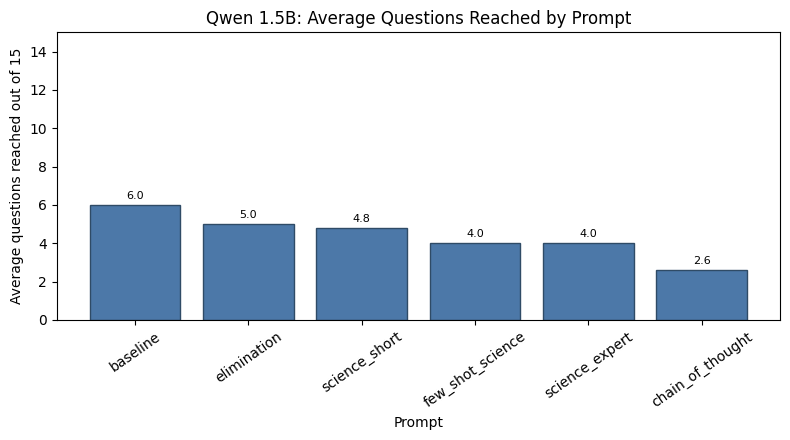

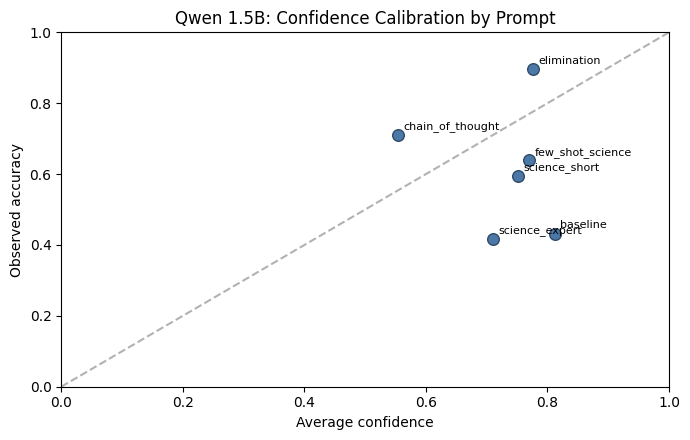

Qwen 1.5B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,qwen_1_5b,qwen_1_5b_baseline,baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.0,0.333333,non-thinking
2,qwen_1_5b,qwen_1_5b_elimination,elimination,5,5.0,7,4.0,20,0.266667,0.400000,900.0,2000,0.130808,0.188780,1.0,0.266667,non-thinking
5,qwen_1_5b,qwen_1_5b_science_short,science_short,5,4.8,8,3.8,19,0.253333,0.466667,1600.0,4000,0.236912,0.570446,1.0,0.253333,non-thinking
3,qwen_1_5b,qwen_1_5b_few_shot_science,few_shot_science,5,4.0,7,3.0,15,0.200000,0.400000,680.0,2000,0.151598,0.200574,1.0,0.200000,non-thinking
4,qwen_1_5b,qwen_1_5b_science_expert,science_expert,5,4.0,6,3.0,15,0.200000,0.333333,500.0,1000,0.135585,0.161141,1.0,0.200000,non-thinking
1,qwen_1_5b,qwen_1_5b_chain_of_thought,chain_of_thought,5,2.6,5,1.6,8,0.106667,0.266667,180.0,500,3.558811,4.236781,1.0,0.106667,non-thinking


Qwen 1.5B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
0,qwen_1_5b,baseline,Biology & medicine,5,5,0,1.000000,4.600000,3,0.111111
1,qwen_1_5b,baseline,Chemistry & materials,3,3,0,1.000000,5.333333,2,0.100000
6,qwen_1_5b,baseline,Technology & engineering,2,2,0,1.000000,2.000000,2,0.066667
5,qwen_1_5b,baseline,Scientific method & measurement,1,1,0,1.000000,1.000000,1,0.066667
3,qwen_1_5b,baseline,Other science/nature,12,9,3,0.750000,4.916667,4,0.150000
2,qwen_1_5b,baseline,Earth & environment,4,3,1,0.750000,3.750000,4,0.050000
4,qwen_1_5b,baseline,Physics & astronomy,3,2,1,0.666667,7.000000,2,0.066667
10,qwen_1_5b,chain_of_thought,Other science/nature,2,2,0,1.000000,1.500000,2,0.066667
11,qwen_1_5b,chain_of_thought,People & history of science,1,1,0,1.000000,2.000000,1,0.066667
8,qwen_1_5b,chain_of_thought,Chemistry & materials,4,3,1,0.750000,2.250000,3,0.066667


,model_label,prompt_type,error_type,count
0,qwen_1_5b,baseline,Correct,25
1,qwen_1_5b,baseline,High-confidence wrong answer,4
2,qwen_1_5b,baseline,Plausible but incorrect answer,1
3,qwen_1_5b,chain_of_thought,Correct,8
4,qwen_1_5b,chain_of_thought,Plausible but incorrect answer,5
5,qwen_1_5b,elimination,Correct,20
6,qwen_1_5b,elimination,High-confidence wrong answer,5
7,qwen_1_5b,few_shot_science,Correct,15
8,qwen_1_5b,few_shot_science,High-confidence wrong answer,4
9,qwen_1_5b,few_shot_science,Plausible but incorrect answer,1


Qwen 1.5B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,qwen_1_5b,baseline,30,30,1.0
1,qwen_1_5b,chain_of_thought,13,13,1.0
2,qwen_1_5b,elimination,25,25,1.0
3,qwen_1_5b,few_shot_science,20,20,1.0
4,qwen_1_5b,science_expert,20,20,1.0
5,qwen_1_5b,science_short,24,24,1.0


Qwen 1.5B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,qwen_1_5b,baseline,low (<= 0.40),0,NaN,NaN,NaN,0
1,qwen_1_5b,baseline,medium (0.40-0.70),1,0.000000,0.657850,0.316471,0
2,qwen_1_5b,baseline,high (>= 0.70),29,0.862069,0.965716,0.939021,4
3,qwen_1_5b,chain_of_thought,low (<= 0.40),6,0.333333,0.243933,-0.331656,0
4,qwen_1_5b,chain_of_thought,medium (0.40-0.70),5,0.800000,0.547070,0.269403,0
5,qwen_1_5b,chain_of_thought,high (>= 0.70),2,1.000000,0.868777,0.789229,0
6,qwen_1_5b,elimination,low (<= 0.40),0,NaN,NaN,NaN,0
7,qwen_1_5b,elimination,medium (0.40-0.70),1,1.000000,0.592657,0.185510,0
8,qwen_1_5b,elimination,high (>= 0.70),24,0.791667,0.960338,0.930287,5
9,qwen_1_5b,few_shot_science,low (<= 0.40),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
69,qwen_1_5b,science_expert,qwen_1_5b_science_expert,4,3,Other science/nature,During which activity should a student wear go...,examining a leaf with a microscope,3,0.998950,0.998067,"{""0"": 3.5762786865234375e-06, ""1"": 0.000883102...",False
101,qwen_1_5b,few_shot_science,qwen_1_5b_few_shot_science,1,3,Earth & environment,Which is a quick process that can form new lan...,weathering from waves,3,0.996453,0.992915,"{""0"": 1.0132789611816406e-06, ""1"": 0.003538131...",False
92,qwen_1_5b,elimination,qwen_1_5b_elimination,4,7,Chemistry & materials,Which of these chemical equations demonstrates...,2C_{2}H_{6} + 5O_{2} -> 4CO_{2} + 4H_{2}O,3,0.995883,0.992952,"{""0"": 2.0384788513183594e-05, ""1"": 0.002931594...",False
66,qwen_1_5b,science_expert,qwen_1_5b_science_expert,3,1,Chemistry & materials,The difference between the atomic number of an...,protons.,2,0.993003,0.986912,"{""0"": 1.1920928955078125e-07, ""1"": 0.006092071...",False
45,qwen_1_5b,science_short,qwen_1_5b_science_short,3,7,Earth & environment,A scientist maps a long region in which earthq...,The region shows extensive faulting of sediments.,3,0.992259,0.985251,"{""0"": 6.0617923736572266e-05, ""1"": 0.000672340...",False
80,qwen_1_5b,elimination,qwen_1_5b_elimination,2,6,Biology & medicine,Few flowers are able to grow on the northern a...,It protects them from freezing.,0,0.991248,0.987067,"{""0"": 0.9912109375, ""1"": 0.004180908203125, ""2...",False
73,qwen_1_5b,science_expert,qwen_1_5b_science_expert,5,4,Physics & astronomy,What term describes the energy absorbed or rel...,Sensible heat,1,0.989873,0.980465,"{""0"": 0.0006814002990722656, ""1"": 0.9897460937...",False
107,qwen_1_5b,few_shot_science,qwen_1_5b_few_shot_science,2,6,Biology & medicine,The types of organisms on Earth changed as a r...,aerobic breakdown of sugars to release energy,1,0.987129,0.974512,"{""0"": 1.7881393432617188e-07, ""1"": 0.987304687...",False
52,qwen_1_5b,science_short,qwen_1_5b_science_short,4,7,Technology & engineering,"A scientist lost the cap to an ammonia bottle,...",Store the new container in the refrigerator.,3,0.981737,0.971966,"{""0"": 1.6093254089355469e-06, ""1"": 0.009773254...",False
111,qwen_1_5b,few_shot_science,qwen_1_5b_few_shot_science,4,3,Physics & astronomy,Which planet is fourth from the Sun in our sol...,Venus,3,0.959346,0.919770,"{""0"": 2.294778823852539e-05, ""1"": 0.0395812988...",False


In [ ]:
qwen_1_5b_analysis = analyse_model_runs(
    df_all_prompts,
    model_tag="Qwen 1.5B",
    output_prefix="science_nature_qwen_1_5b",
    model_type="non-thinking",
)


##Conclusion

As we can see in the previous cell, Qwen 1.5B performs best with the baseline prompt, followed by elimination and science_short. However, the overall accuracy is still low, with the best prompt reaching only 25 correct answers across 5 runs, equal to 0.333 game accuracy.

The confidence results show that Qwen 1.5B is often overconfident. Most prompts have very high average confidence, but their actual accuracy is much lower. This means the model often assigns strong confidence to answers that are not correct. The chain_of_thought prompt has lower confidence, but it also has the weakest accuracy. Overall, confidence is useful here because it shows that Qwen 1.5B does not only make errors, but often makes them while appearing certain.

### Note on Qwen 1.5B calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator. The plot averages observed accuracy across confidence buckets, which inflates the results. For example, `elimination` appears close to 0.90 accuracy in the plot, but its correct game accuracy is 20 correct answers across 5 runs, which equals 20 / 75 = 0.267. Therefore, the Qwen 1.5B confidence plot needs to be regenerated using game accuracy out of 15 before drawing conclusions about calibration.

## Cleanup before alternative model comparison

Before loading a different model family, the previous model is removed from memory. This reduces the chance of CUDA out-of-memory errors in Colab.


In [ ]:
import gc
import torch

for variable_name in ["model", "tokenizer", "generator"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Previous model cleared from memory.")

Previous model cleared from memory.


In [ ]:
# huggingface_hub is installed and version-controlled in the Environment setup section.
print("huggingface_hub setup is handled at the top of the notebook.")


huggingface_hub setup is handled at the top of the notebook.


#Phi

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "microsoft/Phi-3.5-mini-instruct"

tokenizer = AutoTokenizer.from_pretrained(
    model_name,
    trust_remote_code=True
)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    trust_remote_code=True,
    attn_implementation="eager"
)

generator = make_text_generation_wrapper(model, tokenizer)

print("Loaded model:", model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/2.67G [00:00<?, ?B/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

Loaded model: microsoft/Phi-3.5-mini-instruct


In [ ]:
import time
import torch
import re

def generate_answer_for_phi_bugfix(question, prompt_type="science_short"):
    # This function directly calls model.generate to explicitly set use_cache=False for Phi models.
    # This addresses the `AttributeError: 'DynamicCache' object has no attribute 'get_max_length'`
    # by bypassing the pipeline's potential internal caching logic.

    # Check that the model and tokenizer have already been loaded.
    if 'model' not in globals() or 'tokenizer' not in globals():
        raise NameError("Model or tokenizer not found. Please ensure they are loaded.")

    # Check that the shared prompt builder is available.
    if 'build_prompt_from_type' not in globals():
        raise NameError("build_prompt_from_type not found. Please ensure cell vRiOijlXwVLe is run.")

    # Check that the shared token-budget helper is available.
    if 'generation_token_budget' not in globals():
        raise NameError("generation_token_budget not found. Please ensure cell vRiOijlXwVLe is run.")

    # Check that the shared answer parser is available.
    if 'parse_option_id' not in globals():
        raise NameError("parse_option_id not found. Please ensure cell vRiOijlXwVLe is run.")


    prompt = build_prompt_from_type(question, prompt_type)

    messages = [
        {
            "role": "system",
            "content": "You are a Science and Nature quiz assistant. Return only the numeric option ID. Do not write any explanation.",
        },
        {
            "role": "user",
            "content": prompt,
        },
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )

    start_time = time.time()

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 10),
            do_sample=False,
            use_cache=False,  # Disable cache to avoid the Phi DynamicCache issue.
            repetition_penalty=1.2,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    response_time = time.time() - start_time
    valid_option_ids = [option.id for option in question.options]
    predicted_id = parse_option_id(raw_response, valid_option_ids)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }

df_phi_science_short = benchmark_prompt(
    prompt_type="science_short",
    n_runs=3,
    delay_seconds=1.5,
    model_label="phi_3_mini",
    answer_fn=generate_answer_for_phi_bugfix # Use the Phi-specific generation function for this benchmark.
)

df_phi_science_short.to_csv(
    "science_nature_phi_3_mini_science_short.csv",
    index=False
)

summarise_results(df_phi_science_short)


Running model=phi_3_mini, prompt=science_short, run 1/3


Started game session: 329751
System: phi_3_mini_science_short

Level 1
Question: Earth rotates on its north-south axis. Which statement best describes one complete rotation?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.6 seconds

Level 2
Question: The Milky Way Galaxy looks like a band of light across the sky. Which observation would provide the best view of this band of light without a telescope?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.43 seconds

Level 3
Question: One role of a producer in a food chain is to provide
Raw response: 0 Producers, such as green
Submitted: 0
Correct: False
Response time: 0.95 seconds
Game ended.

Running model=phi_3_mini, prompt=science_short, run 2/3
Started game session: 329753
System: phi_3_mini_science_short

Level 1
Question: Mrs. Henderson's class has five small, covered boxes. One contains perfume; another contains dried onions. There is also a box of pine needles, a box of lemon pieces, and a box with a paper towe

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,phi_3_mini_science_short,20,17,1.0,0.474988,0.948864,1.0,0,1835.0,8000,3,NaN,NaN,0.377778


In [ ]:
current_model_label = "phi_3_mini"

In [ ]:
model_prompt_results = []

# Temporarily use the Phi-specific generation function for Phi benchmarks.
original_generate_answer = generate_answer
# Detect whether the currently loaded model is a Phi model.
is_phi_model = "phi" in current_model_label.lower()

if is_phi_model:
    generate_answer = generate_answer_for_phi_bugfix

for prompt_type in PROMPT_TYPES:
    df_prompt_model = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label=current_model_label
        # Without an explicit answer_fn, benchmark_prompt uses the current generate_answer function.
    )

    model_prompt_results.append(df_prompt_model)

df_current_model_prompts = pd.concat(model_prompt_results, ignore_index=True)

df_current_model_prompts.to_csv(
    f"science_nature_{current_model_label}_all_prompts.csv",
    index=False
)

df_current_model_prompts

# Restore the original answer function after the Phi benchmark.
if is_phi_model:
    generate_answer = original_generate_answer


Running model=phi_3_mini, prompt=baseline, run 1/5
Started game session: 329768
System: phi_3_mini_baseline

Level 1
Question: The sun provides heat and light to Earth. The sun is best described as
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.36 seconds

Level 2
Question: What is the primary source of the orange color in annatto?
Raw response: 0
Submitted: 0
Correct: True
Response time: 0.35 seconds

Level 3
Question: One difference between a chemical formula and a chemical equation is that the chemical equation shows
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.4 seconds

Level 4
Question: Which of the following best describes cosmic dust?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.4 seconds

Level 5
Question: The Moon is in orbit around Earth. What keeps the Moon from changing its orbit?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.35 seconds

Level 6
Question: Two forms of boron are naturally occurring, boron-10 and boro

In [ ]:
current_model_prompt_summary = summarise_results(df_current_model_prompts)
current_model_prompt_summary

,system_name,questions_attempted,correct_answers,valid_output_rate,average_response_time,max_response_time,under_30_seconds_rate,timeouts,average_earned_amount,best_earned_amount,runs,average_confidence,max_confidence,accuracy
0,phi_3_mini_baseline,56,52,1.000000,0.428792,1.130582,1.0,0,65725.000000,1024000,5,NaN,NaN,0.693333
1,phi_3_mini_chain_of_thought,8,3,0.375000,13.801006,15.119485,1.0,0,75.000000,100,5,NaN,NaN,0.040000
2,phi_3_mini_elimination,43,39,0.976744,0.503825,1.226471,1.0,0,52125.581395,1024000,5,NaN,NaN,0.520000
3,phi_3_mini_few_shot_science,36,31,1.000000,0.868877,0.914915,1.0,0,5594.444444,32000,5,NaN,NaN,0.413333
4,phi_3_mini_science_expert,43,39,0.953488,0.537077,1.212849,1.0,0,65706.976744,1024000,5,NaN,NaN,0.520000
5,phi_3_mini_science_short,45,41,1.000000,0.433267,1.119313,1.0,0,47924.444444,1024000,5,NaN,NaN,0.546667


In [ ]:
run_summary_current_model = make_run_summary(df_current_model_prompts)
survival_summary_current_model = make_survival_summary(df_current_model_prompts)

survival_summary_current_model


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy
0,phi_3_mini,phi_3_mini_baseline,baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333
1,phi_3_mini,phi_3_mini_chain_of_thought,chain_of_thought,5,1.6,2,0.6,3,0.040000,0.066667,60.0,100,13.694002,15.119485,0.400000,0.040000
2,phi_3_mini,phi_3_mini_elimination,elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000
3,phi_3_mini,phi_3_mini_few_shot_science,few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333
4,phi_3_mini,phi_3_mini_science_expert,science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000
5,phi_3_mini,phi_3_mini_science_short,science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667


In [ ]:
survival_summary_qwen_1_5b = survival_summary.copy()
survival_summary_qwen_1_5b["model_label"] = "qwen_1_5b"

In [ ]:
if "prompt_type" not in survival_summary_qwen_1_5b.columns:
    survival_summary_qwen_1_5b["prompt_type"] = (
        survival_summary_qwen_1_5b["system_name"]
        .str.replace("qwen_1_5b_", "", regex=False)
    )

In [ ]:
[name for name in globals() if "summary" in name or "survival" in name]

['make_run_summary',
 'make_survival_summary',
 'sort_survival_summary',
 'baseline_summary',
 'level_summary',
 'prompt_summary',
 'prompt_summary_5runs',
 'run_summary',
 'survival_summary',
 'current_model_prompt_summary',
 'run_summary_current_model',
 'survival_summary_current_model',
 'survival_summary_qwen_1_5b']

In [ ]:
combined_model_prompt_summary = pd.concat(
    [
        survival_summary_qwen_1_5b,
        survival_summary_current_model
    ],
    ignore_index=True
)

combined_model_prompt_summary

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type
0,qwen_1_5b_baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.000000,0.333333,qwen_1_5b,baseline
1,qwen_1_5b_chain_of_thought,5,2.6,5,1.6,8,0.106667,0.266667,180.0,500,3.558811,4.236781,1.000000,0.106667,qwen_1_5b,chain_of_thought
2,qwen_1_5b_elimination,5,5.0,7,4.0,20,0.266667,0.400000,900.0,2000,0.130808,0.188780,1.000000,0.266667,qwen_1_5b,elimination
3,qwen_1_5b_few_shot_science,5,4.0,7,3.0,15,0.200000,0.400000,680.0,2000,0.151598,0.200574,1.000000,0.200000,qwen_1_5b,few_shot_science
4,qwen_1_5b_science_expert,5,4.0,6,3.0,15,0.200000,0.333333,500.0,1000,0.135585,0.161141,1.000000,0.200000,qwen_1_5b,science_expert
5,qwen_1_5b_science_short,5,4.8,8,3.8,19,0.253333,0.466667,1600.0,4000,0.236912,0.570446,1.000000,0.253333,qwen_1_5b,science_short
6,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline
7,phi_3_mini_chain_of_thought,5,1.6,2,0.6,3,0.040000,0.066667,60.0,100,13.694002,15.119485,0.400000,0.040000,phi_3_mini,chain_of_thought
8,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination
9,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science


In [ ]:
phi_errors = df_current_model_prompts[
    df_current_model_prompts["model_label"] == "phi_3_mini"
].copy()

phi_errors = phi_errors[phi_errors["correct"] == False]

phi_errors[
    [
        "prompt_type",
        "level_before_answer",
        "question_text",
        "options",
        "raw_response",
        "selected_option_id",
        "selected_option_text",
        "response_time"
    ]
]

,prompt_type,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,response_time
16,baseline,2,Which of the following is the primary use of s...,"[{""id"": 0, ""text"": ""Treatment of cyanide poiso...",1,1,Preservation of meat,0.348460
30,baseline,14,What term describes the region in the left hem...,"[{""id"": 0, ""text"": ""Pars orbitalis""}, {""id"": 1...",3,3,Pars opercularis,0.362173
41,baseline,11,How does the measurement of time differ betwee...,"[{""id"": 0, ""text"": ""Practical human-scale meas...",1,1,Practical human-scale measurements use clocks ...,0.612842
55,baseline,14,What is the primary reason some physicists bel...,"[{""id"": 0, ""text"": ""It naturally incorporates ...",3,3,It incorporates all known fundamental forces i...,0.452969
65,science_short,10,"Matt is a tall, eleven-year-old boy. He has a ...","[{""id"": 0, ""text"": ""his scar on his right chee...",1 or 2 (both could be considered,1,his intelligence,1.119313
75,science_short,10,Anita sprinted around the track at her school....,"[{""id"": 0, ""text"": ""nervous and endocrine""}, {...",1,1,respiratory and circulatory,0.448866
83,science_short,8,"A plant grows in a damp, marshy area filled wi...","[{""id"": 0, ""text"": ""It is 18 cm tall.""}, {""id""...",3,3,It produces spores.,0.449352
85,science_short,2,"n 1931, Barbara McClintock discovered that gen...","[{""id"": 0, ""text"": ""Chromosomes can move aroun...",0,0,Chromosomes can move around in the nucleus of ...,0.553401
101,science_expert,1,Why do astronauts need oxygen in the backpacks...,"[{""id"": 0, ""text"": ""to help astronauts breathe...",1,1,to manage carbon dioxide that astronauts breat...,0.484892
130,science_expert,14,Which of the following best describes the prim...,"[{""id"": 0, ""text"": ""It assumes that the treatm...",3,3,It cannot account for time-varying confounders.,0.509043


In [ ]:
game = client.game.start(competition_id=comp_id, mode="text")
question = game.current_question

prediction = generate_answer_phi(question, prompt_type="science_short")

print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Raw Phi response:", prediction["raw_response"])
print("Predicted ID:", prediction["predicted_id"])
print("Response time:", prediction["response_time"])

Question: Ella has several wooden blocks. When Ella holds the blocks in her hand, she feels that they are rough. Which term best describes what Ella feels?

0: an observation
1: a hypothesis
2: a conclusion
3: a prediction

Raw Phi response: 0
Predicted ID: 0
Response time: 0.38901281356811523


In [ ]:
valid_model_prompt_summary = combined_model_prompt_summary[
    combined_model_prompt_summary["valid_output_rate"] > 0.5
].copy()

valid_model_prompt_summary_sorted = valid_model_prompt_summary.sort_values(
    by=[
        "average_questions_reached",
        "average_final_earned_amount",
        "average_response_time"
    ],
    ascending=[False, False, True]
)

valid_model_prompt_summary_sorted

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type
6,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline
11,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short
10,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert
8,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination
9,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science
0,qwen_1_5b_baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.000000,0.333333,qwen_1_5b,baseline
2,qwen_1_5b_elimination,5,5.0,7,4.0,20,0.266667,0.400000,900.0,2000,0.130808,0.188780,1.000000,0.266667,qwen_1_5b,elimination
5,qwen_1_5b_science_short,5,4.8,8,3.8,19,0.253333,0.466667,1600.0,4000,0.236912,0.570446,1.000000,0.253333,qwen_1_5b,science_short
3,qwen_1_5b_few_shot_science,5,4.0,7,3.0,15,0.200000,0.400000,680.0,2000,0.151598,0.200574,1.000000,0.200000,qwen_1_5b,few_shot_science
4,qwen_1_5b_science_expert,5,4.0,6,3.0,15,0.200000,0.333333,500.0,1000,0.135585,0.161141,1.000000,0.200000,qwen_1_5b,science_expert


In [ ]:
phi_diagnostic_summary = combined_model_prompt_summary[
    combined_model_prompt_summary["model_label"] == "phi_3_mini"
].copy()

phi_diagnostic_summary

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type
6,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline
7,phi_3_mini_chain_of_thought,5,1.6,2,0.6,3,0.040000,0.066667,60.0,100,13.694002,15.119485,0.400000,0.040000,phi_3_mini,chain_of_thought
8,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination
9,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science
10,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert
11,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short


In [ ]:
valid_model_prompt_summary_sorted.to_csv(
    "science_nature_valid_model_prompt_comparison.csv",
    index=False
)

phi_diagnostic_summary.to_csv(
    "science_nature_phi_diagnostic_summary.csv",
    index=False
)

## Phi diagnostic and corrected evaluation
This part is due to the first phi models that I tried didn't work properly so I did this:

The first Phi experiment produced repeated fragments such as `eeseesees` and `heckheck`, and the valid-output rate was 0.0. That pattern is more consistent with a generation/prompt-formatting issue than with ordinary model weakness.

For Phi, we therefore test two safer approaches:

1. **Chat-template generation**, using the tokenizer's own instruction format instead of a plain pipeline prompt.
2. **Forced-choice scoring**, where the model scores each available answer option and we choose the option with the highest likelihood. This avoids relying on the model to generate a perfectly formatted number.


In [ ]:
import gc
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM


def clear_model_from_memory():
    for variable_name in ["model", "tokenizer", "generator"]:
        if variable_name in globals():
            del globals()[variable_name]

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_phi_model():
    global model, tokenizer, model_name, current_model_label

    clear_model_from_memory()

    model_name = "microsoft/Phi-3.5-mini-instruct"
    current_model_label = "phi_3_5_mini_fixed"

    tokenizer = AutoTokenizer.from_pretrained(
        model_name,
        trust_remote_code=True,
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        device_map="auto",
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        trust_remote_code=True,
        attn_implementation="eager",
    )

    # Disable caching in the model configuration when the attribute is available.
    if hasattr(model.config, 'use_cache'):
        model.config.use_cache = False

    model.eval()

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    print("Loaded fixed Phi model:", model_name)


load_phi_model()

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct


In [ ]:
def build_phi_chat_text(question, prompt_type="science_short"):
    prompt = build_prompt_from_type(question, prompt_type) if "build_prompt_from_type" in globals() else build_prompt_science_short(question)

    messages = [
        {
            "role": "user",
            "content": (
                prompt
                + "\n\nReturn exactly one option ID from the list. "
                + "Do not explain. Do not repeat words."
            ),
        }
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    ), prompt


def generate_answer_phi_fixed(question, prompt_type="science_short"):
    formatted_prompt, prompt = build_phi_chat_text(question, prompt_type)
    start_time = time.time()

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 8),
            do_sample=False,
            repetition_penalty=1.05,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            use_cache=False,
        )

    response_time = time.time() - start_time
    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
    raw_response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

    valid_option_ids = [option.id for option in question.options]

    if "parse_option_id" in globals():
        predicted_id = parse_option_id(raw_response, valid_option_ids)
    else:
        numbers = re.findall(r"\d+", raw_response)
        predicted_id = next(
            (int(number) for number in numbers if int(number) in valid_option_ids),
            None,
        )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
    }

In [ ]:
# Backward-compatible name for the Phi section.
score_candidate_continuation = score_candidate_continuation_generic


def generate_answer_phi_scored(question, prompt_type="science_short"):
    formatted_prompt, prompt = build_phi_chat_text(question, prompt_type)
    base_text = formatted_prompt + "The correct answer is option"
    start_time = time.time()

    option_scores = {}

    for option in question.options:
        candidate_text = f" {option.id}: {option.text}"
        score, token_count = score_candidate_continuation_generic(
            base_text,
            candidate_text,
            return_token_count=True,
        )
        option_scores[int(option.id)] = {
            "score": score,
            "tokens": token_count,
            "text": option.text,
        }

    predicted_id = max(
        option_scores,
        key=lambda option_id: option_scores[option_id]["score"],
    )

    response_time = time.time() - start_time
    raw_response = json.dumps(option_scores, ensure_ascii=False)

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": {
            option_id: values["score"]
            for option_id, values in option_scores.items()
        },
    }


In [ ]:
def benchmark_phi_answer_fn(
    answer_fn,
    model_label,
    prompt_type="science_short",
    n_runs=5,
    delay_seconds=1.5,
):
    return benchmark_answer_fn(
        answer_fn=answer_fn,
        model_label=model_label,
        prompt_type=prompt_type,
        n_runs=n_runs,
        delay_seconds=delay_seconds,
        model_type="non-thinking",
    )


make_phi_survival_summary = make_survival_summary


In [ ]:
# Quick diagnostic: compare generated-answer Phi with forced-choice Phi on one question.
game = client.game.start(competition_id=comp_id, mode="text")
question = game.current_question

phi_generated_prediction = generate_answer_phi_fixed(
    question,
    prompt_type="science_short",
)
phi_scored_prediction = generate_answer_phi_scored(
    question,
    prompt_type="science_short",
)

print("Question:", question.text)
print()

for option in question.options:
    print(f"{option.id}: {option.text}")

print()
print("Phi generated raw response:", phi_generated_prediction["raw_response"])
print("Phi generated predicted ID:", phi_generated_prediction["predicted_id"])
print("Phi scored predicted ID:", phi_scored_prediction["predicted_id"])
print("Phi scored option scores:", phi_scored_prediction["raw_response"])


Question: In ecosystems where people live, which of the following are most likely to cause an increase in diseases transmitted by water?

0: floods
1: hailstorms
2: avalanches
3: blizzards

Phi generated raw response: 0
Phi generated predicted ID: 0
Phi scored predicted ID: 0
Phi scored option scores: {"0": {"score": -1.0252256393432617, "tokens": 5, "text": "floods"}, "1": {"score": -1.5287467241287231, "tokens": 7, "text": "hailstorms"}, "2": {"score": -1.8037033081054688, "tokens": 7, "text": "avalanches"}, "3": {"score": -2.5537805557250977, "tokens": 6, "text": "blizzards"}}


In [ ]:
df_phi_fixed_generation = benchmark_phi_answer_fn(
    answer_fn=generate_answer_phi_fixed,
    model_label="phi_3_5_mini_fixed_generation",
    prompt_type="science_short",
    n_runs=5,
    delay_seconds=1.5,
)

phi_fixed_generation_summary = make_phi_survival_summary(df_phi_fixed_generation)
phi_fixed_generation_summary



Running model=phi_3_5_mini_fixed_generation, prompt=science_short, run 1/5
Started game session: 330164
System: phi_3_5_mini_fixed_generation_science_short

Level 1
Question: Which of these is a chemical property of a material?
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.35 seconds

Level 2
Question: Which of the following is an example of genetic engineering?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.46 seconds

Level 3
Question: Which sentence best describes the organization of the heart?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.45 seconds

Level 4
Question: An ocean, a forest, and a grassy meadow are each examples of a complete ecosystem. Complete ecosystems contain only
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.4 seconds

Level 5
Question: The following represents a number displayed on a calculator. 1.454545 E3. Which of the following shows how a student should record this number in a laboratory report?
Raw res

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_fixed_generation,phi_3_5_mini_fixed_generation_science_short,science_short,5,13.8,15,13.0,65,0.866667,1.0,464000.0,1024000,0.422788,0.941358,1.0,0.866667,non-thinking


In [ ]:
df_phi_forced_choice = benchmark_phi_answer_fn(
    answer_fn=generate_answer_phi_scored,
    model_label="phi_3_5_mini_forced_choice",
    prompt_type="science_short",
    n_runs=5,
    delay_seconds=1.5,
)

phi_forced_choice_summary = make_phi_survival_summary(df_phi_forced_choice)
phi_forced_choice_summary



Running model=phi_3_5_mini_forced_choice, prompt=science_short, run 1/5
Started game session: 330303
System: phi_3_5_mini_forced_choice_science_short

Level 1
Question: If a cell is exposed to a chemical that inhibits the production of spindle fibers as the cell is preparing for mitosis, what would most likely happen?
Raw response: {"0": {"score": -0.8133125901222229, "tokens": 12, "text": "The cell would continue with mitotic division."}, "1": {"score": -0.6112096309661865, "tokens": 9, "text": "The cell would not divide."}, "2": {"score": -0.8296027779579163, "tokens": 13, "text": "The cell would undergo meiotic division."}, "3": {"score": -1.4283639192581177, "tokens": 9, "text": "The cell would break open."}}
Submitted: 1
Correct: True
Response time: 0.45 seconds

Level 2
Question: A sea anemone uses poisonous darts to
Raw response: {"0": {"score": -1.0472185611724854, "tokens": 6, "text": "defend itself."}, "1": {"score": -1.3199506998062134, "tokens": 7, "text": "protect its you

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_forced_choice,phi_3_5_mini_forced_choice_science_short,science_short,5,7.6,15,6.8,34,0.453333,1.0,206740.0,1024000,0.414797,0.612885,1.0,0.453333,non-thinking


In [ ]:
phi_fixed_comparison = pd.concat(
    [
        phi_diagnostic_summary,
        phi_fixed_generation_summary,
        phi_forced_choice_summary,
    ],
    ignore_index=True,
    sort=False,
)

phi_fixed_comparison = phi_fixed_comparison.sort_values(
    by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
    ascending=False,
)

df_phi_fixed_generation.to_csv("science_nature_phi_fixed_generation_results.csv", index=False)
df_phi_forced_choice.to_csv("science_nature_phi_forced_choice_results.csv", index=False)
phi_fixed_comparison.to_csv("science_nature_phi_fixed_comparison.csv", index=False)

phi_fixed_comparison


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
6,phi_3_5_mini_fixed_generation_science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.000000,0.866667,phi_3_5_mini_fixed_generation,science_short,non-thinking
0,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline,NaN
5,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short,NaN
4,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert,NaN
2,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination,NaN
7,phi_3_5_mini_forced_choice_science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.000000,0.453333,phi_3_5_mini_forced_choice,science_short,non-thinking
3,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science,NaN
1,phi_3_mini_chain_of_thought,5,1.6,2,0.6,3,0.040000,0.066667,60.0,100,13.694002,15.119485,0.400000,0.040000,phi_3_mini,chain_of_thought,NaN


<!-- REPORT_MARKDOWN_PHI_V2 -->

### Phi models and corrected generation

The Phi models produced the strongest Science & Nature results in the saved outputs. The best system is `phi_3_5_mini_fixed_generation_science_short`, reaching **13.8 average questions**, a best run of **15**, game accuracy of **65 / 75 = 0.867**, a valid-output rate of **1.0**, and an average response time of about **0.42 seconds**.

This means the corrected Phi-3.5-mini fixed-generation setup is now stronger than the older `phi_3_mini_baseline`, which reached **11.2 average questions**. The forced-choice Phi-3.5-mini scorer was useful for confidence and calibration analysis, but it did not beat fixed generation in survival performance. Therefore, fixed generation is the best observed system, while forced-choice scoring is mainly useful as a reliability-checking method.


## Phi prompt, topic, error, and confidence analysis

This section analyses the corrected Phi runs before comparing against the later model families.

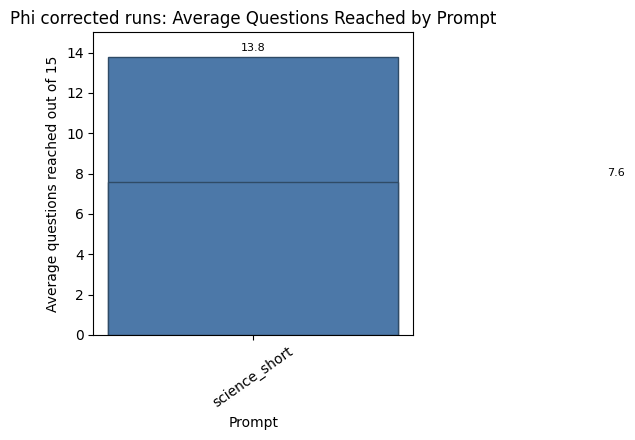

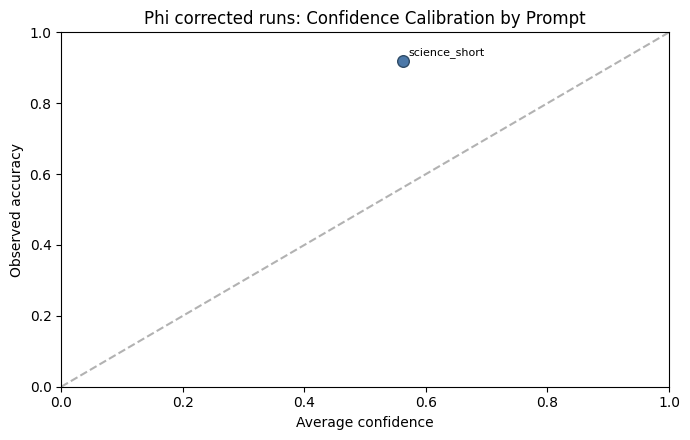

Phi corrected runs: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_fixed_generation,phi_3_5_mini_fixed_generation_science_short,science_short,5,13.8,15,13.0,65,0.866667,1.0,464000.0,1024000,0.422788,0.941358,1.0,0.866667,non-thinking
1,phi_3_5_mini_forced_choice,phi_3_5_mini_forced_choice_science_short,science_short,5,7.6,15,6.8,34,0.453333,1.0,206740.0,1024000,0.414797,0.612885,1.0,0.453333,non-thinking


Phi corrected runs: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
5,phi_3_5_mini_fixed_generation,science_short,Physics & astronomy,14,14,0,1.000000,8.785714,5,0.186667
13,phi_3_5_mini_forced_choice,science_short,Physics & astronomy,10,10,0,1.000000,5.400000,4,0.166667
0,phi_3_5_mini_fixed_generation,science_short,Biology & medicine,9,9,0,1.000000,5.222222,4,0.150000
1,phi_3_5_mini_fixed_generation,science_short,Chemistry & materials,7,7,0,1.000000,8.428571,4,0.116667
2,phi_3_5_mini_fixed_generation,science_short,Earth & environment,5,5,0,1.000000,3.600000,4,0.083333
4,phi_3_5_mini_fixed_generation,science_short,People & history of science,5,5,0,1.000000,4.200000,2,0.166667
7,phi_3_5_mini_fixed_generation,science_short,Technology & engineering,4,4,0,1.000000,10.250000,3,0.088889
9,phi_3_5_mini_forced_choice,science_short,Chemistry & materials,3,3,0,1.000000,9.000000,1,0.200000
10,phi_3_5_mini_forced_choice,science_short,Earth & environment,3,3,0,1.000000,4.333333,3,0.066667
12,phi_3_5_mini_forced_choice,science_short,People & history of science,2,2,0,1.000000,3.500000,2,0.066667


,model_label,prompt_type,error_type,count
0,phi_3_5_mini_fixed_generation,science_short,Correct,65
1,phi_3_5_mini_fixed_generation,science_short,Plausible but incorrect answer,4
2,phi_3_5_mini_forced_choice,science_short,Correct,34
3,phi_3_5_mini_forced_choice,science_short,Plausible but incorrect answer,4


Phi corrected runs: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_3_5_mini_fixed_generation,science_short,69,0,0.0
1,phi_3_5_mini_forced_choice,science_short,38,38,1.0


Phi corrected runs: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_3_5_mini_forced_choice,science_short,low (<= 0.40),14,0.857143,0.348143,0.082931,0
1,phi_3_5_mini_forced_choice,science_short,medium (0.40-0.70),20,0.900000,0.506321,0.281917,0
2,phi_3_5_mini_forced_choice,science_short,high (>= 0.70),4,1.000000,0.830780,0.740446,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
df_phi_corrected_runs = pd.concat(
    [
        df_phi_fixed_generation,
        df_phi_forced_choice,
    ],
    ignore_index=True,
    sort=False,
)

phi_corrected_analysis = analyse_model_runs(
    df_phi_corrected_runs,
    model_tag="Phi corrected runs",
    output_prefix="science_nature_phi_corrected",
    model_type="non-thinking",
)



### Phi error and confidence conclusion

The corrected Phi results show strong overall performance, with `phi_3_5_mini_fixed_generation_science_short` reaching **13.8 average questions** and **65 / 75 = 0.867 game accuracy**. Most errors were **plausible but incorrect answers**, meaning the model usually chose a reasonable wrong option rather than failing to answer.

By topic, Phi performed very well in areas such as **Physics & astronomy**, **Biology & medicine**, and **Chemistry & materials**. The main errors appeared in **Other science/nature** and **Scientific method & measurement**.

The confidence results are also positive: higher confidence is linked with higher accuracy, and there are **no overconfident errors**. This suggests that Phi’s confidence scores are useful for judging when its answers are more reliable.

### Note on Phi calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

# Qwen2.5-3B model comparison

In [ ]:
model_name = "Qwen/Qwen2.5-3B-Instruct"

In [ ]:
import gc
import torch

for variable_name in ["model", "tokenizer", "generator"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Previous model cleared.")

Previous model cleared.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

generator = make_text_generation_wrapper(model, tokenizer)

print("Loaded model:", model_name)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded model: Qwen/Qwen2.5-3B-Instruct


In [ ]:
current_model_label = "qwen_3b"

qwen3b_results = []

for prompt_type in PROMPT_TYPES:
    df_qwen3b_prompt = benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label=current_model_label,
        answer_fn=generate_answer_chat_template_with_confidence,
        model_type="non-thinking",
    )

    qwen3b_results.append(df_qwen3b_prompt)

df_qwen3b_prompts = pd.concat(qwen3b_results, ignore_index=True)

df_qwen3b_prompts.to_csv(
    "science_nature_qwen_3b_prompts.csv",
    index=False,
)

df_qwen3b_prompts



Running model=qwen_3b, prompt=baseline, run 1/5


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 331445
System: qwen_3b_baseline

Level 1
Question: Which of the following is a cause of the ocean levels periodically rising and then falling?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.19 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: Which of the following best describes the concept of coherence in physics?
Raw response: 2
Submitted: 2
Correct: True
Response time: 0.18 seconds


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 6
Question: In the Leidenfrost effect, how does the temperature of the surface affect the behavior of water droplets?
Raw response: Let's analyze each option:

0. This is incorrect as the question states that the temperature affects the behavior.
1. This contradicts the Leidenfrost effect where droplets should not hiss and evaporate immediately.
2. This aligns with the Leidenfrost effect where droplets skitter due to vapor layer cushioning.
3. This describes evaporation at lower temperatures, which is opposite to the Leidenfrost effect.

Final answer: 2
Submitted: 2
Correct: True
Response time: 5.56 seconds


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 7
Question: Flooding rivers can help or harm the environment. Which of these would be a helpful effect from a flood?
Raw response: 3. less habitat for aquatic animals

Final answer: 3
Submitted: 3
Correct: False
Response time: 0.81 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,qwen_3b_baseline,331445,1,5398,Which of the following is a cause of the ocean...,16,"[{""id"": 0, ""text"": ""the revolution of Earth ar...",1,the force of gravity from the Moon,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,100,0.998754,0.997510,"{""0"": 1.1920928955078125e-07, ""1"": 0.998535156...",1,qwen_3b,non-thinking
1,qwen_3b_baseline,331445,2,2440,Which of the following best describes the conc...,12,"[{""id"": 0, ""text"": ""The speed at which a wave ...",2,The measure of how much two waves can interfer...,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,200,0.999995,0.999989,"{""0"": 0.0, ""1"": 0.0, ""2"": 1.0, ""3"": 5.48362731...",1,qwen_3b,non-thinking
2,qwen_3b_baseline,331445,3,5922,Which tool could be used to help someone count...,16,"[{""id"": 0, ""text"": ""microscope""}, {""id"": 1, ""t...",0,microscope,Qwen/Qwen2.5-3B-Instruct,...,False,False,True,200,0.984515,0.969086,"{""0"": 0.984375, ""1"": 0.0154266357421875, ""2"": ...",1,qwen_3b,non-thinking
3,qwen_3b_baseline,331451,1,3591,Two high tides and two low tides occur on Eart...,11,"[{""id"": 0, ""text"": ""hour.""}, {""id"": 1, ""text"":...",1,day.,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,100,0.998667,0.997342,"{""0"": 1.7881393432617188e-07, ""1"": 0.998535156...",2,qwen_3b,non-thinking
4,qwen_3b_baseline,331451,2,4176,The winter solstice occurs on either December ...,39,"[{""id"": 0, ""text"": ""Earth is traveling around ...",3,Earth's Northern Hemisphere is tilted away fro...,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,200,0.999999,0.999999,"{""0"": 0.0, ""1"": 0.0, ""2"": 6.556510925292969e-0...",2,qwen_3b,non-thinking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,qwen_3b_chain_of_thought,331721,3,5215,The influence of the Moon on the tides on Eart...,21,"[{""id"": 0, ""text"": ""The Moon is more similar i...",1,The Moon is closer to Earth than the Sun.,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,300,0.975704,0.959177,"{""0"": 0.0165252685546875, ""1"": 0.9755859375, ""...",5,qwen_3b,non-thinking
164,qwen_3b_chain_of_thought,331721,4,6023,The movement of soil by wind or water is called,10,"[{""id"": 0, ""text"": ""erosion""}, {""id"": 1, ""text...",0,erosion,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,500,0.965234,0.934689,"{""0"": 0.96533203125, ""1"": 0.030548095703125, ""...",5,qwen_3b,non-thinking
165,qwen_3b_chain_of_thought,331721,5,5924,Brian knows deserts get less rain than other e...,33,"[{""id"": 0, ""text"": ""the ability to drop its le...",2,the ability to store water,Qwen/Qwen2.5-3B-Instruct,...,True,False,False,1000,0.870038,0.806018,"{""0"": 0.03167724609375, ""1"": 0.06402587890625,...",5,qwen_3b,non-thinking
166,qwen_3b_chain_of_thought,331721,6,2101,"In the Leidenfrost effect, how does the temper...",17,"[{""id"": 0, ""text"": ""Droplets behave the same r...",2,"At the Leidenfrost point, droplets skitter aro...",Qwen/Qwen2.5-3B-Instruct,...,True,False,False,2000,0.214754,-0.488966,"{""0"": 0.07305908203125, ""1"": 0.70361328125, ""2...",5,qwen_3b,non-thinking


In [ ]:
run_summary_qwen3b = make_run_summary(df_qwen3b_prompts)
survival_summary_qwen3b = make_survival_summary(df_qwen3b_prompts)

survival_summary_qwen3b


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,qwen_3b,qwen_3b_baseline,baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,non-thinking
1,qwen_3b,qwen_3b_chain_of_thought,chain_of_thought,5,4.8,8,3.8,19,0.253333,0.466667,1340.0,4000,3.022503,5.602407,0.933333,0.253333,non-thinking
2,qwen_3b,qwen_3b_elimination,elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,non-thinking
3,qwen_3b,qwen_3b_few_shot_science,few_shot_science,5,2.8,8,1.8,9,0.120000,0.466667,840.0,4000,0.293124,0.337631,1.000000,0.120000,non-thinking
4,qwen_3b,qwen_3b_science_expert,science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,non-thinking
5,qwen_3b,qwen_3b_science_short,science_short,5,5.2,9,4.2,21,0.280000,0.533333,2800.0,8000,0.182907,0.247055,1.000000,0.280000,non-thinking


In [ ]:
qwen_comparison_summary = pd.concat(
    [
        survival_summary_qwen_1_5b,
        survival_summary_qwen3b
    ],
    ignore_index=True
)

qwen_comparison_summary_sorted = qwen_comparison_summary.sort_values(
    by=[
        "average_questions_reached",
        "average_final_earned_amount",
        "average_response_time"
    ],
    ascending=[False, False, True]
)

qwen_comparison_summary_sorted

,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
10,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking
6,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking
8,qwen_3b_elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,qwen_3b,elimination,non-thinking
0,qwen_1_5b_baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.000000,0.333333,qwen_1_5b,baseline,NaN
11,qwen_3b_science_short,5,5.2,9,4.2,21,0.280000,0.533333,2800.0,8000,0.182907,0.247055,1.000000,0.280000,qwen_3b,science_short,non-thinking
2,qwen_1_5b_elimination,5,5.0,7,4.0,20,0.266667,0.400000,900.0,2000,0.130808,0.188780,1.000000,0.266667,qwen_1_5b,elimination,NaN
5,qwen_1_5b_science_short,5,4.8,8,3.8,19,0.253333,0.466667,1600.0,4000,0.236912,0.570446,1.000000,0.253333,qwen_1_5b,science_short,NaN
7,qwen_3b_chain_of_thought,5,4.8,8,3.8,19,0.253333,0.466667,1340.0,4000,3.022503,5.602407,0.933333,0.253333,qwen_3b,chain_of_thought,non-thinking
3,qwen_1_5b_few_shot_science,5,4.0,7,3.0,15,0.200000,0.400000,680.0,2000,0.151598,0.200574,1.000000,0.200000,qwen_1_5b,few_shot_science,NaN
4,qwen_1_5b_science_expert,5,4.0,6,3.0,15,0.200000,0.333333,500.0,1000,0.135585,0.161141,1.000000,0.200000,qwen_1_5b,science_expert,NaN


In [ ]:
qwen_comparison_summary_sorted.to_csv(
    "science_nature_qwen_model_prompt_comparison.csv",
    index=False
)

print("Qwen model comparison saved.")

Qwen model comparison saved.


## Qwen2.5 - 3B prompt, topic, error, and confidence analysis

This cell keeps the Qwen 3B analysis next to the Qwen 3B run, instead of waiting until the end of the notebook.


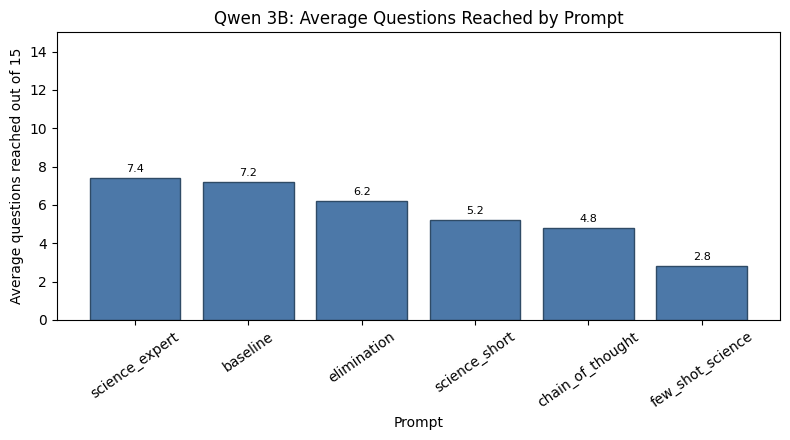

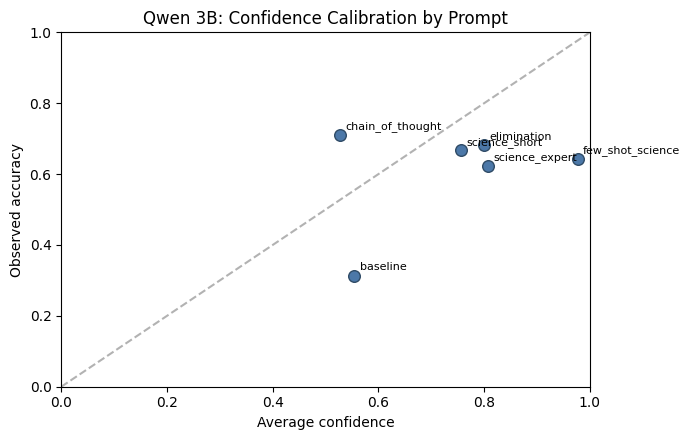

Qwen 3B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,qwen_3b,qwen_3b_science_expert,science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,non-thinking
0,qwen_3b,qwen_3b_baseline,baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,non-thinking
2,qwen_3b,qwen_3b_elimination,elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,non-thinking
5,qwen_3b,qwen_3b_science_short,science_short,5,5.2,9,4.2,21,0.280000,0.533333,2800.0,8000,0.182907,0.247055,1.000000,0.280000,non-thinking
1,qwen_3b,qwen_3b_chain_of_thought,chain_of_thought,5,4.8,8,3.8,19,0.253333,0.466667,1340.0,4000,3.022503,5.602407,0.933333,0.253333,non-thinking
3,qwen_3b,qwen_3b_few_shot_science,few_shot_science,5,2.8,8,1.8,9,0.120000,0.466667,840.0,4000,0.293124,0.337631,1.000000,0.120000,non-thinking


Qwen 3B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
0,qwen_3b,baseline,Biology & medicine,9,9,0,1.000000,5.222222,4,0.150000
6,qwen_3b,baseline,Technology & engineering,3,3,0,1.000000,3.333333,3,0.066667
4,qwen_3b,baseline,People & history of science,1,1,0,1.000000,3.000000,1,0.066667
2,qwen_3b,baseline,Earth & environment,6,5,1,0.833333,4.333333,3,0.111111
1,qwen_3b,baseline,Chemistry & materials,5,4,1,0.800000,3.800000,4,0.066667
3,qwen_3b,baseline,Other science/nature,9,7,2,0.777778,7.333333,3,0.155556
5,qwen_3b,baseline,Physics & astronomy,3,2,1,0.666667,4.000000,2,0.066667
11,qwen_3b,chain_of_thought,Physics & astronomy,7,7,0,1.000000,3.285714,4,0.116667
8,qwen_3b,chain_of_thought,Chemistry & materials,2,2,0,1.000000,3.500000,2,0.066667
13,qwen_3b,chain_of_thought,Technology & engineering,1,1,0,1.000000,6.000000,1,0.066667


,model_label,prompt_type,error_type,count
0,qwen_3b,baseline,Correct,31
1,qwen_3b,baseline,High-confidence wrong answer,2
2,qwen_3b,baseline,Invalid or unparseable output,1
3,qwen_3b,baseline,Plausible but incorrect answer,2
4,qwen_3b,chain_of_thought,Correct,19
5,qwen_3b,chain_of_thought,High-confidence wrong answer,2
6,qwen_3b,chain_of_thought,Invalid or unparseable output,1
7,qwen_3b,chain_of_thought,Plausible but incorrect answer,2
8,qwen_3b,elimination,Correct,26
9,qwen_3b,elimination,High-confidence wrong answer,4


Qwen 3B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,qwen_3b,baseline,36,36,1.0
1,qwen_3b,chain_of_thought,24,24,1.0
2,qwen_3b,elimination,31,31,1.0
3,qwen_3b,few_shot_science,14,14,1.0
4,qwen_3b,science_expert,37,37,1.0
5,qwen_3b,science_short,26,26,1.0


Qwen 3B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,qwen_3b,baseline,low (<= 0.40),1,0.000000,0.000000,-0.999978,0
1,qwen_3b,baseline,medium (0.40-0.70),2,0.000000,0.666501,0.430962,0
2,qwen_3b,baseline,high (>= 0.70),33,0.939394,0.996962,0.993957,2
3,qwen_3b,chain_of_thought,low (<= 0.40),10,0.800000,0.116652,-0.531464,0
4,qwen_3b,chain_of_thought,medium (0.40-0.70),2,0.500000,0.562553,0.314049,0
5,qwen_3b,chain_of_thought,high (>= 0.70),12,0.833333,0.904107,0.823427,2
6,qwen_3b,elimination,low (<= 0.40),0,NaN,NaN,NaN,0
7,qwen_3b,elimination,medium (0.40-0.70),2,0.500000,0.609168,0.314968,0
8,qwen_3b,elimination,high (>= 0.70),29,0.862069,0.988666,0.978781,4
9,qwen_3b,few_shot_science,low (<= 0.40),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
68,qwen_3b,science_expert,qwen_3b_science_expert,1,7,Chemistry & materials,Several different sized filter-paper disks are...,the diameter of the filter-paper disks,3,0.999997,0.999995,"{""0"": 2.0265579223632812e-06, ""1"": 0.0, ""2"": 7...",False
130,qwen_3b,few_shot_science,qwen_3b_few_shot_science,1,1,Other science/nature,How does the Fisher information relate to the ...,The Fisher information is the reciprocal of th...,1,0.999831,0.999663,"{""0"": 0.0, ""1"": 1.0, ""2"": 0.000168681144714355...",False
127,qwen_3b,elimination,qwen_3b_elimination,4,2,Biology & medicine,Why do multicellular organisms need transport ...,Most have cells that need food from sources ou...,3,0.999822,0.999645,"{""0"": 7.152557373046875e-07, ""1"": 7.7486038208...",False
21,qwen_3b,baseline,qwen_3b_baseline,3,5,Earth & environment,The oceans most influence global climate by,cooling bordering land masses.,2,0.999412,0.998823,"{""0"": 0.0, ""1"": 5.960464477539063e-08, ""2"": 0....",False
98,qwen_3b,science_expert,qwen_3b_science_expert,5,1,Technology & engineering,A simple machine that has a mechanical advanta...,change resistance.,3,0.998013,0.996025,"{""0"": 0.0, ""1"": 5.960464477539063e-08, ""2"": 0....",False
132,qwen_3b,few_shot_science,qwen_3b_few_shot_science,3,1,Chemistry & materials,Which property would best help a student deter...,volume,3,0.996118,0.992293,"{""0"": 1.6093254089355469e-06, ""1"": 0.003824234...",False
156,qwen_3b,chain_of_thought,qwen_3b_chain_of_thought,2,5,Other science/nature,What term describes the process of summing ove...,Path integral formulation,Step 1: Identify the key concept - summing ove...,0.995328,0.992859,"{""0"": 0.0014505386352539062, ""1"": 0.9951171875...",False
97,qwen_3b,science_expert,qwen_3b_science_expert,4,9,Physics & astronomy,The surface of Earth changes constantly from w...,the thin atmosphere on the Moon.,0,0.995136,0.990383,"{""0"": 0.9951171875, ""1"": 0.00475311279296875, ...",False
108,qwen_3b,elimination,qwen_3b_elimination,1,10,Other science/nature,"In the context of biological classification, w...","Monophyletic groups include all descendants, w...",0,0.994265,0.988535,"{""0"": 0.994140625, ""1"": 0.00572967529296875, ""...",False
129,qwen_3b,elimination,qwen_3b_elimination,5,2,Earth & environment,The oceans most influence global climate by,cooling bordering land masses.,0,0.993511,0.987023,"{""0"": 0.99365234375, ""1"": 0.006488800048828125...",False


In [ ]:
qwen_3b_analysis = analyse_model_runs(
    df_qwen3b_prompts,
    model_tag="Qwen 3B",
    output_prefix="science_nature_qwen_3b",
    model_type="non-thinking",
)


### Note on QWen2.5-3B calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

### Model comparison interpretation

Qwen2.5-3B improves over Qwen2.5-1.5B, but the gain is moderate. Its best setup is `science_expert`, with **7.4 average questions**, while `baseline` is close behind with **7.2 average questions** and the best single run of **14 questions**.

The model is strongest in **Biology & medicine**, **Earth & environment**, and some **Physics & astronomy** questions, while more errors appear in **Other science/nature**, **Chemistry & materials**, and **Scientific method & measurement**.

Overall, Qwen 3B is fast and usually follows the answer format, but its confidence is not fully reliable because it can give very high confidence to wrong answers.



In [ ]:
load_phi_model()

df_final_model = benchmark_phi_answer_fn(
    answer_fn=generate_answer_phi_scored,
    model_label="phi_3_5_mini_final_forced_choice",
    prompt_type="science_short",
    n_runs=10,
    delay_seconds=1.5,
)

df_final_model.to_csv(
    "science_nature_final_phi_3_5_mini_forced_choice_10runs.csv",
    index=False,
)

df_final_model


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct

Running model=phi_3_5_mini_final_forced_choice, prompt=science_short, run 1/10
Started game session: 331856
System: phi_3_5_mini_final_forced_choice_science_short

Level 1
Question: What is carnauba wax primarily derived from?
Raw response: {"0": {"score": -2.357067108154297, "tokens": 7, "text": "Coconut oil"}, "1": {"score": -0.41082441806793213, "tokens": 12, "text": "Leaves of the carnauba palm"}, "2": {"score": -2.5948374271392822, "tokens": 7, "text": "Mineral deposits"}, "3": {"score": -2.3178458213806152, "tokens": 7, "text": "Beeswax"}}
Submitted: 1
Correct: True
Response time: 0.43 seconds

Level 2
Question: Which geologic process is absent from the Gulf Coast states?
Raw response: {"0": {"score": -2.3420193195343018, "tokens": 5, "text": "weathering"}, "1": {"score": -2.1675302982330322, "tokens": 6, "text": "erosion"}, "2": {"score": -0.517396092414856, "tokens": 7, "text": "subduction zones"}, "3": {"score": -2.48164

,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,phi_3_5_mini_final_forced_choice_science_short,331856,1,2437,What is carnauba wax primarily derived from?,7,"[{""id"": 0, ""text"": ""Coconut oil""}, {""id"": 1, ""...",1,Leaves of the carnauba palm,microsoft/Phi-3.5-mini-instruct,...,True,False,False,100,None,None,"{""0"": -2.357067108154297, ""1"": -0.410824418067...",1,phi_3_5_mini_final_forced_choice,non-thinking
1,phi_3_5_mini_final_forced_choice_science_short,331856,2,5265,Which geologic process is absent from the Gulf...,10,"[{""id"": 0, ""text"": ""weathering""}, {""id"": 1, ""t...",2,subduction zones,microsoft/Phi-3.5-mini-instruct,...,True,False,False,200,None,None,"{""0"": -2.3420193195343018, ""1"": -2.16753029823...",1,phi_3_5_mini_final_forced_choice,non-thinking
2,phi_3_5_mini_final_forced_choice_science_short,331856,3,4095,Weather patterns sometimes result in drought. ...,17,"[{""id"": 0, ""text"": ""hunting""}, {""id"": 1, ""text...",3,farming,microsoft/Phi-3.5-mini-instruct,...,True,False,False,300,None,None,"{""0"": -3.869741439819336, ""1"": -2.316082715988...",1,phi_3_5_mini_final_forced_choice,non-thinking
3,phi_3_5_mini_final_forced_choice_science_short,331856,4,2574,What term describes the study of the necessary...,26,"[{""id"": 0, ""text"": ""Exobiology""}, {""id"": 1, ""t...",1,Astrobiology,microsoft/Phi-3.5-mini-instruct,...,True,False,False,500,None,None,"{""0"": -2.2294921875, ""1"": -0.6954861283302307,...",1,phi_3_5_mini_final_forced_choice,non-thinking
4,phi_3_5_mini_final_forced_choice_science_short,331856,5,4695,A team of surveyors takes measurements of grou...,34,"[{""id"": 0, ""text"": ""a topographical map""}, {""i...",0,a topographical map,microsoft/Phi-3.5-mini-instruct,...,True,False,False,1000,None,None,"{""0"": -0.8215826153755188, ""1"": -1.68385338783...",1,phi_3_5_mini_final_forced_choice,non-thinking
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
68,phi_3_5_mini_final_forced_choice_science_short,331908,2,3809,Which process must occur for clouds to form?,8,"[{""id"": 0, ""text"": ""condensation""}, {""id"": 1, ...",0,condensation,microsoft/Phi-3.5-mini-instruct,...,True,False,False,200,None,None,"{""0"": -0.9903694987297058, ""1"": -3.59351229667...",9,phi_3_5_mini_final_forced_choice,non-thinking
69,phi_3_5_mini_final_forced_choice_science_short,331908,3,3080,Earth rotates on its north-south axis. Which s...,13,"[{""id"": 0, ""text"": ""It takes 365 days, which r...",2,It takes 24 hours and causes night and day.,microsoft/Phi-3.5-mini-instruct,...,True,False,False,300,None,None,"{""0"": -0.8901132941246033, ""1"": -1.17136871814...",9,phi_3_5_mini_final_forced_choice,non-thinking
70,phi_3_5_mini_final_forced_choice_science_short,331908,4,3823,Which plant is grown for food?,6,"[{""id"": 0, ""text"": ""Orchid""}, {""id"": 1, ""text""...",3,Rice,microsoft/Phi-3.5-mini-instruct,...,True,False,False,500,None,None,"{""0"": -4.132668972015381, ""1"": -3.298852205276...",9,phi_3_5_mini_final_forced_choice,non-thinking
71,phi_3_5_mini_final_forced_choice_science_short,331908,5,6208,Which of the following is closest to the perce...,18,"[{""id"": 0, ""text"": ""3%""}, {""id"": 1, ""text"": ""7...",1,70%,microsoft/Phi-3.5-mini-instruct,...,False,False,True,500,None,None,"{""0"": -0.7286238074302673, ""1"": -0.72681766748...",9,phi_3_5_mini_final_forced_choice,non-thinking


In [ ]:
final_run_summary = make_run_summary(df_final_model)
final_survival_summary = make_survival_summary(df_final_model)

final_survival_summary


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_final_forced_choice,phi_3_5_mini_final_forced_choice_science_short,science_short,10,7.3,15,6.4,64,0.426667,1.0,108510.0,1024000,0.42235,0.626991,1.0,0.426667,non-thinking


# Final Phi-forced run topic, error, and confidence analysis

This cell analyses the repeated final Phi forced-choice run immediately after it finishes, using the same tables as the other model sections.


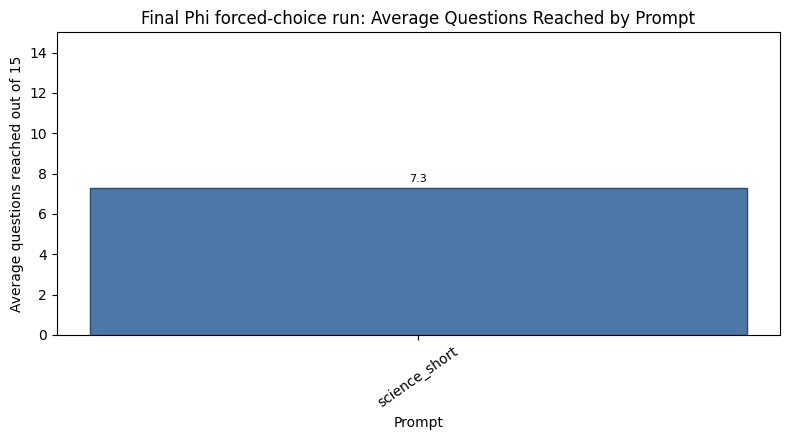

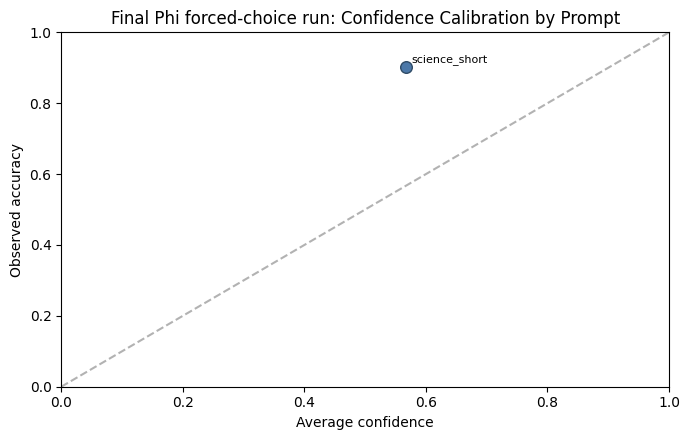

Final Phi forced-choice run: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_final_forced_choice,phi_3_5_mini_final_forced_choice_science_short,science_short,10,7.3,15,6.4,64,0.426667,1.0,108510.0,1024000,0.42235,0.626991,1.0,0.426667,non-thinking


Final Phi forced-choice run: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
0,phi_3_5_mini_final_forced_choice,science_short,Biology & medicine,14,14,0,1.000000,4.214286,7,0.133333
1,phi_3_5_mini_final_forced_choice,science_short,Chemistry & materials,5,5,0,1.000000,2.600000,4,0.083333
4,phi_3_5_mini_final_forced_choice,science_short,People & history of science,1,1,0,1.000000,12.000000,1,0.066667
5,phi_3_5_mini_final_forced_choice,science_short,Physics & astronomy,14,13,1,0.928571,7.428571,7,0.123810
2,phi_3_5_mini_final_forced_choice,science_short,Earth & environment,7,6,1,0.857143,3.428571,5,0.080000
3,phi_3_5_mini_final_forced_choice,science_short,Other science/nature,24,20,4,0.833333,4.958333,9,0.148148
7,phi_3_5_mini_final_forced_choice,science_short,Technology & engineering,4,3,1,0.750000,8.500000,3,0.066667
6,phi_3_5_mini_final_forced_choice,science_short,Scientific method & measurement,4,2,2,0.500000,4.500000,3,0.044444


,model_label,prompt_type,error_type,count
0,phi_3_5_mini_final_forced_choice,science_short,Correct,64
1,phi_3_5_mini_final_forced_choice,science_short,Plausible but incorrect answer,9


Final Phi forced-choice run: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_3_5_mini_final_forced_choice,science_short,73,73,1.0


Final Phi forced-choice run: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_3_5_mini_final_forced_choice,science_short,low (<= 0.40),30,0.733333,0.346276,0.081273,0
1,phi_3_5_mini_final_forced_choice,science_short,medium (0.40-0.70),33,0.969697,0.558028,0.338959,0
2,phi_3_5_mini_final_forced_choice,science_short,high (>= 0.70),10,1.000000,0.798483,0.700885,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
final_phi_analysis = analyse_model_runs(
    df_final_model,
    model_tag="Final Phi forced-choice run",
    output_prefix="science_nature_final_phi_3_5_mini_forced_choice",
    model_type="non-thinking",
)


### Note on Phi calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

In [ ]:
selected_final_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("phi_fixed_comparison"),
        globals().get("phi_ensemble_summary_sorted"),
        globals().get("final_survival_summary"),
    ]
    if isinstance(summary, pd.DataFrame)
]

selected_final_comparison = pd.concat(selected_final_parts, ignore_index=True, sort=False)
selected_final_comparison_sorted = sort_survival_summary(selected_final_comparison)

selected_final_comparison_sorted.to_csv(
    "science_nature_selected_final_comparison.csv",
    index=False,
)

selected_final_comparison_sorted


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.000000,0.866667,phi_3_5_mini_fixed_generation,science_short,non-thinking
13,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline,NaN
14,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short,NaN
15,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert,NaN
16,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination,NaN
17,phi_3_5_mini_forced_choice_science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.000000,0.453333,phi_3_5_mini_forced_choice,science_short,non-thinking
0,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking
20,phi_3_5_mini_final_forced_choice_science_short,10,7.3,15,6.4,64,0.426667,1.000000,108510.0,1024000,0.422350,0.626991,1.000000,0.426667,phi_3_5_mini_final_forced_choice,science_short,non-thinking
1,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking
18,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science,NaN


In [ ]:
df_final_errors = df_final_model[
    df_final_model["correct"] == False
].copy()

df_final_errors["error_type"] = "Plausible but incorrect answer"

if "valid_output" in df_final_errors.columns:
    invalid_mask = df_final_errors["valid_output"] == False
    df_final_errors.loc[invalid_mask, "error_type"] = "Invalid or unparseable output"

if "timed_out" in df_final_errors.columns:
    timeout_mask = df_final_errors["timed_out"] == True
    df_final_errors.loc[timeout_mask, "error_type"] = "Timeout or too slow"

df_final_errors[
    [
        "run_id",
        "level_before_answer",
        "question_text",
        "options",
        "raw_response",
        "selected_option_id",
        "selected_option_text",
        "response_time",
        "error_type",
    ]
]


,run_id,level_before_answer,question_text,options,raw_response,selected_option_id,selected_option_text,response_time,error_type
9,1,10,What is the fundamental principle of Bose-Eins...,"[{""id"": 0, ""text"": ""It predicts that an unlimi...","{""0"": {""score"": -0.33603131771087646, ""tokens""...",2,It describes the distribution of non-interacti...,0.517377,Plausible but incorrect answer
11,2,2,Which of the following best describes the fund...,"[{""id"": 0, ""text"": ""A temperature difference c...","{""0"": {""score"": -0.6270799040794373, ""tokens"":...",2,A thermocouple creates a voltage difference wh...,0.534506,Plausible but incorrect answer
19,3,8,A battery-powered cart pulls an 800-gram load ...,"[{""id"": 0, ""text"": ""move at the same speed""}, ...","{""0"": {""score"": -0.7824676036834717, ""tokens"":...",0,move at the same speed,0.429046,Plausible but incorrect answer
27,4,8,What term describes the quantity that combines...,"[{""id"": 0, ""text"": ""Spacetime""}, {""id"": 1, ""te...","{""0"": {""score"": -0.975969135761261, ""tokens"": ...",1,Lorentz transformation,0.338969,Plausible but incorrect answer
35,5,8,Which best describes the speed of a ball as it...,"[{""id"": 0, ""text"": ""The ball goes up at a cons...","{""0"": {""score"": -0.6515357494354248, ""tokens"":...",3,"The ball goes slower and slower as it goes up,...",0.554820,Plausible but incorrect answer
55,7,5,What term describes a basic proposition or ass...,"[{""id"": 0, ""text"": ""Axiom""}, {""id"": 1, ""text"":...","{""0"": {""score"": -1.073412299156189, ""tokens"": ...",1,Hypothesis,0.379524,Plausible but incorrect answer
66,8,11,Which of the following best describes the rela...,"[{""id"": 0, ""text"": ""Integration is the inverse...","{""0"": {""score"": -0.4259994328022003, ""tokens"":...",0,Integration is the inverse operation of differ...,0.456716,Plausible but incorrect answer
71,9,5,Which of the following is closest to the perce...,"[{""id"": 0, ""text"": ""3%""}, {""id"": 1, ""text"": ""7...","{""0"": {""score"": -0.7286238074302673, ""tokens"":...",1,70%,0.346761,Plausible but incorrect answer
72,10,1,Students measured the elevation changes in a l...,"[{""id"": 0, ""text"": ""topographic map""}, {""id"": ...","{""0"": {""score"": -1.5333157777786255, ""tokens"":...",2,line graph,0.353482,Plausible but incorrect answer


### Error analysis of the final Phi forced-choice check

The final repeated Phi check uses `phi_3_5_mini_final_forced_choice_science_short` over 10 runs. This is not the top saved survival result; the top result remains `phi_3_5_mini_fixed_generation_science_short`. The purpose of this final forced-choice check is to examine answer-selection reliability and confidence behaviour in a more controlled setup.

In this 10-run check, the model reached **7.3 average questions**, achieved a best run of **15 questions**, and kept a valid-output rate of **1.0**. The error table below shows that the remaining failures were normal wrong-answer failures rather than formatting or timeout failures.

In [ ]:
error_type_summary = df_final_errors["error_type"].value_counts().reset_index()
error_type_summary.columns = ["error_type", "count"]

error_type_summary


,error_type,count
0,Plausible but incorrect answer,9


In [ ]:
error_type_summary


,error_type,count
0,Plausible but incorrect answer,9


### Final Phi error interpretation

For the final Phi forced-choice run, all **9** logged errors were labelled as **plausible but incorrect answers**. This means the main limitation in that run was scientific answer selection, not output parsing, invalid formatting, or timeout behaviour.

The confidence coverage was complete: all **73** logged forced-choice questions had confidence scores. The confidence buckets were also interpretable: low-confidence questions had lower observed accuracy, medium-confidence questions were much more accurate, and high-confidence questions were all correct in this saved run. No overconfident errors were recorded in the forced-choice final check.

The topic table suggests that the strongest areas were biology, chemistry, and physics/astronomy, while the weakest topic in this final forced-choice run was scientific method and measurement. This should be discussed as a remaining reasoning/knowledge limitation rather than a system-formatting problem.

In [ ]:
df_final_errors.to_csv("science_nature_final_phi_model_errors.csv", index=False)
error_type_summary.to_csv("science_nature_final_phi_error_type_summary.csv", index=False)

print("Final Phi error analysis saved.")


Final Phi error analysis saved.


## Thinking vs non-thinking models

The assignment asks whether “thinking” models are better than “non-thinking” models.  
To investigate this, we compare the reasoning-oriented DeepSeek model against the non-thinking systems already evaluated, including Qwen and Phi.

This is important because the best system is not necessarily the largest or the most verbose model.


# DeepSeek thinking mode

In [ ]:
import gc
import torch

for variable_name in ["model", "tokenizer", "generator"]:
    if variable_name in globals():
        del globals()[variable_name]

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Previous model cleared.")

Previous model cleared.


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    device_map="auto",
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32
)

generator = make_text_generation_wrapper(model, tokenizer)

if hasattr(model, "generation_config"):
    model.generation_config.max_length = None

print("Loaded thinking model:", model_name)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.55G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Loaded thinking model: deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B


In [ ]:
# Thinking models may include reasoning text, but the answer parser is shared.
extract_option_id_from_response = parse_option_id


In [ ]:
def generate_answer_thinking(question, prompt_type="science_expert"):
    prompt = build_prompt_from_type(question, prompt_type)
    thinking_prompt = f"""
{prompt}

You may reason internally, but the final output must contain only the numeric option ID.
Final answer:
""".strip()

    valid_option_ids = [option.id for option in question.options]
    start_time = time.time()

    option_confidences = estimate_option_confidences(
        formatted_prompt=thinking_prompt,
        valid_option_ids=valid_option_ids,
    )

    output = generator(
        thinking_prompt,
        max_new_tokens=80,
        do_sample=False,
        return_full_text=False,
    )

    response_time = time.time() - start_time
    raw_response = output[0]["generated_text"].strip()
    predicted_id = parse_option_id(raw_response, valid_option_ids)
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_confidences,
        predicted_id,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": thinking_prompt,
        "raw_response": raw_response,
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


In [ ]:
def play_thinking_game(comp_id, prompt_type="science_expert", system_name="thinking_model", delay_seconds=1.5):
    return run_game_with_answer_fn(
        comp_id=comp_id,
        answer_fn=generate_answer_thinking,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=delay_seconds,
    )


In [ ]:
deepseek_prompt_types = PROMPT_TYPES

In [ ]:
def benchmark_thinking_prompt(prompt_type, n_runs=3, delay_seconds=1.5, model_label="deepseek_r1_1_5b"):
    return benchmark_prompt(
        prompt_type=prompt_type,
        n_runs=n_runs,
        delay_seconds=delay_seconds,
        model_label=model_label,
        answer_fn=generate_answer_thinking,
        model_type="thinking",
    )


In [ ]:
experiment_log = []

df_deepseek_test_fixed = benchmark_thinking_prompt(
    prompt_type="science_short",
    n_runs=3,
    delay_seconds=1.5,
    model_label="deepseek_r1_1_5b_fixed",
)

df_deepseek_test_fixed



Running model=deepseek_r1_1_5b_fixed, prompt=science_short, run 1/3


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 331990
System: deepseek_r1_1_5b_fixed_science_short

Level 1
Question: The life cycle of a beetle is similar to the butterfly. Which process changes the beetle from larva to adult?
Raw response: 0
</think>

The life cycle of a beetle is similar to that of a butterfly. To determine the process that changes the beetle from its larva stage to its adult stage, we analyze the options:

1. **Migration**: This refers to movement from one place to another, which is unrelated to life cycle changes.
2. **Molting**: This is the process by which insects like
Submitted: 0
Correct: False
Response time: 4.09 seconds
Game ended.

Running model=deepseek_r1_1_5b_fixed, prompt=science_short, run 2/3
Started game session: 331994
System: deepseek_r1_1_5b_fixed_science_short


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: What is the primary role of cosmic dust in the formation of planets?
Raw response: __________
</think>

The primary role of cosmic dust in the formation of planets is to act as a protective shield. This is because dust particles can block incoming sunlight, preventing the formation of planets by reflecting or absorbing the energy. 

**Answer:** 3
Submitted: 3
Correct: False
Response time: 2.25 seconds
Game ended.

Running model=deepseek_r1_1_5b_fixed, prompt=science_short, run 3/3
Started game session: 331997
System: deepseek_r1_1_5b_fixed_science_short


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: Many birds fly south for the winter. This adaptation is called
Raw response: 0
</think>

The correct answer is **migration**.

**Step-by-Step Explanation:**

1. **Understanding the Question:** The question asks about a bird's adaptation for winter. The options include hibernation, communication, migration, and germination.

2. **Analyzing Each Option:**
   - **Hibernation:** This is a form of winter adaptation, but it
Submitted: 0
Correct: False
Response time: 3.33 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,deepseek_r1_1_5b_fixed_science_short,331990,1,3669,The life cycle of a beetle is similar to the b...,20,"[{""id"": 0, ""text"": ""photosynthesis""}, {""id"": 1...",0,photosynthesis,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.561386,0.312302,"{""0"": 0.5615234375, ""1"": 0.138671875, ""2"": 0.2...",1,deepseek_r1_1_5b_fixed,thinking
1,deepseek_r1_1_5b_fixed_science_short,331994,1,1304,What is the primary role of cosmic dust in the...,13,"[{""id"": 0, ""text"": ""It creates the atmosphere ...",3,It acts as a protective shield for planets,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.094727,-0.332275,"{""0"": 0.427001953125, ""1"": 0.212158203125, ""2""...",2,deepseek_r1_1_5b_fixed,thinking
2,deepseek_r1_1_5b_fixed_science_short,331997,1,5635,Many birds fly south for the winter. This adap...,11,"[{""id"": 0, ""text"": ""hibernation""}, {""id"": 1, ""...",0,hibernation,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.267122,-0.120132,"{""0"": 0.26708984375, ""1"": 0.251953125, ""2"": 0....",3,deepseek_r1_1_5b_fixed,thinking


In [ ]:
deepseek_prompt_results = []

for prompt_type in deepseek_prompt_types:
    df_deepseek_prompt = benchmark_thinking_prompt(
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
        model_label="deepseek_r1_1_5b"
    )

    deepseek_prompt_results.append(df_deepseek_prompt)

df_deepseek_all_prompts = pd.concat(deepseek_prompt_results, ignore_index=True)

df_deepseek_all_prompts.to_csv(
    "science_nature_deepseek_r1_1_5b_all_prompts.csv",
    index=False
)

df_deepseek_all_prompts


Running model=deepseek_r1_1_5b, prompt=baseline, run 1/5
Started game session: 332000
System: deepseek_r1_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: An Earth year is the length of time it takes for
Raw response: 0. Earth to rotate once on its axis
</think>

To determine the length of an Earth year, we need to identify which option correctly describes the time it takes for Earth to complete one full revolution around the Sun.

**Option Analysis:**
1. **The Sun to revolve once around Earth:** This describes the Earth's orbit around the Sun, which is the definition of an Earth year
Submitted: 0
Correct: False
Response time: 3.78 seconds
Game ended.

Running model=deepseek_r1_1_5b, prompt=baseline, run 2/5
Started game session: 332005
System: deepseek_r1_1_5b_baseline


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: What is latent heat?
Raw response: 0
</think>

To determine the correct answer, let's analyze each option:

1. **The energy transferred as heat with a resultant temperature change**: This refers to heat transfer without a phase change, not latent heat.
2. **The energy required to change the temperature of a substance**: This is related to specific heat capacity, not latent heat.
3. **The energy used to increase the
Submitted: 0
Correct: False
Response time: 4.24 seconds
Game ended.

Running model=deepseek_r1_1_5b, prompt=baseline, run 3/5
Started game session: 332010
System: deepseek_r1_1_5b_baseline


...

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: The Sun produces energy through
Raw response: <...>

Okay, so I have this question about the Sun and how it produces energy. Let me think about what I know. The Sun is a star, right? And stars like our Sun burn fuel to produce energy. But wait, how exactly does it do that?

I remember that stars burn fuel through nuclear reactions. Yeah, that's nuclear fusion. So the Sun doesn't use chemical
Submitted: 0
Correct: False
Response time: 3.68 seconds
Game ended.

Running model=deepseek_r1_1_5b, prompt=chain_of_thought, run 5/5
Started game session: 332124
System: deepseek_r1_1_5b_chain_of_thought


The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 1
Question: When Javier exercises, his muscle cells need more oxygen. Which would help Javier's muscle cells receive more oxygen?
Raw response: <...>

Okay, so I'm trying to figure out which action would help Javier's muscle cells receive more oxygen when he exercises. Let me break this down step by step.

First, I know that when you exercise, your body uses more oxygen because muscles need to work harder. So, the muscle cells need more oxygen to function properly. The question is asking which action would help them receive more
Submitted: 0
Correct: False
Response time: 4.2 seconds
Game ended.


,system_name,session_id,level_before_answer,question_id,question_text,question_length,options,selected_option_id,selected_option_text,model_name,...,correct,timed_out,game_over,earned_amount,confidence_score,confidence_margin,option_confidences,run_id,model_label,model_type
0,deepseek_r1_1_5b_baseline,332000,1,6234,An Earth year is the length of time it takes for,11,"[{""id"": 0, ""text"": ""Earth to rotate once on it...",0,Earth to rotate once on its axis,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.433403,0.200464,"{""0"": 0.433349609375, ""1"": 0.23291015625, ""2"":...",1,deepseek_r1_1_5b,thinking
1,deepseek_r1_1_5b_baseline,332005,1,2402,What is latent heat?,4,"[{""id"": 0, ""text"": ""The energy transferred as ...",0,The energy transferred as heat with a resultan...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.516995,0.322329,"{""0"": 0.51708984375, ""1"": 0.1947021484375, ""2""...",2,deepseek_r1_1_5b,thinking
2,deepseek_r1_1_5b_baseline,332010,1,5599,Which event helps to renew a resource?,7,"[{""id"": 0, ""text"": ""A car is filled with gasol...",0,A car is filled with gasoline.,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.769113,0.627865,"{""0"": 0.76904296875, ""1"": 0.0633544921875, ""2""...",3,deepseek_r1_1_5b,thinking
3,deepseek_r1_1_5b_baseline,332013,1,4757,The first microscopes were built in the 1600s....,25,"[{""id"": 0, ""text"": ""They make distant objects ...",0,They make distant objects appear closer.,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.511168,0.291468,"{""0"": 0.51123046875, ""1"": 0.2197265625, ""2"": 0...",4,deepseek_r1_1_5b,thinking
4,deepseek_r1_1_5b_baseline,332019,1,4981,How does the energy in each trophic level of a...,20,"[{""id"": 0, ""text"": ""It has about 20% of the en...",0,It has about 20% of the energy from the level ...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.438179,0.214451,"{""0"": 0.438232421875, ""1"": 0.2237548828125, ""2...",5,deepseek_r1_1_5b,thinking
5,deepseek_r1_1_5b_science_short,332023,1,6585,A medium-sized star in the middle of its life ...,23,"[{""id"": 0, ""text"": ""blue""}, {""id"": 1, ""text"": ...",0,blue,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,NaN,NaN,"{""0"": 0.42236328125, ""1"": 0.1517333984375, ""2""...",1,deepseek_r1_1_5b,thinking
6,deepseek_r1_1_5b_science_short,332027,1,2811,Estuaries are marine environments located in a...,48,"[{""id"": 0, ""text"": ""decreases in powerful hurr...",0,decreases in powerful hurricanes,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,0,0.420629,0.077388,"{""0"": 0.420654296875, ""1"": 0.15771484375, ""2"":...",2,deepseek_r1_1_5b,thinking
7,deepseek_r1_1_5b_science_short,332032,1,3510,Baby chicks peck their way out of their shells...,25,"[{""id"": 0, ""text"": ""instinctive""}, {""id"": 1, ""...",0,instinctive,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.190308,-0.371216,"{""0"": 0.1903076171875, ""1"": 0.17333984375, ""2""...",3,deepseek_r1_1_5b,thinking
8,deepseek_r1_1_5b_science_short,332032,2,2930,Which rapid changes are caused by heat from in...,10,"[{""id"": 0, ""text"": ""avalanches""}, {""id"": 1, ""t...",0,avalanches,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,False,False,True,100,0.504487,0.193639,"{""0"": 0.50439453125, ""1"": 0.1326904296875, ""2""...",3,deepseek_r1_1_5b,thinking
9,deepseek_r1_1_5b_science_short,332038,1,2932,A calculation based on the chemical energy of ...,52,"[{""id"": 0, ""text"": ""the waste heat from the co...",0,the waste heat from the combustion of fuel in ...,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,...,True,False,False,100,0.513641,0.311749,"{""0"": 0.513671875, ""1"": 0.201904296875, ""2"": 0...",4,deepseek_r1_1_5b,thinking


In [ ]:
run_summary_deepseek_all_prompts = make_run_summary(df_deepseek_all_prompts)
survival_summary_deepseek_all_prompts = make_survival_summary(
    df_deepseek_all_prompts,
    model_type="thinking",
)

survival_summary_deepseek_all_prompts


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,deepseek_r1_1_5b,deepseek_r1_1_5b_baseline,baseline,5,1.0,1,0.0,0,0.000000,0.000000,0.0,0,3.382836,4.244998,1.00,0.000000,thinking
1,deepseek_r1_1_5b,deepseek_r1_1_5b_chain_of_thought,chain_of_thought,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,3.809160,4.235751,0.30,0.013333,thinking
2,deepseek_r1_1_5b,deepseek_r1_1_5b_elimination,elimination,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,3.522088,5.732316,0.80,0.053333,thinking
3,deepseek_r1_1_5b,deepseek_r1_1_5b_few_shot_science,few_shot_science,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,2.448314,5.501656,1.00,0.053333,thinking
4,deepseek_r1_1_5b,deepseek_r1_1_5b_science_expert,science_expert,5,2.0,5,1.0,5,0.066667,0.266667,120.0,500,2.580359,4.007628,0.46,0.066667,thinking
5,deepseek_r1_1_5b,deepseek_r1_1_5b_science_short,science_short,5,1.4,2,0.4,2,0.026667,0.066667,40.0,100,2.724191,4.162935,0.80,0.026667,thinking


In [ ]:
survival_summary_deepseek_sorted = survival_summary_deepseek_all_prompts.sort_values(
    by=[
        "average_questions_reached",
        "average_final_earned_amount",
        "average_response_time"
    ],
    ascending=[False, False, True]
)

survival_summary_deepseek_sorted

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,deepseek_r1_1_5b,deepseek_r1_1_5b_science_expert,science_expert,5,2.0,5,1.0,5,0.066667,0.266667,120.0,500,2.580359,4.007628,0.46,0.066667,thinking
3,deepseek_r1_1_5b,deepseek_r1_1_5b_few_shot_science,few_shot_science,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,2.448314,5.501656,1.00,0.053333,thinking
2,deepseek_r1_1_5b,deepseek_r1_1_5b_elimination,elimination,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,3.522088,5.732316,0.80,0.053333,thinking
5,deepseek_r1_1_5b,deepseek_r1_1_5b_science_short,science_short,5,1.4,2,0.4,2,0.026667,0.066667,40.0,100,2.724191,4.162935,0.80,0.026667,thinking
1,deepseek_r1_1_5b,deepseek_r1_1_5b_chain_of_thought,chain_of_thought,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,3.809160,4.235751,0.30,0.013333,thinking
0,deepseek_r1_1_5b,deepseek_r1_1_5b_baseline,baseline,5,1.0,1,0.0,0,0.000000,0.000000,0.0,0,3.382836,4.244998,1.00,0.000000,thinking


In [ ]:
nonthinking_summary_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("phi_fixed_comparison"),
        globals().get("phi_ensemble_summary_sorted"),
    ]
    if isinstance(summary, pd.DataFrame)
]

nonthinking_summary = pd.concat(nonthinking_summary_parts, ignore_index=True, sort=False)
nonthinking_summary["model_type"] = "non-thinking"

thinking_vs_nonthinking_all_prompts = pd.concat(
    [
        nonthinking_summary,
        survival_summary_deepseek_all_prompts,
    ],
    ignore_index=True,
    sort=False,
)

thinking_vs_nonthinking_all_prompts_sorted = sort_survival_summary(thinking_vs_nonthinking_all_prompts)

thinking_vs_nonthinking_all_prompts_sorted


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.000000,0.866667,phi_3_5_mini_fixed_generation,science_short,non-thinking
13,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline,non-thinking
14,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short,non-thinking
15,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert,non-thinking
16,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination,non-thinking
17,phi_3_5_mini_forced_choice_science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.000000,0.453333,phi_3_5_mini_forced_choice,science_short,non-thinking
0,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking
1,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking
18,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science,non-thinking
2,qwen_3b_elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,qwen_3b,elimination,non-thinking


### DeepSeek interpretation

DeepSeek-R1-Distill-Qwen-1.5B performed weakly in the timed Science & Nature game. The best prompt was `science_expert`, but it reached only **2.0 average questions** and **5 / 75 = 0.067 game accuracy**.

The main problem was that the thinking-style output did not improve performance. The model often produced long reasoning or extra text, which slowed responses and caused some invalid outputs. Because it reached very few questions, the topic results should be interpreted cautiously.

Overall, DeepSeek was not suitable for this timed multiple-choice setup. Its confidence scores were also not very reliable, because higher confidence did not consistently match correct answers.


In [ ]:
thinking_vs_nonthinking_all_prompts_sorted.to_csv(
    "science_nature_thinking_vs_nonthinking_all_prompts.csv",
    index=False
)

print("Thinking vs non-thinking all-prompt comparison saved.")

Thinking vs non-thinking all-prompt comparison saved.


In [ ]:
# Shared make_survival_summary is defined once in the summary helper section.
print("Using shared make_survival_summary helper.")


Using shared make_survival_summary helper.


In [ ]:
survival_summary_deepseek_sorted.to_csv(
    "science_nature_deepseek_thinking_summary.csv",
    index=False
)

df_deepseek_all_prompts.to_csv(
    "science_nature_deepseek_all_prompts_raw_results.csv",
    index=False
)
print("DeepSeek thinking model results saved.")

DeepSeek thinking model results saved.


## DeepSeek prompt, topic, error, and confidence analysis

This analysis is placed directly after the DeepSeek runs so the thinking-model results can be interpreted before moving to Gemma.


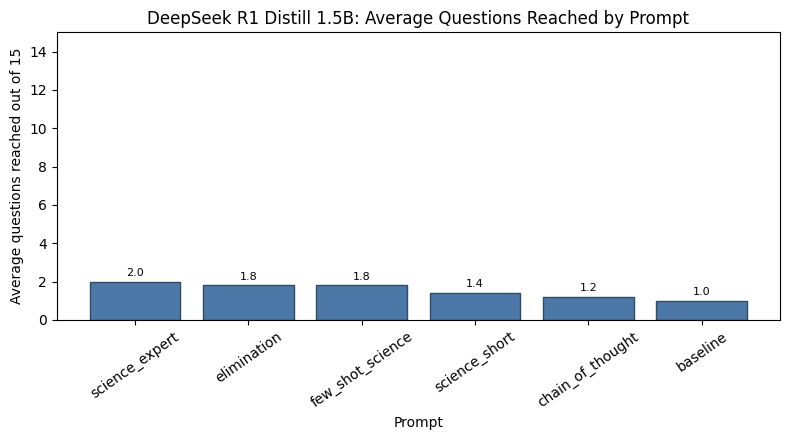

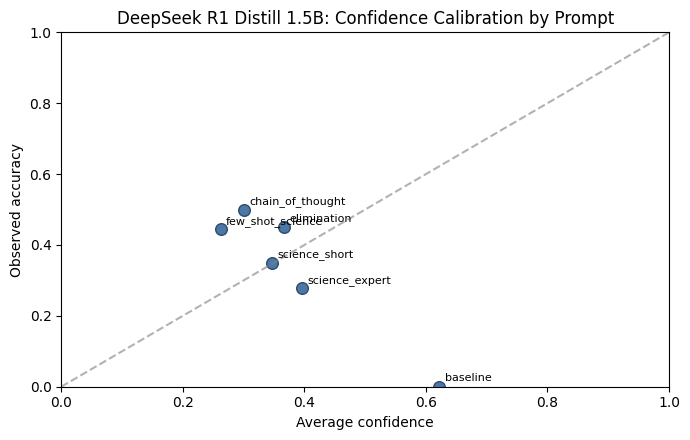

DeepSeek R1 Distill 1.5B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,deepseek_r1_1_5b,deepseek_r1_1_5b_science_expert,science_expert,5,2.0,5,1.0,5,0.066667,0.266667,120.0,500,2.580359,4.007628,0.46,0.066667,thinking
2,deepseek_r1_1_5b,deepseek_r1_1_5b_elimination,elimination,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,3.522088,5.732316,0.80,0.053333,thinking
3,deepseek_r1_1_5b,deepseek_r1_1_5b_few_shot_science,few_shot_science,5,1.8,3,0.8,4,0.053333,0.133333,80.0,200,2.448314,5.501656,1.00,0.053333,thinking
5,deepseek_r1_1_5b,deepseek_r1_1_5b_science_short,science_short,5,1.4,2,0.4,2,0.026667,0.066667,40.0,100,2.724191,4.162935,0.80,0.026667,thinking
1,deepseek_r1_1_5b,deepseek_r1_1_5b_chain_of_thought,chain_of_thought,5,1.2,2,0.2,1,0.013333,0.066667,20.0,100,3.809160,4.235751,0.30,0.013333,thinking
0,deepseek_r1_1_5b,deepseek_r1_1_5b_baseline,baseline,5,1.0,1,0.0,0,0.000000,0.000000,0.0,0,3.382836,4.244998,1.00,0.000000,thinking


DeepSeek R1 Distill 1.5B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
2,deepseek_r1_1_5b,baseline,Physics & astronomy,2,0,2,0.000000,1.00,2,0.000000
0,deepseek_r1_1_5b,baseline,Earth & environment,1,0,1,0.000000,1.00,1,0.000000
1,deepseek_r1_1_5b,baseline,Other science/nature,1,0,1,0.000000,1.00,1,0.000000
3,deepseek_r1_1_5b,baseline,Scientific method & measurement,1,0,1,0.000000,1.00,1,0.000000
6,deepseek_r1_1_5b,chain_of_thought,Other science/nature,1,1,0,1.000000,1.00,1,0.066667
5,deepseek_r1_1_5b,chain_of_thought,Earth & environment,2,0,2,0.000000,1.00,2,0.000000
7,deepseek_r1_1_5b,chain_of_thought,Physics & astronomy,2,0,2,0.000000,1.50,2,0.000000
4,deepseek_r1_1_5b,chain_of_thought,Biology & medicine,1,0,1,0.000000,1.00,1,0.000000
10,deepseek_r1_1_5b,elimination,Earth & environment,1,1,0,1.000000,1.00,1,0.066667
11,deepseek_r1_1_5b,elimination,Other science/nature,1,1,0,1.000000,1.00,1,0.066667


,model_label,prompt_type,error_type,count
0,deepseek_r1_1_5b,baseline,High-confidence wrong answer,1
1,deepseek_r1_1_5b,baseline,Plausible but incorrect answer,4
2,deepseek_r1_1_5b,chain_of_thought,Correct,1
3,deepseek_r1_1_5b,chain_of_thought,Invalid or unparseable output,4
4,deepseek_r1_1_5b,chain_of_thought,Plausible but incorrect answer,1
5,deepseek_r1_1_5b,elimination,Correct,4
6,deepseek_r1_1_5b,elimination,Invalid or unparseable output,1
7,deepseek_r1_1_5b,elimination,Plausible but incorrect answer,4
8,deepseek_r1_1_5b,few_shot_science,Correct,4
9,deepseek_r1_1_5b,few_shot_science,Plausible but incorrect answer,5


DeepSeek R1 Distill 1.5B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,deepseek_r1_1_5b,baseline,5,5,1.0
1,deepseek_r1_1_5b,chain_of_thought,6,6,1.0
2,deepseek_r1_1_5b,elimination,9,9,1.0
3,deepseek_r1_1_5b,few_shot_science,9,9,1.0
4,deepseek_r1_1_5b,science_expert,10,10,1.0
5,deepseek_r1_1_5b,science_short,7,7,1.0


DeepSeek R1 Distill 1.5B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,deepseek_r1_1_5b,baseline,low (<= 0.40),0,NaN,NaN,NaN,0
1,deepseek_r1_1_5b,baseline,medium (0.40-0.70),4,0.000000,0.474936,0.257178,0
2,deepseek_r1_1_5b,baseline,high (>= 0.70),1,0.000000,0.769113,0.627865,1
3,deepseek_r1_1_5b,chain_of_thought,low (<= 0.40),5,0.000000,0.135651,-0.328438,0
4,deepseek_r1_1_5b,chain_of_thought,medium (0.40-0.70),1,1.000000,0.465735,0.119607,0
5,deepseek_r1_1_5b,chain_of_thought,high (>= 0.70),0,NaN,NaN,NaN,0
6,deepseek_r1_1_5b,elimination,low (<= 0.40),4,0.500000,0.152494,-0.399304,0
7,deepseek_r1_1_5b,elimination,medium (0.40-0.70),5,0.400000,0.581024,0.396756,0
8,deepseek_r1_1_5b,elimination,high (>= 0.70),0,NaN,NaN,NaN,0
9,deepseek_r1_1_5b,few_shot_science,low (<= 0.40),9,0.444444,0.262168,-0.108142,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
2,deepseek_r1_1_5b,baseline,deepseek_r1_1_5b_baseline,3,1,Other science/nature,Which event helps to renew a resource?,A car is filled with gasoline.,0\n</think>\n\nThe event that helps to renew a...,0.769113,0.627865,"{""0"": 0.76904296875, ""1"": 0.0633544921875, ""2""...",False


In [ ]:
deepseek_analysis = analyse_model_runs(
    df_deepseek_all_prompts,
    model_tag="DeepSeek R1 Distill 1.5B",
    output_prefix="science_nature_deepseek_r1_1_5b",
    model_type="thinking",
)


### Note on DeepSeek calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

In [ ]:
nonthinking_summary_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("phi_fixed_comparison"),
        globals().get("phi_ensemble_summary_sorted"),
    ]
    if isinstance(summary, pd.DataFrame)
]

qwen_phi_summary_for_thinking = pd.concat(nonthinking_summary_parts, ignore_index=True, sort=False)
qwen_phi_summary_for_thinking["model_type"] = "non-thinking"

thinking_vs_nonthinking_summary = pd.concat(
    [
        qwen_phi_summary_for_thinking,
        survival_summary_deepseek_sorted,
    ],
    ignore_index=True,
    sort=False,
)

thinking_vs_nonthinking_summary_sorted = sort_survival_summary(thinking_vs_nonthinking_summary)

thinking_vs_nonthinking_summary_sorted


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.000000,0.866667,phi_3_5_mini_fixed_generation,science_short,non-thinking
13,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline,non-thinking
14,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short,non-thinking
15,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert,non-thinking
16,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination,non-thinking
17,phi_3_5_mini_forced_choice_science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.000000,0.453333,phi_3_5_mini_forced_choice,science_short,non-thinking
0,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking
1,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking
18,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science,non-thinking
2,qwen_3b_elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,qwen_3b,elimination,non-thinking


### DeepSeek error and confidence conclusion

DeepSeek-R1-Distill-Qwen-1.5B performed weakly, with the best prompt `science_expert` reaching only **2.0 average questions** and **5 / 75 = 0.067 game accuracy**.

Most errors were either **plausible but incorrect answers** or **invalid/unparseable outputs**, showing that the thinking-style responses did not fit the timed multiple-choice format well. Errors appeared across several topics, so the weakness was not limited to one subject.

Confidence was available for all questions, but it was not very reliable. Higher confidence did not consistently match higher accuracy, and there was one high-confidence wrong answer. Overall, DeepSeek was not suitable for this task.


In [ ]:
thinking_vs_nonthinking_summary_sorted.to_csv(
    "science_nature_thinking_vs_nonthinking_summary.csv",
    index=False
)

print("Thinking vs non-thinking comparison saved.")

Thinking vs non-thinking comparison saved.


# Gemma

Gemma is kept as an optional model family. In this runtime it has been unstable, so the default setting skips Gemma and lets the rest of the notebook continue.


In [ ]:
import os
import subprocess
import sys


try:
    from huggingface_hub import login
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])
    from huggingface_hub import login

hf_token = os.environ.get("HF_TOKEN")

try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN") or hf_token
except Exception:
    pass

if not hf_token:
    raise ValueError(
        "HF_TOKEN was not found. Add it in Colab Secrets, then rerun this cell."
    )

login(token=hf_token, add_to_git_credential=False)
print("Hugging Face login complete.")


Hugging Face login complete.


In [ ]:
import gc
import subprocess
import sys
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM


def clear_loaded_model():
    global model, tokenizer, generator

    for variable_name in ["model", "tokenizer", "generator"]:
        if variable_name in globals():
            del globals()[variable_name]

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def choose_model_dtype():
    if torch.cuda.is_available():
        major, _ = torch.cuda.get_device_capability()
        return torch.bfloat16 if major >= 8 else torch.float16

    return torch.float32


def load_chat_model(model_id, model_label=None, use_4bit=False):
    global model, tokenizer, model_name, current_model_label

    clear_loaded_model()

    model_name = model_id
    current_model_label = model_label or model_id.split("/")[-1].replace("-", "_")
    dtype = choose_model_dtype()

    auth_kwargs = {"token": hf_token} if hf_token else {}
    load_kwargs = {
        "device_map": "auto",
        "torch_dtype": dtype,
        **auth_kwargs,
    }

    # Gemma 2 is more stable in Colab with eager attention.
    if "gemma-2" in model_id.lower():
        load_kwargs["attn_implementation"] = "eager"

    if use_4bit:
        try:
            from transformers import BitsAndBytesConfig
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes", "accelerate"])
            from transformers import BitsAndBytesConfig

        load_kwargs["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True,
            bnb_4bit_compute_dtype=dtype,
        )

    tokenizer = AutoTokenizer.from_pretrained(model_id, **auth_kwargs)
    model = AutoModelForCausalLM.from_pretrained(model_id, **load_kwargs)
    model.eval()

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    print("Loaded model:", model_name)
    print("Model label:", current_model_label)
    print("4-bit loading:", use_4bit)
    print("dtype:", dtype)


In [ ]:

def generate_answer_scored_options(question, prompt_type="science_short"):
    prompt = build_prompt_from_type(question, prompt_type)
    formatted_prompt = format_model_prompt(prompt)
    base_text = formatted_prompt + "\nThe correct answer is option"
    start_time = time.time()

    option_scores = {}

    for option in question.options:
        candidate_text = f" {option.id}: {option.text}"
        option_scores[int(option.id)] = score_candidate_continuation_generic(
            base_text,
            candidate_text,
        )

    predicted_id = max(option_scores, key=option_scores.get)
    response_time = time.time() - start_time
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_scores,
        predicted_id,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": prompt,
        "raw_response": json.dumps(option_scores, ensure_ascii=False),
        "predicted_id": predicted_id,
        "response_time": response_time,
        "option_confidences": option_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


In [ ]:
def play_prompt_game_with_answer_fn(
    comp_id,
    answer_fn,
    prompt_type="science_short",
    system_name="system",
    delay_seconds=1.5,
):
    return run_game_with_answer_fn(
        comp_id=comp_id,
        answer_fn=answer_fn,
        prompt_type=prompt_type,
        system_name=system_name,
        delay_seconds=delay_seconds,
    )


# benchmark_answer_fn is defined once in the shared benchmark helper section.


In [ ]:
RUN_GEMMA = True


gemma_model_id = "google/gemma-2-2b-it"
gemma_model_label = "gemma_2_2b_it"

try:
    load_chat_model(
        model_id=gemma_model_id,
        model_label=gemma_model_label,
        use_4bit=False,
    )

    model.eval()

    if hasattr(model.config, "use_cache"):
        model.config.use_cache = False

    if hasattr(model, "generation_config"):
        model.generation_config.use_cache = False

    GEMMA_AVAILABLE = True
    print("Gemma loaded successfully without transformers.pipeline.")

except Exception as gemma_error:
    GEMMA_AVAILABLE = False
    RUN_GEMMA = False
    df_gemma_prompts = pd.DataFrame()
    gemma_survival_summary = pd.DataFrame()
    gemma_survival_summary_sorted = pd.DataFrame()

    print("Gemma could not be loaded in this runtime.")
    print("This is usually a Colab package/runtime problem, not a notebook logic problem.")
    print("Error type:", type(gemma_error).__name__)
    print("Error message:", gemma_error)
    print("Recommended fix: restart runtime, make sure the notebook has no `pipeline` import, then rerun from the top.")


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded model: google/gemma-2-2b-it
Model label: gemma_2_2b_it
4-bit loading: False
dtype: torch.float16
Gemma loaded successfully without transformers.pipeline.


In [ ]:
if globals().get("GEMMA_AVAILABLE", False):
    gemma_prompt_results = []

    for prompt_type in PROMPT_TYPES:
        df_gemma_prompt = benchmark_answer_fn(
            answer_fn=generate_answer_chat_template_with_confidence,
            model_label=gemma_model_label,
            prompt_type=prompt_type,
            n_runs=5,
            delay_seconds=1.5,
        )
        gemma_prompt_results.append(df_gemma_prompt)

    df_gemma_prompts = pd.concat(gemma_prompt_results, ignore_index=True)

    gemma_survival_summary = make_survival_summary(df_gemma_prompts)
    gemma_survival_summary_sorted = gemma_survival_summary.sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )
else:
    df_gemma_prompts = pd.DataFrame()
    gemma_survival_summary = pd.DataFrame()
    gemma_survival_summary_sorted = pd.DataFrame()

gemma_survival_summary_sorted



Running model=gemma_2_2b_it, prompt=baseline, run 1/5


The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Started game session: 332782
System: gemma_2_2b_it_baseline

Level 1
Question: Which instrument would be used when studying a unit on amphibian anatomy?
Raw response: 1
Submitted: 1
Correct: True
Response time: 0.4 seconds


The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 2
Question: The cycle of night and day on Earth is a result of
Raw response: 3
Submitted: 3
Correct: True
Response time: 0.31 seconds


...

The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 4
Question: To pump blood through the body, the heart must overcome the force of gravity. Which body position would require the least work from the heart?
Raw response: Reasoning: Gravity is strongest when standing upright.  Lying down minimizes the force of gravity on the heart.

Final answer: 2
Submitted: 2
Correct: True
Response time: 2.75 seconds


The following generation flags are not valid and may be ignored: ['cache_implementation']. Set `TRANSFORMERS_VERBOSITY=info` for more details.



Level 5
Question: What is the main component of shellac secreted by the lac bug?
Raw response: Reasoning: Shellac is a resin, and the lac bug produces it. 

Final answer: 0
Submitted: 0
Correct: False
Response time: 1.92 seconds
Game ended.


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,gemma_2_2b_it,gemma_2_2b_it_few_shot_science,few_shot_science,5,6.6,15,5.8,29,0.386667,1.000000,211280.0,1024000,0.542497,0.722529,1.0,0.386667,non-thinking
0,gemma_2_2b_it,gemma_2_2b_it_baseline,baseline,5,6.0,9,5.0,25,0.333333,0.533333,2260.0,8000,0.357397,0.466021,1.0,0.333333,non-thinking
5,gemma_2_2b_it,gemma_2_2b_it_science_short,science_short,5,6.0,7,5.0,25,0.333333,0.400000,1100.0,2000,0.357708,0.473136,1.0,0.333333,non-thinking
4,gemma_2_2b_it,gemma_2_2b_it_science_expert,science_expert,5,5.8,12,4.8,24,0.320000,0.733333,13260.0,64000,0.368996,0.474089,1.0,0.320000,non-thinking
2,gemma_2_2b_it,gemma_2_2b_it_elimination,elimination,5,4.8,9,3.8,19,0.253333,0.533333,2100.0,8000,0.351758,0.476878,1.0,0.253333,non-thinking
1,gemma_2_2b_it,gemma_2_2b_it_chain_of_thought,chain_of_thought,5,4.2,10,3.2,16,0.213333,0.600000,3360.0,16000,3.925796,6.960468,1.0,0.213333,non-thinking


In [ ]:
if globals().get("GEMMA_AVAILABLE", False) and not gemma_survival_summary_sorted.empty:
    gemma_survival_summary_sorted.to_csv(
        "science_nature_gemma_prompt_summary.csv",
        index=False,
    )
    df_gemma_prompts.to_csv(
        "science_nature_gemma_question_level_results.csv",
        index=False,
    )
else:
    print("No Gemma result files were saved because Gemma was skipped.")

available_gemma_parts = []

if "thinking_vs_nonthinking_summary_sorted" in globals() and isinstance(thinking_vs_nonthinking_summary_sorted, pd.DataFrame):
    available_gemma_parts.append(thinking_vs_nonthinking_summary_sorted)

if globals().get("GEMMA_AVAILABLE", False) and not gemma_survival_summary_sorted.empty:
    available_gemma_parts.append(gemma_survival_summary_sorted)

final_with_gemma = pd.concat(
    available_gemma_parts,
    ignore_index=True,
    sort=False,
) if available_gemma_parts else pd.DataFrame()

if not final_with_gemma.empty:
    final_with_gemma = final_with_gemma.sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )

final_with_gemma.to_csv(
    "science_nature_final_summary_with_optional_gemma.csv",
    index=False,
)

final_with_gemma


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
0,phi_3_5_mini_fixed_generation_science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.000000,0.866667,phi_3_5_mini_fixed_generation,science_short,non-thinking
1,phi_3_mini_baseline,5,11.2,15,10.4,52,0.693333,1.000000,313620.0,1024000,0.435798,1.130582,1.000000,0.693333,phi_3_mini,baseline,non-thinking
2,phi_3_mini_science_short,5,9.0,15,8.2,41,0.546667,1.000000,212020.0,1024000,0.434985,1.119313,1.000000,0.546667,phi_3_mini,science_short,non-thinking
3,phi_3_mini_science_expert,5,8.6,15,7.8,39,0.520000,1.000000,256600.0,1024000,0.523250,1.212849,0.958095,0.520000,phi_3_mini,science_expert,non-thinking
4,phi_3_mini_elimination,5,8.6,15,7.8,39,0.520000,1.000000,217680.0,1024000,0.466812,1.226471,0.981818,0.520000,phi_3_mini,elimination,non-thinking
5,phi_3_5_mini_forced_choice_science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.000000,0.453333,phi_3_5_mini_forced_choice,science_short,non-thinking
6,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking
7,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking
8,phi_3_mini_few_shot_science,5,7.2,11,6.2,31,0.413333,0.666667,13400.0,32000,0.875882,0.914915,1.000000,0.413333,phi_3_mini,few_shot_science,non-thinking
26,gemma_2_2b_it_few_shot_science,5,6.6,15,5.8,29,0.386667,1.000000,211280.0,1024000,0.542497,0.722529,1.000000,0.386667,gemma_2_2b_it,few_shot_science,non-thinking


## Gemma prompt, topic, error, and confidence analysis

This cell analyses Gemma immediately after its prompt benchmark and before moving to Llama.


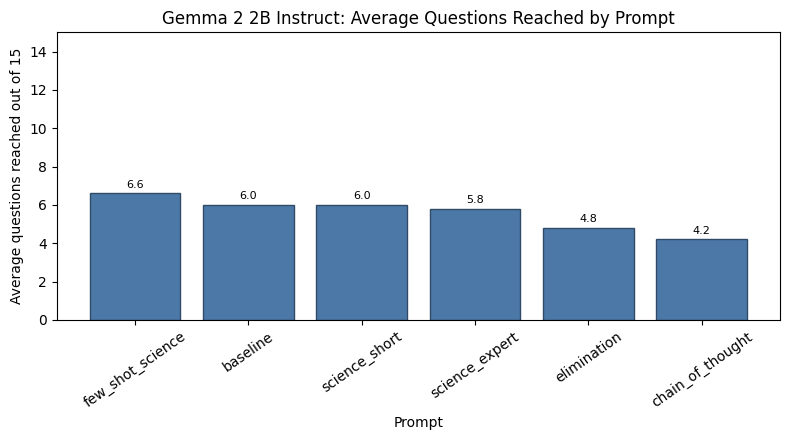

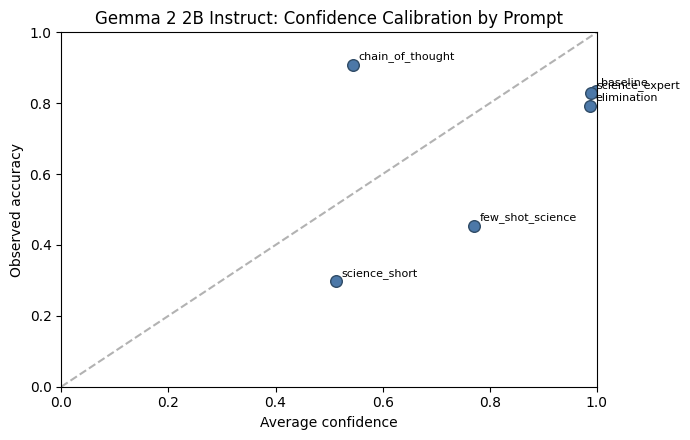

Gemma 2 2B Instruct: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
3,gemma_2_2b_it,gemma_2_2b_it_few_shot_science,few_shot_science,5,6.6,15,5.8,29,0.386667,1.000000,211280.0,1024000,0.542497,0.722529,1.0,0.386667,non-thinking
0,gemma_2_2b_it,gemma_2_2b_it_baseline,baseline,5,6.0,9,5.0,25,0.333333,0.533333,2260.0,8000,0.357397,0.466021,1.0,0.333333,non-thinking
5,gemma_2_2b_it,gemma_2_2b_it_science_short,science_short,5,6.0,7,5.0,25,0.333333,0.400000,1100.0,2000,0.357708,0.473136,1.0,0.333333,non-thinking
4,gemma_2_2b_it,gemma_2_2b_it_science_expert,science_expert,5,5.8,12,4.8,24,0.320000,0.733333,13260.0,64000,0.368996,0.474089,1.0,0.320000,non-thinking
2,gemma_2_2b_it,gemma_2_2b_it_elimination,elimination,5,4.8,9,3.8,19,0.253333,0.533333,2100.0,8000,0.351758,0.476878,1.0,0.253333,non-thinking
1,gemma_2_2b_it,gemma_2_2b_it_chain_of_thought,chain_of_thought,5,4.2,10,3.2,16,0.213333,0.600000,3360.0,16000,3.925796,6.960468,1.0,0.213333,non-thinking


Gemma 2 2B Instruct: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
3,gemma_2_2b_it,baseline,Other science/nature,6,6,0,1.000000,3.666667,3,0.133333
5,gemma_2_2b_it,baseline,Physics & astronomy,3,3,0,1.000000,5.333333,1,0.200000
1,gemma_2_2b_it,baseline,Chemistry & materials,2,2,0,1.000000,1.000000,2,0.066667
6,gemma_2_2b_it,baseline,Scientific method & measurement,1,1,0,1.000000,2.000000,1,0.066667
0,gemma_2_2b_it,baseline,Biology & medicine,7,6,1,0.857143,3.571429,5,0.080000
2,gemma_2_2b_it,baseline,Earth & environment,8,6,2,0.750000,4.125000,5,0.080000
7,gemma_2_2b_it,baseline,Technology & engineering,2,1,1,0.500000,3.000000,2,0.033333
4,gemma_2_2b_it,baseline,People & history of science,1,0,1,0.000000,7.000000,1,0.000000
9,gemma_2_2b_it,chain_of_thought,Chemistry & materials,4,4,0,1.000000,5.750000,2,0.133333
11,gemma_2_2b_it,chain_of_thought,Other science/nature,4,4,0,1.000000,3.250000,3,0.088889


,model_label,prompt_type,error_type,count
0,gemma_2_2b_it,baseline,Correct,25
1,gemma_2_2b_it,baseline,High-confidence wrong answer,5
2,gemma_2_2b_it,chain_of_thought,Correct,16
3,gemma_2_2b_it,chain_of_thought,Plausible but incorrect answer,5
4,gemma_2_2b_it,elimination,Correct,19
5,gemma_2_2b_it,elimination,High-confidence wrong answer,5
6,gemma_2_2b_it,few_shot_science,Correct,29
7,gemma_2_2b_it,few_shot_science,High-confidence wrong answer,3
8,gemma_2_2b_it,few_shot_science,Plausible but incorrect answer,1
9,gemma_2_2b_it,science_expert,Correct,24


Gemma 2 2B Instruct: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,gemma_2_2b_it,baseline,30,30,1.0
1,gemma_2_2b_it,chain_of_thought,21,21,1.0
2,gemma_2_2b_it,elimination,24,24,1.0
3,gemma_2_2b_it,few_shot_science,33,33,1.0
4,gemma_2_2b_it,science_expert,29,29,1.0
5,gemma_2_2b_it,science_short,30,30,1.0


Gemma 2 2B Instruct: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,gemma_2_2b_it,baseline,low (<= 0.40),0,NaN,NaN,NaN,0
1,gemma_2_2b_it,baseline,medium (0.40-0.70),0,NaN,NaN,NaN,0
2,gemma_2_2b_it,baseline,high (>= 0.70),30,0.833333,0.998202,0.996748,5
3,gemma_2_2b_it,chain_of_thought,low (<= 0.40),18,0.722222,0.068352,-0.742545,0
4,gemma_2_2b_it,chain_of_thought,medium (0.40-0.70),1,1.000000,0.657635,0.385695,0
5,gemma_2_2b_it,chain_of_thought,high (>= 0.70),2,1.000000,0.908475,0.852705,0
6,gemma_2_2b_it,elimination,low (<= 0.40),0,NaN,NaN,NaN,0
7,gemma_2_2b_it,elimination,medium (0.40-0.70),0,NaN,NaN,NaN,0
8,gemma_2_2b_it,elimination,high (>= 0.70),24,0.791667,0.987443,0.978938,5
9,gemma_2_2b_it,few_shot_science,low (<= 0.40),0,NaN,NaN,NaN,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
138,gemma_2_2b_it,few_shot_science,gemma_2_2b_it_few_shot_science,2,11,Other science/nature,What is the fundamental principle of the Pytha...,It states that the sum of the lengths of the t...,1,0.999994,0.999990,"{""0"": 1.3113021850585938e-06, ""1"": 1.0, ""2"": 3...",False
144,gemma_2_2b_it,few_shot_science,gemma_2_2b_it_few_shot_science,4,2,Physics & astronomy,The phases of the Moon are caused by the,tilt of the Moon.,1,0.999774,0.999571,"{""0"": 0.0002033710479736328, ""1"": 1.0, ""2"": 1....",False
70,gemma_2_2b_it,science_expert,gemma_2_2b_it_science_expert,3,6,Earth & environment,What is the primary reason the butterfly effec...,The non-linearity of the Earth's atmosphere,1,0.999765,0.999617,"{""0"": 0.00014770030975341797, ""1"": 1.0, ""2"": 7...",False
4,gemma_2_2b_it,baseline,gemma_2_2b_it_baseline,1,5,Technology & engineering,What was the main reason Teilhard de Chardin w...,He was criticized for his religious beliefs,2,0.999544,0.999287,"{""0"": 7.30752944946289e-05, ""1"": 0.00025701522...",False
17,gemma_2_2b_it,baseline,gemma_2_2b_it_baseline,3,9,Biology & medicine,Organisms have many methods of surviving winte...,Robins fly from Michigan to Georgia in the fall.,3,0.999458,0.999184,"{""0"": 0.00015473365783691406, ""1"": 0.000273704...",False
53,gemma_2_2b_it,science_short,gemma_2_2b_it_science_short,4,6,Biology & medicine,A scientist uses a special chemical marker to ...,a lipid in a membrane,2,0.999366,0.998901,"{""0"": 3.069639205932617e-05, ""1"": 0.0004653930...",False
92,gemma_2_2b_it,elimination,gemma_2_2b_it_elimination,2,3,Biology & medicine,A scientist crosses a red-flowered plant with ...,All of the offspring will have red flowers.,2,0.999222,0.998610,"{""0"": 9.828805923461914e-05, ""1"": 0.0006117820...",False
29,gemma_2_2b_it,baseline,gemma_2_2b_it_baseline,5,5,Earth & environment,The air in front of a meteor is compressed as ...,gain velocity.,1,0.999111,0.998439,"{""0"": 0.0006718635559082031, ""1"": 0.9990234375...",False
34,gemma_2_2b_it,science_short,gemma_2_2b_it_science_short,1,5,Biology & medicine,Plants that can live in sandy soils most likel...,salt.,2,0.998758,0.997915,"{""0"": 0.00010877847671508789, ""1"": 0.000291109...",False
89,gemma_2_2b_it,elimination,gemma_2_2b_it_elimination,1,1,Biology & medicine,A scientist is trying to decide whether an org...,size of the cells of the organism,3,0.998691,0.998108,"{""0"": 0.00015103816986083984, ""1"": 0.000574588...",False


In [ ]:
if globals().get("GEMMA_AVAILABLE", False) and not df_gemma_prompts.empty:
    gemma_analysis = analyse_model_runs(
        df_gemma_prompts,
        model_tag="Gemma 2 2B Instruct",
        output_prefix="science_nature_gemma_2_2b_it",
        model_type="non-thinking",
    )
else:
    gemma_analysis = {}
    print("Gemma analysis skipped because Gemma did not run.")


### Gemma comparison, error, and confidence interpretation

Gemma was a useful additional model-family comparison, but it did not beat the best Phi systems. The best Gemma configuration was `gemma_2_2b_it_few_shot_science`, with **6.6 average questions reached**, a best run of **15 questions**, game accuracy of **29 / 75 = 0.387**, and a valid-output rate of **1.0**.

This made Gemma competitive with the Qwen baselines and slightly stronger than the best Qwen 1.5B result, but still below the best Qwen 3B and far below the best Phi-3.5-mini fixed-generation result. The chain-of-thought prompt was slower and weaker, supporting the wider finding that long reasoning prompts were not consistently useful in this timed setting.

By topic, Gemma performed well in **Other science/nature**, **Chemistry & materials**, **Earth & environment**, and some **Scientific method & measurement** questions. More errors appeared in **Biology & medicine**, **Physics & astronomy**, and **Technology & engineering**. The confidence analysis also shows overconfidence: confidence was available for all prompts, but several wrong answers still had very high confidence. Therefore, Gemma follows the answer format well, but its confidence scores should be interpreted carefully.

### Note on Gemma calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

# Llama model comparison

The accepted repository is the **base** Llama 3 8B checkpoint, the fairer first test is forced-choice scoring rather than free-form generation. The base model is not instruction-tuned, so asking it to emit only `0`, `1`, `2`, or `3` can be unreliable. Forced-choice scoring asks: "which answer option is most likely under the model?"



In [ ]:
llama_model_id = "meta-llama/Meta-Llama-3-8B"
llama_model_label = "llama_3_8b_forced_choice"

# Llama 3 8B is much larger than Gemma 2B, so 4-bit loading is recommended for Colab.
load_chat_model(
    model_id=llama_model_id,
    model_label=llama_model_label,
    use_4bit=True,
)


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/73.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

...

model-00004-of-00004.safetensors:   0%|          | 0.00/1.17G [00:00<?, ?B/s]

model-00002-of-00004.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/177 [00:00<?, ?B/s]

Loaded model: meta-llama/Meta-Llama-3-8B
Model label: llama_3_8b_forced_choice
4-bit loading: True
dtype: torch.float16


In [ ]:
llama_prompt_results = []

for prompt_type in LLAMA_PROMPT_TYPES:
    df_llama_prompt = benchmark_answer_fn(
        answer_fn=generate_answer_scored_options,
        model_label=llama_model_label,
        prompt_type=prompt_type,
        n_runs=5,
        delay_seconds=1.5,
    )
    llama_prompt_results.append(df_llama_prompt)

df_llama_prompts = pd.concat(llama_prompt_results, ignore_index=True)

llama_survival_summary = make_survival_summary(df_llama_prompts)
llama_survival_summary_sorted = llama_survival_summary.sort_values(
    by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
    ascending=False,
)

llama_survival_summary_sorted



Running model=llama_3_8b_forced_choice, prompt=science_short, run 1/5
Started game session: 333897
System: llama_3_8b_forced_choice_science_short

Level 1
Question: When the Northern Hemisphere is tilted toward the Sun, what season is occurring in Australia?
Raw response: {"0": -1.3107794523239136, "1": -0.8664745092391968, "2": -0.9622929096221924, "3": -1.4025557041168213}
Submitted: 1
Correct: True
Response time: 1.91 seconds

Level 2
Question: There is a thunderstorm close to your house. The windows rattle at the same time that you hear the thunder. What causes the windows to rattle?
Raw response: {"0": -0.7610721588134766, "1": -0.435932457447052, "2": -1.5693495273590088, "3": -0.8250809907913208}
Submitted: 1
Correct: True
Response time: 1.47 seconds

Level 3
Question: A grocery company found a way to keep fresh foods from spoiling when transporting them long distances. How might this new technology help people in Hawaii?
Raw response: {"0": -0.8170261979103088, "1": -0.3926841

,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,llama_3_8b_forced_choice,llama_3_8b_forced_choice_science_short,science_short,5,4.8,7,3.8,19,0.253333,0.400000,860.0,2000,1.377770,2.924235,1.0,0.253333,non-thinking
1,llama_3_8b_forced_choice,llama_3_8b_forced_choice_elimination,elimination,5,3.6,8,2.6,13,0.173333,0.466667,940.0,4000,1.186233,1.474538,1.0,0.173333,non-thinking
3,llama_3_8b_forced_choice,llama_3_8b_forced_choice_science_expert,science_expert,5,2.2,4,1.2,6,0.080000,0.200000,120.0,300,1.216740,1.303566,1.0,0.080000,non-thinking
2,llama_3_8b_forced_choice,llama_3_8b_forced_choice_few_shot_science,few_shot_science,5,2.0,4,1.0,5,0.066667,0.200000,100.0,300,1.671119,1.738896,1.0,0.066667,non-thinking
0,llama_3_8b_forced_choice,llama_3_8b_forced_choice_chain_of_thought,chain_of_thought,5,1.4,3,0.4,2,0.026667,0.133333,40.0,200,1.443963,2.075348,1.0,0.026667,non-thinking


In [ ]:
llama_survival_summary_sorted.to_csv(
    "science_nature_llama_prompt_summary.csv",
    index=False,
)
df_llama_prompts.to_csv(
    "science_nature_llama_question_level_results.csv",
    index=False,
)

available_family_summaries = []

for summary_name in [
    "qwen_comparison_summary_sorted",
    "gemma_survival_summary_sorted",
    "llama_survival_summary_sorted",
]:
    if summary_name in globals():
        summary = globals()[summary_name].copy()
        summary["summary_source"] = summary_name
        available_family_summaries.append(summary)

model_family_comparison = pd.concat(
    available_family_summaries,
    ignore_index=True,
    sort=False,
).sort_values(
    by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
    ascending=False,
)

model_family_comparison.to_csv(
    "science_nature_model_family_comparison.csv",
    index=False,
)

model_family_comparison


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type,summary_source
0,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking,qwen_comparison_summary_sorted
1,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking,qwen_comparison_summary_sorted
12,gemma_2_2b_it_few_shot_science,5,6.6,15,5.8,29,0.386667,1.000000,211280.0,1024000,0.542497,0.722529,1.000000,0.386667,gemma_2_2b_it,few_shot_science,non-thinking,gemma_survival_summary_sorted
2,qwen_3b_elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,qwen_3b,elimination,non-thinking,qwen_comparison_summary_sorted
3,qwen_1_5b_baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.000000,0.333333,qwen_1_5b,baseline,NaN,qwen_comparison_summary_sorted
13,gemma_2_2b_it_baseline,5,6.0,9,5.0,25,0.333333,0.533333,2260.0,8000,0.357397,0.466021,1.000000,0.333333,gemma_2_2b_it,baseline,non-thinking,gemma_survival_summary_sorted
14,gemma_2_2b_it_science_short,5,6.0,7,5.0,25,0.333333,0.400000,1100.0,2000,0.357708,0.473136,1.000000,0.333333,gemma_2_2b_it,science_short,non-thinking,gemma_survival_summary_sorted
15,gemma_2_2b_it_science_expert,5,5.8,12,4.8,24,0.320000,0.733333,13260.0,64000,0.368996,0.474089,1.000000,0.320000,gemma_2_2b_it,science_expert,non-thinking,gemma_survival_summary_sorted
4,qwen_3b_science_short,5,5.2,9,4.2,21,0.280000,0.533333,2800.0,8000,0.182907,0.247055,1.000000,0.280000,qwen_3b,science_short,non-thinking,qwen_comparison_summary_sorted
5,qwen_1_5b_elimination,5,5.0,7,4.0,20,0.266667,0.400000,900.0,2000,0.130808,0.188780,1.000000,0.266667,qwen_1_5b,elimination,NaN,qwen_comparison_summary_sorted


## Llama prompt, topic, error, and confidence analysis

This cell analyses Llama immediately after its forced-choice prompt benchmark.


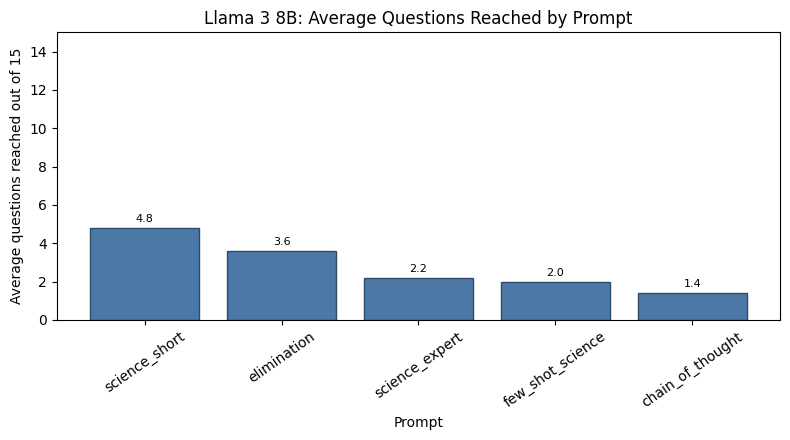

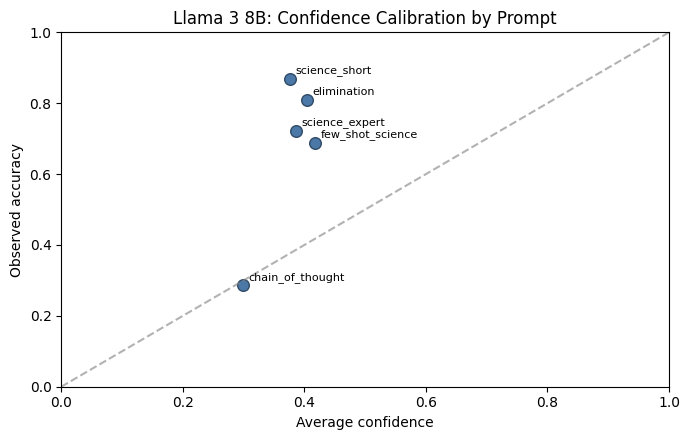

Llama 3 8B: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,llama_3_8b_forced_choice,llama_3_8b_forced_choice_science_short,science_short,5,4.8,7,3.8,19,0.253333,0.400000,860.0,2000,1.377770,2.924235,1.0,0.253333,non-thinking
1,llama_3_8b_forced_choice,llama_3_8b_forced_choice_elimination,elimination,5,3.6,8,2.6,13,0.173333,0.466667,940.0,4000,1.186233,1.474538,1.0,0.173333,non-thinking
3,llama_3_8b_forced_choice,llama_3_8b_forced_choice_science_expert,science_expert,5,2.2,4,1.2,6,0.080000,0.200000,120.0,300,1.216740,1.303566,1.0,0.080000,non-thinking
2,llama_3_8b_forced_choice,llama_3_8b_forced_choice_few_shot_science,few_shot_science,5,2.0,4,1.0,5,0.066667,0.200000,100.0,300,1.671119,1.738896,1.0,0.066667,non-thinking
0,llama_3_8b_forced_choice,llama_3_8b_forced_choice_chain_of_thought,chain_of_thought,5,1.4,3,0.4,2,0.026667,0.133333,40.0,200,1.443963,2.075348,1.0,0.026667,non-thinking


Llama 3 8B: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
1,llama_3_8b_forced_choice,chain_of_thought,Earth & environment,1,1,0,1.000000,1.000000,1,0.066667
4,llama_3_8b_forced_choice,chain_of_thought,Scientific method & measurement,1,1,0,1.000000,2.000000,1,0.066667
2,llama_3_8b_forced_choice,chain_of_thought,Other science/nature,2,0,2,0.000000,1.000000,2,0.000000
0,llama_3_8b_forced_choice,chain_of_thought,Biology & medicine,1,0,1,0.000000,1.000000,1,0.000000
3,llama_3_8b_forced_choice,chain_of_thought,Physics & astronomy,1,0,1,0.000000,3.000000,1,0.000000
5,llama_3_8b_forced_choice,chain_of_thought,Technology & engineering,1,0,1,0.000000,1.000000,1,0.000000
6,llama_3_8b_forced_choice,elimination,Biology & medicine,5,5,0,1.000000,2.600000,3,0.111111
8,llama_3_8b_forced_choice,elimination,Other science/nature,5,4,1,0.800000,4.600000,3,0.088889
9,llama_3_8b_forced_choice,elimination,Physics & astronomy,5,3,2,0.600000,1.000000,5,0.040000
7,llama_3_8b_forced_choice,elimination,Earth & environment,2,1,1,0.500000,6.500000,1,0.066667


,model_label,prompt_type,error_type,count
0,llama_3_8b_forced_choice,chain_of_thought,Correct,2
1,llama_3_8b_forced_choice,chain_of_thought,Plausible but incorrect answer,5
2,llama_3_8b_forced_choice,elimination,Correct,13
3,llama_3_8b_forced_choice,elimination,Plausible but incorrect answer,5
4,llama_3_8b_forced_choice,few_shot_science,Correct,5
5,llama_3_8b_forced_choice,few_shot_science,Plausible but incorrect answer,5
6,llama_3_8b_forced_choice,science_expert,Correct,6
7,llama_3_8b_forced_choice,science_expert,Plausible but incorrect answer,5
8,llama_3_8b_forced_choice,science_short,Correct,19
9,llama_3_8b_forced_choice,science_short,Plausible but incorrect answer,5


Llama 3 8B: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,llama_3_8b_forced_choice,chain_of_thought,7,7,1.0
1,llama_3_8b_forced_choice,elimination,18,18,1.0
2,llama_3_8b_forced_choice,few_shot_science,10,10,1.0
3,llama_3_8b_forced_choice,science_expert,11,11,1.0
4,llama_3_8b_forced_choice,science_short,24,24,1.0


Llama 3 8B: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,llama_3_8b_forced_choice,chain_of_thought,low (<= 0.40),7,0.285714,0.298477,0.021286,0
1,llama_3_8b_forced_choice,chain_of_thought,medium (0.40-0.70),0,NaN,NaN,NaN,0
2,llama_3_8b_forced_choice,chain_of_thought,high (>= 0.70),0,NaN,NaN,NaN,0
3,llama_3_8b_forced_choice,elimination,low (<= 0.40),13,0.615385,0.323290,0.048472,0
4,llama_3_8b_forced_choice,elimination,medium (0.40-0.70),5,1.000000,0.483991,0.245219,0
5,llama_3_8b_forced_choice,elimination,high (>= 0.70),0,NaN,NaN,NaN,0
6,llama_3_8b_forced_choice,few_shot_science,low (<= 0.40),8,0.375000,0.317577,0.046431,0
7,llama_3_8b_forced_choice,few_shot_science,medium (0.40-0.70),2,1.000000,0.518592,0.296524,0
8,llama_3_8b_forced_choice,few_shot_science,high (>= 0.70),0,NaN,NaN,NaN,0
9,llama_3_8b_forced_choice,science_expert,low (<= 0.40),9,0.444444,0.304564,0.029593,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct


In [ ]:
llama_analysis = analyse_model_runs(
    df_llama_prompts,
    model_tag="Llama 3 8B",
    output_prefix="science_nature_llama_3_8b",
    model_type="non-thinking",
)


### Llama error and confidence conclusion

Llama 3 8B forced-choice performed weakly compared with the stronger Phi and Qwen systems. The best prompt was `science_short`, reaching **4.8 average questions** and **19 / 75 = 0.253 game accuracy**. All prompts had a valid-output rate of **1.0**, so the model followed the answer format well.

The error analysis shows that all mistakes were **plausible but incorrect answers**, with no invalid outputs or high-confidence wrong answers. By topic, `science_short` performed well in **Other science/nature**, **Chemistry & materials**, **Technology & engineering**, and **Earth & environment**, but had more errors in **Biology & medicine** and **Scientific method & measurement**.

The confidence analysis is relatively stable. Confidence was available for all questions, and there were **no overconfident errors**. Most answers were in the low-confidence range, which suggests the model was often uncertain. However, the medium-confidence answers were all correct, so higher confidence was more reliable when it appeared.


### Note on Llama calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

# Phi forced-choice ensemble after model-family comparison

After Qwen, Phi, DeepSeek, Gemma, and Llama have been compared, the strongest single-model story can be checked. If Phi remains the best observed model, this ensemble tests whether combining Phi's prompt styles improves the game result.


In [ ]:
from collections import Counter


def generate_answer_phi_ensemble(question, prompt_type="phi_ensemble_5prompts", prompt_types=None):
    if prompt_types is None:
        prompt_types = ["science_short", "science_expert", "elimination", "few_shot_science", "chain_of_thought"]

    predictions = []
    total_response_time = 0.0
    combined_option_scores = {}

    for single_prompt_type in prompt_types:
        prediction = generate_answer_phi_scored(question, prompt_type=single_prompt_type)
        predictions.append(prediction)
        total_response_time += prediction["response_time"]

        try:
            option_scores = json.loads(prediction["raw_response"])
        except Exception:
            option_scores = {}

        for option_id, values in option_scores.items():
            option_id = int(option_id)
            score = values["score"] if isinstance(values, dict) else float(values)
            combined_option_scores[option_id] = combined_option_scores.get(option_id, 0.0) + float(score)

    if combined_option_scores:
        final_prediction = max(combined_option_scores, key=combined_option_scores.get)
    else:
        valid_predictions = [
            prediction["predicted_id"]
            for prediction in predictions
            if prediction["predicted_id"] is not None
        ]
        final_prediction = Counter(valid_predictions).most_common(1)[0][0] if valid_predictions else None

    confidence_score, confidence_margin = confidence_margin_from_scores(
        combined_option_scores,
        final_prediction,
    )

    raw_response = json.dumps(
        {
            "prompt_predictions": [
                {
                    "prompt_type": prediction["prompt_type"],
                    "predicted_id": prediction["predicted_id"],
                    "raw_response": prediction["raw_response"],
                }
                for prediction in predictions
            ],
            "combined_option_scores": combined_option_scores,
        },
        ensure_ascii=False,
    )

    return {
        "prompt_type": prompt_type,
        "prompt": "Phi forced-choice ensemble over science_short, science_expert, elimination, few_shot_science, and chain_of_thought prompts",
        "raw_response": raw_response,
        "predicted_id": final_prediction,
        "response_time": total_response_time,
        "individual_predictions": predictions,
        "option_confidences": combined_option_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct

Running model=phi_3_5_mini_prompt_ensemble, prompt=phi_ensemble_5prompts, run 1/5
Started game session: 333988
System: phi_3_5_mini_prompt_ensemble_phi_ensemble_5prompts

Level 1
Question: What is a gravitational singularity best described as?
Raw response: {"prompt_predictions": [{"prompt_type": "science_short", "predicted_id": 1, "raw_response": "{\"0\": {\"score\": -1.3120994567871094, \"tokens\": 9, \"text\": \"A region where gravity is weak\"}, \"1\": {\"score\": -0.6199333071708679, \"tokens\": 12, \"text\": \"A region in space where gravity becomes infinitely strong\"}, \"2\": {\"score\": -2.318042278289795, \"tokens\": 9, \"text\": \"A stable point in the universe\"}, \"3\": {\"score\": -1.503333330154419, \"tokens\": 10, \"text\": \"A point in space with zero gravity\"}}"}, {"prompt_type": "science_expert", "predicted_id": 1, "raw_response": "{\"0\": {\"score\": -1.368034839630127, \"tokens\": 9, \"text\": \"A region whe

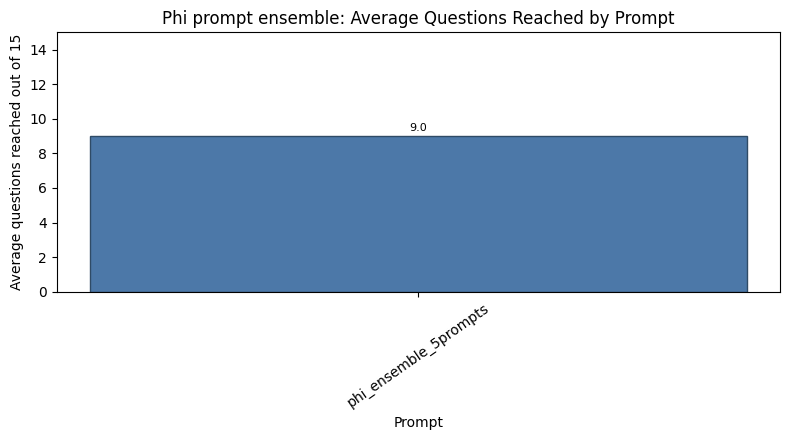

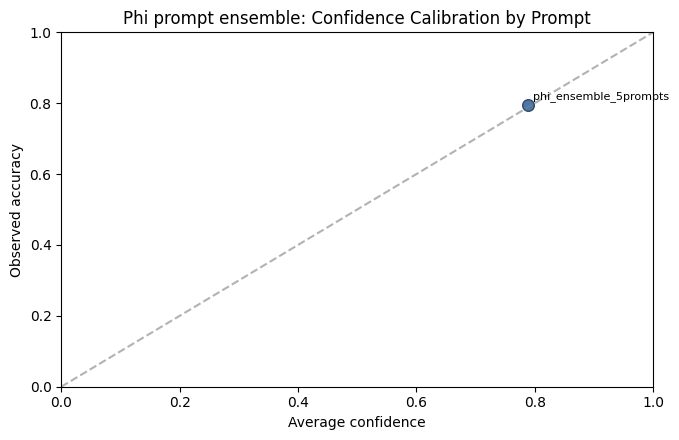

Phi prompt ensemble: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_prompt_ensemble,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,9.0,15,8.0,40,0.533333,0.933333,106600.0,512000,2.912187,4.271116,1.0,0.533333,non-thinking


Phi prompt ensemble: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
4,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Physics & astronomy,9,9,0,1.000000,7.000000,3,0.200000
1,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Chemistry & materials,4,4,0,1.000000,3.000000,3,0.088889
2,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Earth & environment,2,2,0,1.000000,3.000000,2,0.066667
5,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Scientific method & measurement,1,1,0,1.000000,9.000000,1,0.066667
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Biology & medicine,12,10,2,0.833333,4.833333,5,0.133333
3,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Other science/nature,12,10,2,0.833333,7.250000,3,0.222222
6,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Technology & engineering,5,4,1,0.800000,3.400000,4,0.066667


,model_label,prompt_type,error_type,count
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Correct,40
1,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,High-confidence wrong answer,3
2,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,Plausible but incorrect answer,2


...

,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,45,45,1.0


Phi prompt ensemble: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,low (<= 0.40),0,NaN,NaN,NaN,0
1,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,medium (0.40-0.70),6,0.666667,0.648701,0.405891,0
2,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,high (>= 0.70),39,0.923077,0.928366,0.880808,3


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
44,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,5,10,Biology & medicine,Which of the following is NOT a primary use of...,As a component in strong and lightweight alloys,"{""prompt_predictions"": [{""prompt_type"": ""scien...",0.930283,0.872460,"{""0"": -3.7763680815696716, ""1"": -5.70029538869...",False
34,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,4,6,Technology & engineering,Which situation is an example of an inherited ...,birds following migratory patterns,"{""prompt_predictions"": [{""prompt_type"": ""scien...",0.885107,0.807037,"{""0"": -6.5726563930511475, ""1"": -5.28414595127...",False
21,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,2,7,Biology & medicine,Tide pools are habitats for several kinds of o...,Diversity will increase as the rate of predati...,"{""prompt_predictions"": [{""prompt_type"": ""scien...",0.741691,0.563677,"{""0"": -4.063958764076233, ""1"": -3.613710999488...",False


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_prompt_ensemble,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,9.0,15,8.0,40,0.533333,0.933333,106600.0,512000,2.912187,4.271116,1.0,0.533333,non-thinking


In [ ]:
load_phi_model()

df_phi_ensemble = benchmark_answer_fn(
    answer_fn=generate_answer_phi_ensemble,
    model_label="phi_3_5_mini_prompt_ensemble",
    prompt_type="phi_ensemble_5prompts",
    n_runs=5,
    delay_seconds=1.5,
)

phi_ensemble_summary = make_survival_summary(df_phi_ensemble)
phi_ensemble_summary_sorted = sort_survival_summary(phi_ensemble_summary)

df_phi_ensemble.to_csv("science_nature_phi_3_5_mini_prompt_ensemble.csv", index=False)
phi_ensemble_summary_sorted.to_csv("science_nature_phi_3_5_mini_prompt_ensemble_summary.csv", index=False)

phi_ensemble_analysis = analyse_model_runs(
    df_phi_ensemble,
    model_tag="Phi prompt ensemble",
    output_prefix="science_nature_phi_3_5_mini_prompt_ensemble",
    model_type="non-thinking",
)

phi_ensemble_summary_sorted


### Note on Phi prompt ensemble calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

In [ ]:
best_phi_parts = [
    summary
    for summary in [
        globals().get("phi_fixed_generation_summary"),
        globals().get("phi_forced_choice_summary"),
        globals().get("phi_ensemble_summary_sorted"),
        globals().get("final_survival_summary"),
    ]
    if isinstance(summary, pd.DataFrame)
]

best_phi_summary = sort_survival_summary(
    pd.concat(best_phi_parts, ignore_index=True, sort=False)
) if best_phi_parts else pd.DataFrame()

family_summary_parts = [
    summary
    for summary in [
        globals().get("qwen_comparison_summary_sorted"),
        globals().get("best_phi_summary"),
        globals().get("survival_summary_deepseek_sorted"),
        globals().get("gemma_survival_summary_sorted"),
        globals().get("llama_survival_summary_sorted"),
    ]
    if isinstance(summary, pd.DataFrame)
]

model_family_comparison_after_phi_ensemble = sort_survival_summary(
    pd.concat(family_summary_parts, ignore_index=True, sort=False)
) if family_summary_parts else pd.DataFrame()

best_phi_summary.to_csv("science_nature_best_phi_summary_after_ensemble.csv", index=False)
model_family_comparison_after_phi_ensemble.to_csv(
    "science_nature_model_family_comparison_after_phi_ensemble.csv",
    index=False,
)

display(best_phi_summary)
display(model_family_comparison_after_phi_ensemble)


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,phi_3_5_mini_fixed_generation,phi_3_5_mini_fixed_generation_science_short,science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.0,0.866667,non-thinking
2,phi_3_5_mini_prompt_ensemble,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,9.0,15,8.0,40,0.533333,0.933333,106600.0,512000,2.912187,4.271116,1.0,0.533333,non-thinking
1,phi_3_5_mini_forced_choice,phi_3_5_mini_forced_choice_science_short,science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.0,0.453333,non-thinking
3,phi_3_5_mini_final_forced_choice,phi_3_5_mini_final_forced_choice_science_short,science_short,10,7.3,15,6.4,64,0.426667,1.000000,108510.0,1024000,0.422350,0.626991,1.0,0.426667,non-thinking


,system_name,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_label,prompt_type,model_type
12,phi_3_5_mini_fixed_generation_science_short,5,13.8,15,13.0,65,0.866667,1.000000,464000.0,1024000,0.422788,0.941358,1.000000,0.866667,phi_3_5_mini_fixed_generation,science_short,non-thinking
13,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,5,9.0,15,8.0,40,0.533333,0.933333,106600.0,512000,2.912187,4.271116,1.000000,0.533333,phi_3_5_mini_prompt_ensemble,phi_ensemble_5prompts,non-thinking
14,phi_3_5_mini_forced_choice_science_short,5,7.6,15,6.8,34,0.453333,1.000000,206740.0,1024000,0.414797,0.612885,1.000000,0.453333,phi_3_5_mini_forced_choice,science_short,non-thinking
0,qwen_3b_science_expert,5,7.4,12,6.4,32,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000,0.426667,qwen_3b,science_expert,non-thinking
15,phi_3_5_mini_final_forced_choice_science_short,10,7.3,15,6.4,64,0.426667,1.000000,108510.0,1024000,0.422350,0.626991,1.000000,0.426667,phi_3_5_mini_final_forced_choice,science_short,non-thinking
1,qwen_3b_baseline,5,7.2,14,6.2,31,0.413333,0.866667,52340.0,256000,0.183629,0.246370,0.985714,0.413333,qwen_3b,baseline,non-thinking
22,gemma_2_2b_it_few_shot_science,5,6.6,15,5.8,29,0.386667,1.000000,211280.0,1024000,0.542497,0.722529,1.000000,0.386667,gemma_2_2b_it,few_shot_science,non-thinking
2,qwen_3b_elimination,5,6.2,12,5.2,26,0.346667,0.733333,16140.0,64000,0.193773,0.247020,1.000000,0.346667,qwen_3b,elimination,non-thinking
3,qwen_1_5b_baseline,5,6.0,11,5.0,25,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.000000,0.333333,qwen_1_5b,baseline,NaN
23,gemma_2_2b_it_baseline,5,6.0,9,5.0,25,0.333333,0.533333,2260.0,8000,0.357397,0.466021,1.000000,0.333333,gemma_2_2b_it,baseline,non-thinking


### Phi ensemble interpretation

The Phi prompt ensemble was useful as an experiment, but it did not improve over the strongest single Phi setup. The ensemble reached **9.0 average questions**, a best run of **15 questions**, and valid-output rate **1.0**. This is better than the later forced-choice Phi check, but clearly below `phi_3_5_mini_fixed_generation_science_short`, which reached **13.8 average questions**.

The result suggests that prompt diversity alone is not enough. Combining several Phi prompt styles adds extra computation and can dilute a very strong single prompt. In the report, present the Phi ensemble as a negative but informative result: ensembling was explored, but the single corrected fixed-generation Phi setup remained stronger.

<!-- REPORT_MARKDOWN_ENSEMBLE_V2 -->
### Report-ready interpretation: ensemble experiments

Two ensemble ideas are included in the notebook:

1. **Phi prompt ensemble**: combines several prompt styles for the same Phi model.
2. **Top-three model ensemble**: combines the strongest selected model families, with both weighted and unweighted variants.



# RAG experiment with the best observed model

This section runs RAG **after** the model-family experiments, so the retrieval experiment uses the strongest base model configuration observed so far instead of assuming that Phi is always best.

Two retrieval styles are available:

- `sciq_static`: reproducible RAG using the AllenAI SciQ dataset from Hugging Face. This does **not** change between runs, so it is the best option for the report.
- `web_live`: live website RAG using Wikipedia search and page summaries. This can change over time because websites change, so it is useful as an extra experiment but less reproducible.
- `hybrid`: combines SciQ and live web context.

The code below keeps the same game API and prompt list. It only changes the context placed before the model answers. The static SciQ retriever now uses all available SciQ splits and adds a topic-aware retrieval hint so the passages are usually closer to the game question.


In [ ]:
import json
import re
import subprocess
import sys
import time
from functools import lru_cache
from urllib.parse import quote

import pandas as pd
import requests


try:
    from datasets import load_dataset
except ImportError:
    print("Installing the Hugging Face datasets package for SciQ RAG...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "datasets"])
    from datasets import load_dataset


SCIENCE_RAG_DATASET = "allenai/sciq"
SCIENCE_RAG_SPLITS = ("train", "validation", "test")
SCIENCE_RAG_MAX_DOCS = 15000
SCIENCE_RAG_TOP_K = 5
RAG_CONTEXT_MAX_CHARS = 520


RAG_MIN_RETRIEVAL_SCORE = 0.25
RAG_MIN_MATCHED_TERMS = 2

RAG_RETRIEVAL_MODE = "sciq_static"  # Options: "sciq_static", "web_live", "hybrid"
RUN_LIVE_WEB_RAG = False  # Set True to include changing live website retrieval

SCIENCE_RAG_STOPWORDS = {
    "the", "and", "or", "of", "to", "in", "a", "an", "is", "are", "was", "were",
    "which", "what", "who", "when", "where", "why", "how", "following", "best",
    "describes", "describe", "option", "answer", "question", "science", "nature",
    "does", "do", "did", "from", "with", "that", "this", "these", "those", "for",
    "into", "about", "most", "least", "called", "known", "used", "using",
}

TRUSTED_RAG_SOURCE_TABLE = pd.DataFrame(
    [
        {
            "mode": "sciq_static",
            "source": "AllenAI SciQ via Hugging Face",
            "changes_between_runs": "No",
            "best_use": "Main project comparison because it is reproducible.",
        },
        {
            "mode": "web_live",
            "source": "Wikipedia search and summaries",
            "changes_between_runs": "Yes",
            "best_use": "Optional extension showing live website retrieval.",
        },
        {
            "mode": "hybrid",
            "source": "SciQ + Wikipedia summaries",
            "changes_between_runs": "Partly",
            "best_use": "Exploratory comparison when you want both stable and live context.",
        },
    ]
)

display(TRUSTED_RAG_SOURCE_TABLE)


def rag_terms(text):
    """Return useful retrieval terms from a question, answer option, or support passage."""
    return {
        token
        for token in re.findall(r"[a-zA-Z][a-zA-Z0-9\-]+", str(text).lower())
        if len(token) > 2 and token not in SCIENCE_RAG_STOPWORDS
    }


def shorten_for_prompt(text, max_chars=650):
    """Keep retrieved passages short enough for fast local generation."""
    text = re.sub(r"\s+", " ", str(text)).strip()
    if len(text) <= max_chars:
        return text
    return text[: max_chars - 3].rstrip() + "..."


RAG_TOPIC_HINTS = {
    "Biology & medicine": "biology cell organism genetics medicine disease protein evolution ecology",
    "Chemistry & materials": "chemistry atom molecule element compound reaction acid base material",
    "Physics & astronomy": "physics force energy motion gravity light wave planet star astronomy",
    "Earth & environment": "earth climate weather atmosphere ocean rock volcano environment ecosystem",
    "Technology & engineering": "technology engineering computer machine device battery satellite algorithm",
    "Scientific method & measurement": "experiment hypothesis theory data measurement unit variable control",
    "People & history of science": "scientist discovery invention history nobel darwin newton curie einstein",
}


def rag_query_text(question):
    """Build a retrieval query from question, options, and the science-topic hint."""
    options_text = " ".join(option.text for option in question.options)
    topic = classify_science_question(f"{question.text} {options_text}") if "classify_science_question" in globals() else ""
    topic_hint = RAG_TOPIC_HINTS.get(topic, "")
    return f"{question.text} {options_text} {topic_hint}".strip(), topic


@lru_cache(maxsize=4)
def load_sciq_rag_corpus(splits=SCIENCE_RAG_SPLITS, max_documents=SCIENCE_RAG_MAX_DOCS):
    """Load SciQ once and convert support passages into a simple lexical corpus.

    The prompt only receives support passages. SciQ answers are used only to make
    retrieval matching better, not as direct answers to the live game.
    """
    documents = []

    for split in splits:
        dataset = load_dataset(SCIENCE_RAG_DATASET, split=split)

        for row_id, row in enumerate(dataset):
            if len(documents) >= max_documents:
                break

            support = str(row.get("support", "")).strip()
            if not support:
                continue

            question_text = str(row.get("question", "")).strip()
            correct_answer = str(row.get("correct_answer", "")).strip()
            distractors = [
                str(row.get("distractor1", "")).strip(),
                str(row.get("distractor2", "")).strip(),
                str(row.get("distractor3", "")).strip(),
            ]
            retrieval_text = " ".join([question_text, support, correct_answer, *distractors])

            documents.append(
                {
                    "source": f"SciQ {split} row {row_id}",
                    "source_type": "sciq_static",
                    "title": question_text,
                    "support": support,
                    "url": "https://huggingface.co/datasets/allenai/sciq",
                    "terms": rag_terms(retrieval_text),
                }
            )

        if len(documents) >= max_documents:
            break

    print(f"Loaded {len(documents)} SciQ support passages for RAG retrieval.")
    return documents


def retrieve_sciq_context(question, top_k=SCIENCE_RAG_TOP_K):
    """Retrieve stable SciQ support passages related to the current game question."""
    query_text, topic = rag_query_text(question)
    option_texts = [str(option.text).lower() for option in question.options]
    query_terms = rag_terms(query_text)

    if not query_terms:
        return []

    scored_docs = []
    for document in load_sciq_rag_corpus():
        overlap = query_terms & document["terms"]
        if not overlap:
            continue

        query_coverage = len(overlap) / max(1, len(query_terms))
        document_focus = len(overlap) / max(1, len(document["terms"]))
        support_lower = f"{document['title']} {document['support']}".lower()
        option_phrase_bonus = 0.20 if any(option_text and option_text in support_lower for option_text in option_texts) else 0.0
        title_overlap_bonus = 0.12 * len(rag_terms(document["title"]) & query_terms)
        score = query_coverage + 0.35 * document_focus + option_phrase_bonus + title_overlap_bonus

        scored_docs.append(
            {
                "source": document["source"],
                "source_type": document["source_type"],
                "title": document["title"],
                "support": document["support"],
                "url": document["url"],
                "score": score,
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(scored_docs, key=lambda item: item["score"], reverse=True)[:top_k]


@lru_cache(maxsize=256)
def fetch_wikipedia_summary(title):
    """Fetch a live Wikipedia summary. This can change over time."""
    url = f"https://en.wikipedia.org/api/rest_v1/page/summary/{quote(title, safe='')}"
    headers = {"User-Agent": "science-quiz-rag-notebook/1.0 student project"}
    response = requests.get(url, headers=headers, timeout=10)
    response.raise_for_status()
    payload = response.json()
    return {
        "title": payload.get("title", title),
        "support": payload.get("extract", ""),
        "url": payload.get("content_urls", {}).get("desktop", {}).get("page", url),
    }


@lru_cache(maxsize=256)
def search_wikipedia_titles(query, limit=5):
    """Search Wikipedia for live page titles related to the question."""
    search_url = "https://en.wikipedia.org/w/api.php"
    headers = {"User-Agent": "science-quiz-rag-notebook/1.0 student project"}
    params = {
        "action": "query",
        "list": "search",
        "srsearch": query,
        "srlimit": limit,
        "format": "json",
        "origin": "*",
    }
    response = requests.get(search_url, headers=headers, params=params, timeout=10)
    response.raise_for_status()
    results = response.json().get("query", {}).get("search", [])
    return tuple(result.get("title", "") for result in results if result.get("title"))


def retrieve_live_web_context(question, top_k=SCIENCE_RAG_TOP_K):
    """Retrieve live website context from Wikipedia summaries."""
    query_text, topic = rag_query_text(question)
    query_terms = sorted(rag_terms(query_text))
    compact_query = " ".join(query_terms[:10]) or question.text

    retrieved_docs = []
    try:
        titles = search_wikipedia_titles(compact_query, limit=max(5, top_k))
    except Exception as error:
        print("Live web RAG search failed:", repr(error))
        return []

    for title in titles:
        try:
            summary = fetch_wikipedia_summary(title)
        except Exception:
            continue

        support = summary.get("support", "")
        if not support:
            continue

        overlap = rag_terms(f"{summary.get('title', '')} {support}") & set(query_terms)
        score = len(overlap) / max(1, len(query_terms))
        retrieved_docs.append(
            {
                "source": "Wikipedia live summary",
                "source_type": "web_live",
                "title": summary.get("title", title),
                "support": support,
                "url": summary.get("url"),
                "score": score,
                "matched_terms": sorted(overlap),
                "topic_hint": topic,
            }
        )

    return sorted(retrieved_docs, key=lambda item: item["score"], reverse=True)[:top_k]


def retrieve_rag_context(question, mode=RAG_RETRIEVAL_MODE, top_k=SCIENCE_RAG_TOP_K):
    """Retrieve RAG context from the selected source mode."""
    if mode == "sciq_static":
        return retrieve_sciq_context(question, top_k=top_k)
    if mode == "web_live":
        return retrieve_live_web_context(question, top_k=top_k)
    if mode == "hybrid":
        docs = retrieve_sciq_context(question, top_k=top_k) + retrieve_live_web_context(question, top_k=top_k)
        return sorted(docs, key=lambda item: item["score"], reverse=True)[:top_k]
    raise ValueError(f"Unknown RAG retrieval mode: {mode}")




def should_use_rag(retrieved_docs, min_score=RAG_MIN_RETRIEVAL_SCORE, min_matched_terms=RAG_MIN_MATCHED_TERMS):
    """Return True only when retrieval is strong enough to help the answer.

    RAG is not automatically useful: a weak or unrelated passage can distract a
    small local model. This gate keeps the experiment fair by using retrieved
    context only when the top passage has a reasonable lexical match.
    """
    if not retrieved_docs:
        return False

    best_doc = retrieved_docs[0]
    best_score = pd.to_numeric(best_doc.get("score"), errors="coerce")
    if pd.isna(best_score):
        best_score = 0.0

    matched_terms = best_doc.get("matched_terms", []) or []
    strong_score = float(best_score) >= float(min_score)
    enough_terms = len(matched_terms) >= int(min_matched_terms)

    # Very high scores can still pass even when the source has only one matched
    # term, because option-phrase and title-overlap bonuses may be informative.
    return (strong_score and enough_terms) or float(best_score) >= 0.45


def generate_answer_base_candidate_for_rag_fallback(question, prompt_type="science_short", candidate=None):
    """Answer without retrieval using the currently loaded base model.

    The selected RAG candidate is already loaded before this function is called.
    This keeps the comparison fair: the only change is whether retrieved context
    is added to the prompt.
    """
    family = str((candidate or {}).get("family", "")).lower()

    if family == "phi" and "generate_answer_phi_scored" in globals():
        return generate_answer_phi_scored(question, prompt_type=prompt_type)
    if family == "llama" and "generate_answer_scored_options" in globals():
        return generate_answer_scored_options(question, prompt_type=prompt_type)
    if family == "deepseek" and "generate_answer_thinking" in globals():
        return generate_answer_thinking(question, prompt_type=prompt_type)
    if family == "qwen_3b" and "generate_answer_chat_template_with_confidence" in globals():
        return generate_answer_chat_template_with_confidence(question, prompt_type=prompt_type)
    if "generate_answer_chat_template" in globals():
        return generate_answer_chat_template(question, prompt_type=prompt_type)


    return generate_answer(question, prompt_type=prompt_type)


def build_rag_fallback_prediction(base_prediction, rag_mode, base_prompt_type, retrieved_docs):
    """Wrap a normal base-model prediction so logs show why RAG was skipped."""
    wrapped = dict(base_prediction)
    wrapped["prompt_type"] = f"{rag_mode}_{base_prompt_type}_fallback_to_base"
    wrapped["raw_response"] = json.dumps(
        {
            "rag_used": False,
            "fallback_reason": "retrieval_below_quality_gate",
            "quality_gate": {
                "min_score": RAG_MIN_RETRIEVAL_SCORE,
                "min_matched_terms": RAG_MIN_MATCHED_TERMS,
            },
            "retrieved_docs": retrieved_docs,
            "base_model_raw_response": base_prediction.get("raw_response"),
        },
        ensure_ascii=False,
    )
    return wrapped


def generate_answer_rag_base_fallback(question, prompt_type, rag_mode, retrieved_docs, candidate=None):
    base_prediction = generate_answer_base_candidate_for_rag_fallback(
        question,
        prompt_type=prompt_type,
        candidate=candidate,
    )
    return build_rag_fallback_prediction(
        base_prediction,
        rag_mode=rag_mode,
        base_prompt_type=prompt_type,
        retrieved_docs=retrieved_docs,
    )


def build_rag_prompt(question, prompt_type="science_short", rag_mode=RAG_RETRIEVAL_MODE, top_k=SCIENCE_RAG_TOP_K):
    """Build a prompt that adds retrieved context before the normal game prompt."""
    base_prompt = build_prompt_from_type(question, prompt_type)
    retrieved_docs = retrieve_rag_context(question, mode=rag_mode, top_k=top_k)

    if retrieved_docs:
        context_text = "\n".join(
            f"[{rank}] ({doc['source_type']}) {doc.get('title', 'Science source')}: "
            f"{shorten_for_prompt(doc['support'], max_chars=RAG_CONTEXT_MAX_CHARS)} "
            f"[matched: {', '.join(doc.get('matched_terms', [])[:5]) or 'general'}]"
            for rank, doc in enumerate(retrieved_docs, start=1)
        )
    else:
        context_text = "No highly related retrieval passage was found. Use general science knowledge."

    rag_prompt = f"""
Use the retrieved context as background. Prefer the option that is best supported by the context and the question. If a passage is not relevant, ignore it.\n\nRetrieved context:
{context_text}

{base_prompt}
""".strip()

    return rag_prompt, retrieved_docs


BASE_MODEL_SPECS_FOR_RAG = [
    {
        "family": "phi",
        "patterns": ["phi_3_5"],
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_key": "phi_3_5_mini_rag",
        "use_4bit": False,
        "loader": "phi",
        "answer_style": "forced_choice",
    },
    {
        "family": "qwen_1_5b",
        "patterns": ["qwen_1_5b", "qwen2.5-1.5b"],
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_key": "qwen_1_5b_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "qwen_3b",
        "patterns": ["qwen_3b", "qwen2.5-3b"],
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_key": "qwen_3b_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "deepseek",
        "patterns": ["deepseek"],
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_key": "deepseek_r1_1_5b_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "gemma",
        "patterns": ["gemma"],
        "model_id": "google/gemma-2-2b-it",
        "model_key": "gemma_2_2b_it_rag",
        "use_4bit": False,
        "answer_style": "chat",
    },
    {
        "family": "llama",
        "patterns": ["llama"],
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_key": "llama_3_8b_rag",
        "use_4bit": True,
        "answer_style": "forced_choice",
    },
]


def collect_base_model_summaries_for_selection():
    """Collect already-run base model summaries without using ensemble/RAG rows."""
    summary_names = [
        "survival_summary_qwen_1_5b",
        "qwen_comparison_summary_sorted",
        "survival_summary_qwen3b",
        "survival_summary_best_qwen3b",
        "survival_summary_current_model",
        "phi_fixed_generation_summary",
        "phi_forced_choice_summary",
        "phi_fixed_comparison",
        "final_survival_summary",
        "survival_summary_deepseek_sorted",
        "gemma_survival_summary_sorted",
        "llama_survival_summary_sorted",
    ]
    summaries = []

    for summary_name in summary_names:
        value = globals().get(summary_name)
        if isinstance(value, pd.DataFrame) and not value.empty:
            df_summary = value.copy()
            df_summary["summary_source"] = summary_name
            summaries.append(df_summary)

    if not summaries:
        return pd.DataFrame()

    table = pd.concat(summaries, ignore_index=True, sort=False)
    if "model_label" not in table.columns:
        table["model_label"] = table.get("system_name", "").astype(str)

    text_columns = ["summary_source", "model_label", "system_name", "prompt_type"]
    row_text = table[[column for column in text_columns if column in table.columns]].astype(str).agg(" ".join, axis=1).str.lower()
    excluded = row_text.str.contains("ensemble|rag|top3|controlled", regex=True)
    table = table.loc[~excluded].copy()

    required_columns = ["average_questions_reached", "best_questions_reached", "valid_output_rate"]
    for column in required_columns:
        if column not in table.columns:
            table[column] = 0
        table[column] = pd.to_numeric(table[column], errors="coerce").fillna(0)

    return table.sort_values(
        by=["average_questions_reached", "best_questions_reached", "valid_output_rate"],
        ascending=False,
    )


def model_spec_from_summary_row(row):
    """Map a summary row to a loadable model architecture."""
    row_text = " ".join(
        str(row.get(column, ""))
        for column in ["summary_source", "model_label", "system_name", "prompt_type"]
    ).lower()

    for spec in BASE_MODEL_SPECS_FOR_RAG:
        if spec["family"] == "gemma" and not globals().get("RUN_GEMMA", False):
            continue
        if any(pattern in row_text for pattern in spec["patterns"]):
            candidate = spec.copy()
            candidate["prompt_type"] = str(row.get("prompt_type", "science_short"))
            candidate["observed_average_questions_reached"] = row.get("average_questions_reached")
            candidate["observed_best_questions_reached"] = row.get("best_questions_reached")
            candidate["observed_valid_output_rate"] = row.get("valid_output_rate")
            candidate["source_model_label"] = row.get("model_label")
            candidate["source_system_name"] = row.get("system_name")
            return candidate

    return None


def select_best_base_model_for_rag():
    """Select the best observed non-ensemble, non-RAG model configuration."""
    summary_table = collect_base_model_summaries_for_selection()
    candidates = []

    for _, row in summary_table.iterrows():
        candidate = model_spec_from_summary_row(row)
        if candidate is not None:
            candidates.append(candidate)

    if candidates:
        return candidates[0], summary_table

    fallback = BASE_MODEL_SPECS_FOR_RAG[0].copy()
    fallback["prompt_type"] = "science_short"
    fallback["observed_average_questions_reached"] = None
    fallback["source_model_label"] = "fallback_phi"
    return fallback, summary_table


active_rag_model_key = None


def load_rag_model_candidate(candidate):
    """Load the selected model for the RAG experiment."""
    global active_rag_model_key

    if active_rag_model_key == candidate["model_key"]:
        return

    if candidate.get("loader") == "phi":
        load_phi_model()
    else:
        load_chat_model(
            model_id=candidate["model_id"],
            model_label=f"{candidate['family']}_best_rag",
            use_4bit=candidate.get("use_4bit", False),
        )

    active_rag_model_key = candidate["model_key"]


def split_rag_prompt_type(prompt_type):
    """Split a combined prompt like sciq_static_science_short into mode and base prompt."""
    for mode in ["sciq_static", "web_live", "hybrid"]:
        prefix = mode + "_"
        if str(prompt_type).startswith(prefix):
            return mode, str(prompt_type)[len(prefix):]
    return RAG_RETRIEVAL_MODE, prompt_type


def generate_answer_rag_forced_choice(question, prompt_type="science_short", rag_mode=RAG_RETRIEVAL_MODE, candidate=None):
    """Use retrieved context, then score each answer option by likelihood."""
    rag_prompt, retrieved_docs = build_rag_prompt(question, prompt_type=prompt_type, rag_mode=rag_mode)

    if not should_use_rag(retrieved_docs):
        return generate_answer_rag_base_fallback(
            question,
            prompt_type=prompt_type,
            rag_mode=rag_mode,
            retrieved_docs=retrieved_docs,
            candidate=candidate,
        )

    formatted_prompt = format_model_prompt(rag_prompt)
    base_text = formatted_prompt + "\nThe correct answer is option"
    start_time = time.time()
    option_scores = {}

    for option in question.options:
        candidate_text = f" {option.id}: {option.text}"
        score, token_count = score_candidate_continuation_generic(
            base_text,
            candidate_text,
            return_token_count=True,
        )
        option_scores[int(option.id)] = {
            "score": score,
            "tokens": token_count,
            "text": option.text,
        }

    predicted_id = max(option_scores, key=lambda option_id: option_scores[option_id]["score"])
    option_score_values = {
        option_id: values["score"]
        for option_id, values in option_scores.items()
    }
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_score_values,
        predicted_id,
    )

    return {
        "prompt_type": f"{rag_mode}_{prompt_type}",
        "prompt": rag_prompt,
        "raw_response": json.dumps(
            {
                "rag_mode": rag_mode,
                "retrieved_docs": retrieved_docs,
                "option_scores": option_scores,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": time.time() - start_time,
        "option_confidences": option_score_values,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def generate_answer_rag_chat(question, prompt_type="science_short", rag_mode=RAG_RETRIEVAL_MODE, candidate=None):
    """Use retrieved context with a normal chat-template generation model."""
    rag_prompt, retrieved_docs = build_rag_prompt(question, prompt_type=prompt_type, rag_mode=rag_mode)

    if not should_use_rag(retrieved_docs):
        return generate_answer_rag_base_fallback(
            question,
            prompt_type=prompt_type,
            rag_mode=rag_mode,
            retrieved_docs=retrieved_docs,
            candidate=candidate,
        )

    formatted_prompt = format_model_prompt(rag_prompt)
    valid_option_ids = [option.id for option in question.options]
    start_time = time.time()

    option_confidences = estimate_option_confidences(
        formatted_prompt=formatted_prompt,
        valid_option_ids=valid_option_ids,
    )

    inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=generation_token_budget(prompt_type, 16),
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[-1]:]
    raw_generation = tokenizer.decode(generated_tokens, skip_special_tokens=True).strip()
    predicted_id = parse_option_id(raw_generation, valid_option_ids)
    confidence_score, confidence_margin = confidence_margin_from_scores(
        option_confidences,
        predicted_id,
    )

    return {
        "prompt_type": f"{rag_mode}_{prompt_type}",
        "prompt": rag_prompt,
        "raw_response": json.dumps(
            {
                "rag_mode": rag_mode,
                "retrieved_docs": retrieved_docs,
                "generation": raw_generation,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": time.time() - start_time,
        "option_confidences": option_confidences,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


def generate_answer_best_model_rag(question, prompt_type="sciq_static_science_short"):
    """Run RAG using the best observed base model architecture."""
    rag_mode, base_prompt_type = split_rag_prompt_type(prompt_type)
    candidate = globals().get("best_model_rag_candidate")

    if candidate is None:
        candidate, _ = select_best_base_model_for_rag()
        globals()["best_model_rag_candidate"] = candidate

    load_rag_model_candidate(candidate)

    if candidate.get("answer_style") == "forced_choice":
        return generate_answer_rag_forced_choice(
            question,
            prompt_type=base_prompt_type,
            rag_mode=rag_mode,
            candidate=candidate,
        )

    return generate_answer_rag_chat(
        question,
        prompt_type=base_prompt_type,
        rag_mode=rag_mode,
        candidate=candidate,
    )


,mode,source,changes_between_runs,best_use
0,sciq_static,AllenAI SciQ via Hugging Face,No,Main project comparison because it is reproduc...
1,web_live,Wikipedia search and summaries,Yes,Optional extension showing live website retrie...
2,hybrid,SciQ + Wikipedia summaries,Partly,Exploratory comparison when you want both stab...


,family,source_model_label,prompt_type,observed_average_questions_reached,observed_best_questions_reached,observed_valid_output_rate
0,phi,phi_3_5_mini_fixed_generation,science_short,13.8,15,1.0



Running model=phi_best_model_sciq_static_rag, prompt=sciq_static_baseline, run 1/5
Started game session: 334204
System: phi_best_model_sciq_static_rag_sciq_static_baseline


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct


README.md: 0.00B [00:00, ?B/s]

...

data/test-00000-of-00001.parquet:   0%|          | 0.00/343k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11679 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Loaded 12252 SciQ support passages for RAG retrieval.

Level 1
Question: The endangered Florida manatee is a large, aquatic mammal that feeds on sea grasses in brackish water. Due to where they like to feed, manatees are vulnerable to injuries from boat propellers. If speed zones requiring boats to maintain a low speed are placed in areas where manatees are known to congregate, which will most likely occur?
Raw response: {"rag_mode": "sciq_static", "retrieved_docs": [{"source": "SciQ train row 11318", "source_type": "sciq_static", "title": "The result of what, in places like the amazon rainforest, is that food will be harder to produce, clean water will be harder to find, and development of new medicines will become slower?", "support": "percent of the Amazon rainforest was lost. Rates are higher in other tropical rainforests. What we are likely to notice on a day-to-day basis as a result of biodiversity loss is that food will be more difficult to produce, clean water will be more diff

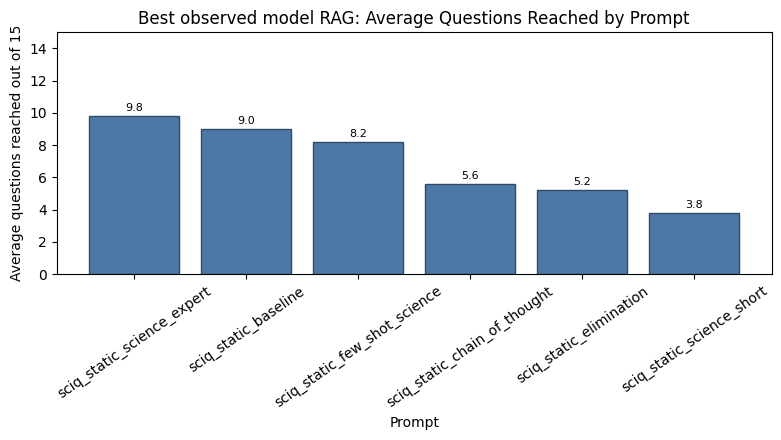

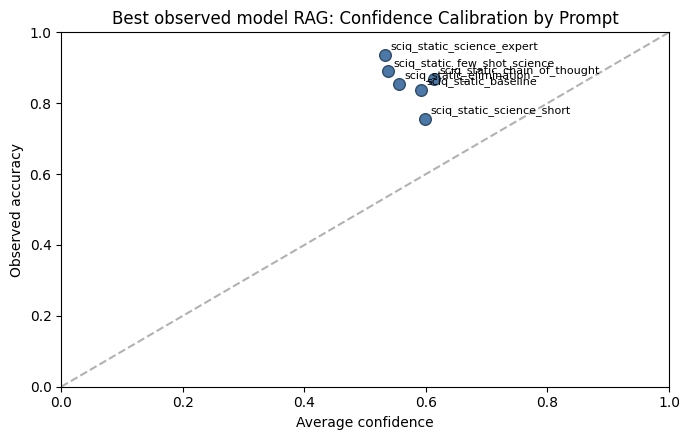

Best observed model RAG: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_sci...,sciq_static_science_expert,5,9.8,15,9.0,45,0.600000,1.000000,213200.0,1024000,2.505006,3.458754,1.0,0.600000,rag
0,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_bas...,sciq_static_baseline,4,9.0,10,8.0,32,0.533333,0.600000,10500.0,16000,2.450349,3.445070,1.0,0.533333,rag
3,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_few...,sciq_static_few_shot_science,5,8.2,13,7.2,36,0.480000,0.800000,35400.0,128000,2.876625,3.728198,1.0,0.480000,rag
1,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_cha...,sciq_static_chain_of_thought,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,2.487974,3.320427,1.0,0.306667,rag
2,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_eli...,sciq_static_elimination,5,5.2,15,4.2,21,0.280000,0.933333,102540.0,512000,2.501293,3.577825,1.0,0.280000,rag
5,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_sci...,sciq_static_science_short,5,3.8,8,2.8,14,0.186667,0.466667,940.0,4000,2.215463,3.530966,1.0,0.186667,rag


Best observed model RAG: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
4,phi_best_model_sciq_static_rag,sciq_static_baseline,Physics & astronomy,7,7,0,1.000000,4.285714,2,0.233333
1,phi_best_model_sciq_static_rag,sciq_static_baseline,Chemistry & materials,5,5,0,1.000000,4.000000,2,0.166667
2,phi_best_model_sciq_static_rag,sciq_static_baseline,Earth & environment,3,3,0,1.000000,4.000000,3,0.066667
6,phi_best_model_sciq_static_rag,sciq_static_baseline,Technology & engineering,3,3,0,1.000000,4.666667,3,0.066667
0,phi_best_model_sciq_static_rag,sciq_static_baseline,Biology & medicine,8,7,1,0.875000,5.875000,4,0.116667
3,phi_best_model_sciq_static_rag,sciq_static_baseline,Other science/nature,8,6,2,0.750000,5.500000,4,0.100000
5,phi_best_model_sciq_static_rag,sciq_static_baseline,Scientific method & measurement,2,1,1,0.500000,8.000000,2,0.033333
10,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,Other science/nature,5,5,0,1.000000,3.000000,4,0.083333
9,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,Earth & environment,4,4,0,1.000000,3.500000,3,0.088889
8,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,Chemistry & materials,2,2,0,1.000000,2.500000,1,0.133333


,model_label,prompt_type,error_type,count
0,phi_best_model_sciq_static_rag,sciq_static_baseline,Correct,32
1,phi_best_model_sciq_static_rag,sciq_static_baseline,Plausible but incorrect answer,4
2,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,Correct,23
3,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,High-confidence wrong answer,2
4,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,Plausible but incorrect answer,3
5,phi_best_model_sciq_static_rag,sciq_static_elimination,Correct,21
6,phi_best_model_sciq_static_rag,sciq_static_elimination,Plausible but incorrect answer,5
7,phi_best_model_sciq_static_rag,sciq_static_few_shot_science,Correct,36
8,phi_best_model_sciq_static_rag,sciq_static_few_shot_science,Plausible but incorrect answer,5
9,phi_best_model_sciq_static_rag,sciq_static_science_expert,Correct,45


...

,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate
0,phi_best_model_sciq_static_rag,sciq_static_baseline,36,36,1.0
1,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,28,28,1.0
2,phi_best_model_sciq_static_rag,sciq_static_elimination,26,26,1.0
3,phi_best_model_sciq_static_rag,sciq_static_few_shot_science,41,41,1.0
4,phi_best_model_sciq_static_rag,sciq_static_science_expert,49,49,1.0
5,phi_best_model_sciq_static_rag,sciq_static_science_short,19,19,1.0


Best observed model RAG: confidence and overconfidence


,model_label,prompt_type,confidence_bucket,questions,observed_accuracy,average_confidence,average_margin,overconfident_errors
0,phi_best_model_sciq_static_rag,sciq_static_baseline,low (<= 0.40),7,0.571429,0.357130,0.091305,0
1,phi_best_model_sciq_static_rag,sciq_static_baseline,medium (0.40-0.70),18,0.944444,0.530693,0.325996,0
2,phi_best_model_sciq_static_rag,sciq_static_baseline,high (>= 0.70),11,1.000000,0.886060,0.813609,0
3,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,low (<= 0.40),2,1.000000,0.366305,0.119042,0
4,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,medium (0.40-0.70),12,0.750000,0.573259,0.361335,0
5,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,high (>= 0.70),14,0.857143,0.899777,0.844737,2
6,phi_best_model_sciq_static_rag,sciq_static_elimination,low (<= 0.40),12,0.666667,0.325780,0.073572,0
7,phi_best_model_sciq_static_rag,sciq_static_elimination,medium (0.40-0.70),10,0.900000,0.494265,0.267434,0
8,phi_best_model_sciq_static_rag,sciq_static_elimination,high (>= 0.70),4,1.000000,0.848212,0.762300,0
9,phi_best_model_sciq_static_rag,sciq_static_few_shot_science,low (<= 0.40),12,0.750000,0.350969,0.096038,0


,model_label,prompt_type,system_name,run_id,level_before_answer,topic,question_text,selected_option_text,raw_response,confidence_score,confidence_margin,option_confidences,correct
191,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,phi_best_model_sciq_static_rag_sciq_static_cha...,4,6,Physics & astronomy,Earth orbits the Sun once a year. About how ma...,28,"{""rag_mode"": ""sciq_static"", ""retrieved_docs"": ...",0.827021,0.734397,"{""0"": -3.2008588314056396, ""1"": -3.70008277893...",False
185,phi_best_model_sciq_static_rag,sciq_static_chain_of_thought,phi_best_model_sciq_static_rag_sciq_static_cha...,3,6,Biology & medicine,Which thermoelectric effect is directly relate...,Joule heating,"{""rag_mode"": ""sciq_static"", ""retrieved_docs"": ...",0.757147,0.618414,"{""0"": -2.7344725131988525, ""1"": -3.57031655311...",False


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
4,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_sci...,sciq_static_science_expert,5,9.8,15,9.0,45,0.6,1.0,213200.0,1024000,2.505006,3.458754,1.0,0.6,rag
3,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_few...,sciq_static_few_shot_science,5,8.2,13,7.2,36,0.48,0.8,35400.0,128000,2.876625,3.728198,1.0,0.48,rag
0,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_bas...,sciq_static_baseline,5,7.4,10,6.4,32,0.426667,0.6,8400.0,16000,2.511287,3.445070,1.0,0.426667,rag
1,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_cha...,sciq_static_chain_of_thought,5,5.6,8,4.6,23,0.306667,0.466667,1420.0,4000,2.487974,3.320427,1.0,0.306667,rag
2,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_eli...,sciq_static_elimination,5,5.2,15,4.2,21,0.28,0.933333,102540.0,512000,2.501293,3.577825,1.0,0.28,rag
5,phi_best_model_sciq_static_rag,phi_best_model_sciq_static_rag_sciq_static_sci...,sciq_static_science_short,5,3.8,8,2.8,14,0.186667,0.466667,940.0,4000,2.215463,3.530966,1.0,0.186667,rag


In [ ]:
RUN_BEST_MODEL_RAG = True
BEST_MODEL_RAG_RUNS = 5
BEST_MODEL_RAG_PROMPT_TYPES = PROMPT_TYPES
BEST_MODEL_RAG_MODES = ["sciq_static"] + (["hybrid", "web_live"] if RUN_LIVE_WEB_RAG else [])

best_model_rag_candidate, best_model_rag_selection_table = select_best_base_model_for_rag()

best_model_rag_selection_display = pd.DataFrame([best_model_rag_candidate])
best_model_rag_display_columns = [
    "family",
    "source_model_label",
    "prompt_type",
    "observed_average_questions_reached",
    "observed_best_questions_reached",
    "observed_valid_output_rate",
]
display(
    best_model_rag_selection_display[
        [column for column in best_model_rag_display_columns if column in best_model_rag_selection_display.columns]
    ]
)

if RUN_BEST_MODEL_RAG:
    best_model_rag_results = []

    for rag_mode in BEST_MODEL_RAG_MODES:
        for base_prompt_type in BEST_MODEL_RAG_PROMPT_TYPES:
            combined_prompt_type = f"{rag_mode}_{base_prompt_type}"
            df_rag_prompt = benchmark_answer_fn(
                answer_fn=generate_answer_best_model_rag,
                model_label=f"{best_model_rag_candidate['family']}_best_model_{rag_mode}_rag",
                prompt_type=combined_prompt_type,
                n_runs=BEST_MODEL_RAG_RUNS,
                delay_seconds=1.5,
            )
            best_model_rag_results.append(df_rag_prompt)

    df_best_model_rag = pd.concat(best_model_rag_results, ignore_index=True)
    best_model_rag_summary = make_survival_summary(df_best_model_rag, model_type="rag")
    best_model_rag_summary_sorted = sort_survival_summary(best_model_rag_summary)

    # Keep these legacy names so later notebook sections still include the RAG experiment.
    df_phi_rag = df_best_model_rag
    phi_rag_summary_sorted = best_model_rag_summary_sorted

    df_best_model_rag.to_csv("science_nature_best_model_rag_results.csv", index=False)
    best_model_rag_summary_sorted.to_csv("science_nature_best_model_rag_summary.csv", index=False)

    best_model_rag_analysis = analyse_model_runs(
        df_best_model_rag,
        model_tag="Best observed model RAG",
        output_prefix="science_nature_best_model_rag",
        model_type="rag",
    )
    phi_rag_analysis = best_model_rag_analysis

    display(best_model_rag_summary_sorted)
else:
    df_best_model_rag = pd.DataFrame()
    best_model_rag_summary_sorted = pd.DataFrame()
    best_model_rag_analysis = {}
    df_phi_rag = pd.DataFrame()
    phi_rag_summary_sorted = pd.DataFrame()
    phi_rag_analysis = {}
    print("Best-model RAG is disabled. Set RUN_BEST_MODEL_RAG = True when you are ready.")


### Note on Phi-Rag calibration plot

This calibration plot should not be used for the final interpretation because the accuracy values are not calculated with the fixed 15-question denominator.

### RAG interpretation

The RAG table compares the best observed base model with retrieved context. The chosen base for the RAG experiment was `phi_3_5_mini_fixed_generation` with the `science_short` prompt, because it had the strongest observed non-RAG result before retrieval was tested.

The best reproducible RAG setting was `sciq_static_science_expert`, which reached **9.8 average questions**, a best run of **15 questions**, game accuracy of **0.600**, and valid-output rate **1.0**. This is a strong result, but it still did not beat the non-RAG Phi-3.5-mini fixed-generation result of **13.8 average questions**. RAG also increased response time, with the best RAG setting averaging about **2.5 seconds** per answer compared with about **0.42 seconds** for the best non-RAG Phi fixed-generation setup.

The retrieval-quality fallback remains important. It makes the RAG experiment more defensible because weak retrieved passages can be skipped instead of being forced into the prompt. For the report, the main conclusion is that SciQ RAG is a good experimental extension, but the current outputs do not support using RAG as the final default system.

## Topic-level error analysis

Overall accuracy is not enough for the final story. This section groups Science & Nature questions into topic areas and compares which models and prompts are strongest in each area.

The labels are rule-based, so they should be treated as an interpretable analysis tool rather than a perfect taxonomy. They are still useful for spotting patterns such as one model doing better on biology while another does better on physics or astronomy.


/tmp/ipykernel_2075/1383218004.py:48: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined = pd.concat(logs, ignore_index=True, sort=False)


,topic,questions
0,Other science/nature,314
1,Biology & medicine,271
2,Physics & astronomy,214
3,Earth & environment,143
4,Chemistry & materials,126
5,Technology & engineering,85
6,Scientific method & measurement,55
7,People & history of science,30


,topic,questions,correct_answers,observed_topic_accuracy,errors
5,Physics & astronomy,214,168,0.785047,46
2,Earth & environment,143,114,0.797203,29
6,Scientific method & measurement,55,44,0.800000,11
7,Technology & engineering,85,69,0.811765,16
0,Biology & medicine,271,224,0.826568,47
3,Other science/nature,314,261,0.831210,53
1,Chemistry & materials,126,109,0.865079,17
4,People & history of science,30,29,0.966667,1


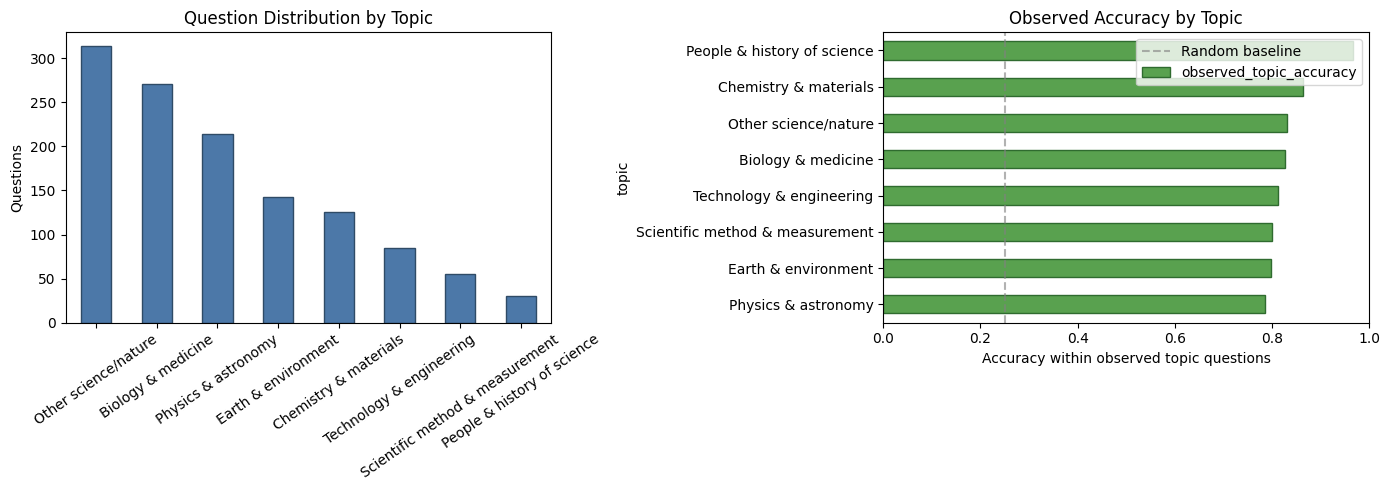

In [ ]:
def collect_available_question_logs():

    log_names = [
        "df_all_prompts",
        "df_current_model_prompts",
        "df_phi_fixed_generation",
        "df_phi_forced_choice",
        "df_phi_ensemble",
        "df_qwen3b_prompts",
        "df_final_model",
        "df_deepseek_all_prompts",
        "df_gemma_prompts",
        "df_llama_prompts",
        "df_top3_model_ensemble",
        "df_top3_unweighted_ensemble",
        "df_phi_rag",
        "df_best_model_rag",
        "df_controlled_final",
    ]

    logs = []

    for log_name in log_names:
        if log_name not in globals() or not isinstance(globals()[log_name], pd.DataFrame):
            continue

        df_log = globals()[log_name].copy()

        if "question_text" not in df_log.columns or "correct" not in df_log.columns:
            continue

        df_log["source_table"] = log_name

        if "model_label" not in df_log.columns:
            df_log["model_label"] = log_name.replace("df_", "")

        if "prompt_type" not in df_log.columns:
            df_log["prompt_type"] = "unknown"

        if "run_id" not in df_log.columns:
            df_log["run_id"] = 1

        logs.append(df_log)

    if not logs:
        return pd.DataFrame()

    combined = pd.concat(logs, ignore_index=True, sort=False)
    combined = prepare_question_level_analysis(combined)

    dedupe_columns = [
        column for column in [
            "model_label",
            "system_name",
            "prompt_type",
            "run_id",
            "question_id",
            "selected_option_id",
            "raw_response",
        ]
        if column in combined.columns
    ]
    combined = combined.drop_duplicates(subset=dedupe_columns, keep="first")

    combined["run_key"] = (
        combined["model_label"].astype(str)
        + "|"
        + combined["system_name"].astype(str)
        + "|"
        + combined["prompt_type"].astype(str)
        + "|"
        + combined["run_id"].astype(str)
    )

    return combined


df_topic_analysis = collect_available_question_logs()

if df_topic_analysis.empty:
    print("No question-level logs are available yet. Run the model benchmark cells first, then rerun this cell.")
else:
    topic_distribution = df_topic_analysis["topic"].value_counts().rename_axis("topic").reset_index(name="questions")
    topic_accuracy = df_topic_analysis.groupby("topic").agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        observed_topic_accuracy=("correct", "mean"),
        errors=("correct", lambda values: (~values).sum()),
    ).reset_index().sort_values("observed_topic_accuracy")

    topic_distribution.to_csv("science_nature_topic_distribution.csv", index=False)
    topic_accuracy.to_csv("science_nature_topic_accuracy.csv", index=False)

    display(topic_distribution)
    display(topic_accuracy)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    topic_distribution.plot(
        kind="bar",
        x="topic",
        y="questions",
        ax=axes[0],
        color="#4C78A8",
        edgecolor="#2F4B66",
        legend=False,
    )
    axes[0].set_title("Question Distribution by Topic")
    axes[0].set_xlabel("")
    axes[0].set_ylabel("Questions")
    axes[0].tick_params(axis="x", rotation=35)

    topic_accuracy.plot(
        kind="barh",
        x="topic",
        y="observed_topic_accuracy",
        ax=axes[1],
        color="#59A14F",
        edgecolor="#2F6B2F",
        legend=False,
    )
    axes[1].set_title("Observed Accuracy by Topic")
    axes[1].set_xlabel("Accuracy within observed topic questions")
    axes[1].set_xlim(0, 1)
    axes[1].axvline(0.25, linestyle="--", color="gray", alpha=0.6, label="Random baseline")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig("science_nature_topic_overview.png", dpi=150, bbox_inches="tight")
    plt.show()


In [ ]:
if df_topic_analysis.empty:
    print("Run the topic analysis collection cell first.")
else:
    model_topic_summary = df_topic_analysis.groupby(["model_label", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        mean_response_time=("response_time", "mean"),
        runs=("run_key", "nunique"),
    ).reset_index()
    model_topic_summary["game_accuracy_contribution"] = (
        model_topic_summary["correct_answers"] / (model_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    prompt_topic_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        runs=("run_key", "nunique"),
    ).reset_index()
    prompt_topic_summary["game_accuracy_contribution"] = (
        prompt_topic_summary["correct_answers"] / (prompt_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    min_questions_for_heatmap = 2
    topic_winners = (
        model_topic_summary[model_topic_summary["questions"] >= min_questions_for_heatmap]
        .sort_values(
            ["topic", "observed_topic_accuracy", "correct_answers", "questions", "mean_response_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
        .rename(
            columns={
                "model_label": "best_model",
                "observed_topic_accuracy": "mean_answer_accuracy",
                "average_level_seen": "mean_level_seen",
                "mean_response_time": "mean_time_seconds",
            }
        )
    )
    topic_winner_columns = [
        "topic",
        "best_model",
        "questions",
        "correct_answers",
        "mean_answer_accuracy",
        "mean_level_seen",
        "mean_time_seconds",
        "runs",
    ]
    topic_winners = topic_winners[
        [column for column in topic_winner_columns if column in topic_winners.columns]
    ]

    model_error_type_summary = df_topic_analysis.groupby(["model_label", "error_type"]).size().reset_index(name="count")
    prompt_error_type_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "error_type"]).size().reset_index(name="count")

    model_topic_summary.to_csv("science_nature_model_topic_summary.csv", index=False)
    prompt_topic_summary.to_csv("science_nature_prompt_topic_summary.csv", index=False)
    topic_winners.to_csv("science_nature_best_model_by_topic.csv", index=False)
    model_error_type_summary.to_csv("science_nature_model_error_type_summary.csv", index=False)
    prompt_error_type_summary.to_csv("science_nature_prompt_error_type_summary.csv", index=False)

    print("Error types by model:")
    display(model_error_type_summary)
    print("Best observed model by topic:")
    display(topic_winners)
    display(prompt_topic_summary.sort_values(["topic", "observed_topic_accuracy"], ascending=[True, False]).head(30))


Error types by model:


,model_label,error_type,count
0,deepseek_r1_1_5b,Correct,16
1,deepseek_r1_1_5b,High-confidence wrong answer,1
2,deepseek_r1_1_5b,Invalid or unparseable output,9
3,deepseek_r1_1_5b,Plausible but incorrect answer,20
4,gemma_2_2b_it,Correct,138
5,gemma_2_2b_it,High-confidence wrong answer,21
6,gemma_2_2b_it,Plausible but incorrect answer,8
7,llama_3_8b_forced_choice,Correct,45
8,llama_3_8b_forced_choice,Plausible but incorrect answer,25
9,phi_3_5_mini_final_forced_choice,Correct,64


Best observed model by topic:


,topic,best_model,questions,correct_answers,mean_answer_accuracy,mean_level_seen,mean_time_seconds,runs
0,Biology & medicine,phi_3_5_mini_final_forced_choice,14,14,1.00000,4.214286,0.438566,7
1,Chemistry & materials,phi_3_5_mini_fixed_generation,7,7,1.00000,8.428571,0.393362,4
2,Earth & environment,phi_3_5_mini_fixed_generation,5,5,1.00000,3.600000,0.384501,4
3,Other science/nature,phi_best_model_sciq_static_rag,47,44,0.93617,4.957447,2.587342,21
4,People & history of science,qwen_3b,6,6,1.00000,4.500000,0.211395,4
5,Physics & astronomy,phi_3_5_mini_fixed_generation,14,14,1.00000,8.785714,0.448728,5
6,Scientific method & measurement,gemma_2_2b_it,7,7,1.00000,4.857143,0.476695,6
7,Technology & engineering,phi_3_5_mini_fixed_generation,4,4,1.00000,10.250000,0.499854,3


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution
74,llama_3_8b_forced_choice,elimination,Biology & medicine,5,5,0,1.000000,2.600000,3,0.111111
84,llama_3_8b_forced_choice,science_expert,Biology & medicine,1,1,0,1.000000,3.000000,1,0.066667
97,phi_3_5_mini_final_forced_choice,science_short,Biology & medicine,14,14,0,1.000000,4.214286,7,0.133333
105,phi_3_5_mini_fixed_generation,science_short,Biology & medicine,9,9,0,1.000000,5.222222,4,0.150000
128,phi_3_mini,baseline,Biology & medicine,9,9,0,1.000000,7.555556,3,0.200000
140,phi_3_mini,elimination,Biology & medicine,10,10,0,1.000000,7.800000,3,0.222222
155,phi_3_mini,science_expert,Biology & medicine,11,11,0,1.000000,4.090909,4,0.183333
185,phi_best_model_sciq_static_rag,sciq_static_elimination,Biology & medicine,6,6,0,1.000000,5.500000,4,0.100000
191,phi_best_model_sciq_static_rag,sciq_static_few_shot_science,Biology & medicine,9,9,0,1.000000,6.666667,3,0.200000
213,qwen_1_5b,baseline,Biology & medicine,5,5,0,1.000000,4.600000,3,0.111111


# Final result story and controlled comparison

The current notebook outputs support the following final story:



In [ ]:
def collect_available_survival_summaries():
    summary_names = [
        "survival_summary_qwen_1_5b",
        "qwen_comparison_summary_sorted",
        "survival_summary_qwen3b",
        "survival_summary_best_qwen3b",
        "final_survival_summary",
        "survival_summary_current_model",
        "phi_fixed_generation_summary",
        "phi_forced_choice_summary",
        "phi_fixed_comparison",
        "phi_ensemble_summary_sorted",
        "survival_summary_ensemble",
        "survival_summary_deepseek_sorted",
        "gemma_survival_summary_sorted",
        "llama_survival_summary_sorted",
        "top3_model_ensemble_summary_sorted",
        "top3_unweighted_ensemble_summary_sorted",
        "phi_rag_summary_sorted",
        "best_model_rag_summary_sorted",
        "controlled_final_summary",
    ]

    summaries = []

    for summary_name in summary_names:
        if summary_name in globals() and isinstance(globals()[summary_name], pd.DataFrame):
            summary = globals()[summary_name].copy()
            summary["summary_source"] = summary_name
            summaries.append(summary)

    if len(summaries) == 0:
        return pd.DataFrame()

    final_table = pd.concat(summaries, ignore_index=True, sort=False)

    if "model_label" not in final_table.columns:
        final_table["model_label"] = final_table["system_name"].str.replace(r"_[^_]+$", "", regex=True)

    final_table = final_table.drop_duplicates(
        subset=["model_label", "system_name", "prompt_type"],
        keep="first",
    )

    sort_columns = [
        column for column in [
            "average_questions_reached",
            "best_questions_reached",
            "average_final_earned_amount",
            "valid_output_rate",
        ]
        if column in final_table.columns
    ]

    if sort_columns:
        final_table = final_table.sort_values(by=sort_columns, ascending=False)

    preferred_columns = [
        "summary_source",
        "model_label",
        "model_type",
        "system_name",
        "prompt_type",
        "runs",
        "average_questions_reached",
        "best_questions_reached",
        "average_correct_answers",
        "total_correct_answers",
        "accuracy",
        "average_accuracy",
        "best_accuracy",
        "average_final_earned_amount",
        "best_final_earned_amount",
        "average_response_time",
        "max_response_time",
        "valid_output_rate",
    ]

    available_columns = [column for column in preferred_columns if column in final_table.columns]

    return final_table[available_columns]


final_result_story_table = collect_available_survival_summaries()
final_result_story_table.to_csv(
    "science_nature_final_result_story_table.csv",
    index=False,
)

final_result_story_table.head(30)


,summary_source,model_label,model_type,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,accuracy,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate
31,phi_fixed_generation_summary,phi_3_5_mini_fixed_generation,non-thinking,phi_3_5_mini_fixed_generation_science_short,science_short,5,13.8,15,13.0,65,0.866667,0.866667,1.0,464000.0,1024000,0.422788,0.941358,1.000000
25,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_baseline,baseline,5,11.2,15,10.4,52,0.693333,0.693333,1.0,313620.0,1024000,0.435798,1.130582,1.000000
59,phi_rag_summary_sorted,phi_best_model_sciq_static_rag,rag,phi_best_model_sciq_static_rag_sciq_static_sci...,sciq_static_science_expert,5,9.8,15,9.0,45,0.6,0.6,1.0,213200.0,1024000,2.505006,3.458754,1.000000
30,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_science_short,science_short,5,9.0,15,8.2,41,0.546667,0.546667,1.0,212020.0,1024000,0.434985,1.119313,1.000000
41,phi_ensemble_summary_sorted,phi_3_5_mini_prompt_ensemble,non-thinking,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,9.0,15,8.0,40,0.533333,0.533333,0.933333,106600.0,512000,2.912187,4.271116,1.000000
29,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_science_expert,science_expert,5,8.6,15,7.8,39,0.52,0.52,1.0,256600.0,1024000,0.523250,1.212849,0.958095
27,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_elimination,elimination,5,8.6,15,7.8,39,0.52,0.52,1.0,217680.0,1024000,0.466812,1.226471,0.981818
60,phi_rag_summary_sorted,phi_best_model_sciq_static_rag,rag,phi_best_model_sciq_static_rag_sciq_static_few...,sciq_static_few_shot_science,5,8.2,13,7.2,36,0.48,0.48,0.8,35400.0,128000,2.876625,3.728198,1.000000
32,phi_forced_choice_summary,phi_3_5_mini_forced_choice,non-thinking,phi_3_5_mini_forced_choice_science_short,science_short,5,7.6,15,6.8,34,0.453333,0.453333,1.0,206740.0,1024000,0.414797,0.612885,1.000000
6,qwen_comparison_summary_sorted,qwen_3b,non-thinking,qwen_3b_science_expert,science_expert,5,7.4,12,6.4,32,0.426667,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.000000


In [ ]:
if len(final_result_story_table) > 0:
    winner = final_result_story_table.iloc[0]
    print("Best observed system:")
    print("System:", winner.get("system_name"))
    print("Prompt:", winner.get("prompt_type"))
    print("Average questions reached:", winner.get("average_questions_reached"))
    print("Best questions reached:", winner.get("best_questions_reached"))
    print("Average final earned amount:", winner.get("average_final_earned_amount"))
    print("Valid output rate:", winner.get("valid_output_rate"))
else:
    print("No summary tables are available yet. Run the benchmark sections first.")


Best observed system:
System: phi_3_5_mini_fixed_generation_science_short
Prompt: science_short
Average questions reached: 13.8
Best questions reached: 15
Average final earned amount: 464000.0
Valid output rate: 1.0


# Best-three model ensemble

This ensemble is different from the Phi prompt ensemble. It selects the best three **base model architectures** after Qwen 1.5B, Qwen 3B, Phi, DeepSeek, Gemma, and Llama have already run with their prompts.

The selector excludes RAG rows, controlled reruns, and earlier ensemble rows, then keeps the strongest configuration from each model family. This avoids accidentally choosing three variants of the same architecture.

Because Colab cannot keep all large models loaded at the same time, this section now uses an adaptive weighted ensemble. The strongest selected model answers first; if it is confident enough, the ensemble accepts that answer. If it is uncertain, the other selected models vote with weights based on their observed average level. This is usually much safer than letting three differently calibrated models vote equally on every question.


In [ ]:
TOP3_MODEL_CANDIDATE_POOL = [
    {
        "family": "phi",
        "model_key": "phi_3_5_mini",
        "summary_pattern": "phi_3_5_mini",
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_top3_forced_choice",
        "prompt_type": "science_short",
        "loader": "phi",
        "answer_fn": generate_answer_phi_scored,
    },
    {
        "family": "qwen_1_5b",
        "model_key": "qwen_1_5b",
        "summary_pattern": "qwen_1_5b",
        "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
        "model_label": "qwen_1_5b_top3",
        "prompt_type": "science_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "family": "qwen_3b",
        "model_key": "qwen_3b",
        "summary_pattern": "qwen_3b",
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_top3",
        "prompt_type": "science_expert",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "family": "deepseek",
        "model_key": "deepseek_r1_1_5b",
        "summary_pattern": "deepseek",
        "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        "model_label": "deepseek_r1_1_5b_top3",
        "prompt_type": "science_short",
        "loader": "deepseek",
        "answer_fn": generate_answer_thinking,
    },
    {
        "family": "gemma",
        "model_key": "gemma_2_2b_it",
        "summary_pattern": "gemma",
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_top3",
        "prompt_type": "science_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "family": "llama",
        "model_key": "llama_3_8b",
        "summary_pattern": "llama",
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_top3",
        "prompt_type": "science_short",
        "use_4bit": True,
        "answer_fn": generate_answer_scored_options,
    },
]


def load_deepseek_distill_model():
    global model, tokenizer, generator, model_name, current_model_label

    clear_loaded_model()
    model_name = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"
    current_model_label = "deepseek_r1_1_5b_top3"

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        device_map="auto",
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    )
    generator = make_text_generation_wrapper(model, tokenizer)

    if hasattr(model, "generation_config"):
        model.generation_config.max_length = None

    print("Loaded top-three DeepSeek model:", model_name)


def is_base_architecture_candidate_row(row):
    row_text = " ".join(
        str(row.get(column, ""))
        for column in ["summary_source", "model_label", "system_name", "prompt_type"]
    ).lower()
    return not any(blocked in row_text for blocked in ["ensemble", "rag", "top3", "controlled"])


def supported_candidate_from_summary_row(row):
    model_label = str(row.get("model_label", ""))
    prompt_type = str(row.get("prompt_type", "science_short"))
    score = row.get("average_questions_reached")
    best_score = row.get("best_questions_reached")
    valid_rate = row.get("valid_output_rate")
    row_text = " ".join(
        str(row.get(column, ""))
        for column in ["summary_source", "model_label", "system_name", "prompt_type"]
    ).lower()

    if not is_base_architecture_candidate_row(row):
        return None

    if "phi_3_5" in row_text:
        return {
            "family": "phi",
            "model_key": "phi_3_5_mini",
            "model_id": "microsoft/Phi-3.5-mini-instruct",
            "model_label": f"phi_3_5_mini_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "loader": "phi",
            "answer_fn": generate_answer_phi_scored,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "qwen_1_5b" in row_text or "qwen2.5-1.5b" in row_text:
        return {
            "family": "qwen_1_5b",
            "model_key": "qwen_1_5b",
            "model_id": "Qwen/Qwen2.5-1.5B-Instruct",
            "model_label": f"qwen_1_5b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": False,
            "answer_fn": generate_answer_chat_template,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "qwen_3b" in row_text or "qwen_3_b" in row_text or "qwen2.5-3b" in row_text:
        return {
            "family": "qwen_3b",
            "model_key": "qwen_3b",
            "model_id": "Qwen/Qwen2.5-3B-Instruct",
            "model_label": f"qwen_3b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": False,
            "answer_fn": generate_answer_chat_template_with_confidence,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "deepseek" in row_text:
        return {
            "family": "deepseek",
            "model_key": "deepseek_r1_1_5b",
            "model_id": "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
            "model_label": f"deepseek_r1_1_5b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "loader": "deepseek",
            "answer_fn": generate_answer_thinking,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "gemma" in row_text and not globals().get("RUN_GEMMA", False):
        return None

    if "gemma" in row_text:
        return {
            "family": "gemma",
            "model_key": "gemma_2_2b_it",
            "model_id": "google/gemma-2-2b-it",
            "model_label": f"gemma_2_2b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": False,
            "answer_fn": generate_answer_chat_template,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    if "llama" in row_text:
        return {
            "family": "llama",
            "model_key": "llama_3_8b",
            "model_id": "meta-llama/Meta-Llama-3-8B",
            "model_label": f"llama_3_8b_top3_{prompt_type}",
            "prompt_type": prompt_type,
            "use_4bit": True,
            "answer_fn": generate_answer_scored_options,
            "observed_average_questions_reached": score,
            "observed_best_questions_reached": best_score,
            "observed_valid_output_rate": valid_rate,
        }

    return None


def select_best_three_model_candidates(summary_table=None):
    if summary_table is None or summary_table.empty:
        summary_table = collect_available_survival_summaries() if "collect_available_survival_summaries" in globals() else pd.DataFrame()

    observed_candidates = []

    if summary_table is not None and not summary_table.empty:
        table = summary_table.copy()
        for column in ["average_questions_reached", "best_questions_reached", "valid_output_rate"]:
            if column not in table.columns:
                table[column] = 0
            table[column] = pd.to_numeric(table[column], errors="coerce").fillna(0)

        ranked_rows = table.sort_values(
            ["average_questions_reached", "best_questions_reached", "valid_output_rate"],
            ascending=False,
        )

        for _, row in ranked_rows.iterrows():
            candidate = supported_candidate_from_summary_row(row)
            if candidate is not None:
                observed_candidates.append(candidate)

    selected = []
    used_families = set()

    for candidate in observed_candidates:
        if candidate["family"] in used_families:
            continue
        selected.append(candidate)
        used_families.add(candidate["family"])
        if len(selected) == 3:
            return selected

    for candidate in TOP3_MODEL_CANDIDATE_POOL:
        if candidate["family"] == "gemma" and not globals().get("RUN_GEMMA", False):
            continue
        if candidate["family"] in used_families:
            continue
        candidate_copy = candidate.copy()
        candidate_copy["observed_average_questions_reached"] = candidate_copy.get("observed_average_questions_reached", -1)
        candidate_copy["observed_best_questions_reached"] = candidate_copy.get("observed_best_questions_reached", -1)
        candidate_copy["observed_valid_output_rate"] = candidate_copy.get("observed_valid_output_rate", -1)
        selected.append(candidate_copy)
        used_families.add(candidate["family"])
        if len(selected) == 3:
            break

    return selected


active_top3_model_key = None


def load_top3_candidate(candidate):
    global active_top3_model_key

    if active_top3_model_key == candidate["model_key"]:
        return

    if candidate.get("loader") == "phi":
        load_phi_model()
    elif candidate.get("loader") == "deepseek":
        load_deepseek_distill_model()
    else:
        load_chat_model(
            model_id=candidate["model_id"],
            model_label=candidate["model_label"],
            use_4bit=candidate.get("use_4bit", False),
        )

    active_top3_model_key = candidate["model_key"]


TOP3_ENSEMBLE_CONFIDENCE_GATE = 0.62
TOP3_ENSEMBLE_SOFT_SUPPORT_WEIGHT = 0.35


def candidate_observed_weight(candidate):
    """Weight stronger observed model configurations more heavily."""
    observed_average = pd.to_numeric(candidate.get("observed_average_questions_reached"), errors="coerce")
    valid_rate = pd.to_numeric(candidate.get("observed_valid_output_rate"), errors="coerce")

    if pd.isna(observed_average):
        observed_average = 3.0
    if pd.isna(valid_rate) or valid_rate <= 0:
        valid_rate = 1.0

    return float(np.clip(0.50 + observed_average / 5.0, 0.50, 3.50) * np.clip(valid_rate, 0.25, 1.0))


def prediction_confidence_for_ensemble(prediction):
    confidence = pd.to_numeric(prediction.get("confidence_score"), errors="coerce")
    if pd.notna(confidence):
        return float(np.clip(confidence, 0.0, 1.0))

    option_scores = parse_option_score_payload(prediction.get("option_confidences"))
    probabilities = scores_to_probabilities(option_scores)
    if probabilities:
        return float(max(probabilities.values()))

    return 0.50


def prediction_scores_for_ensemble(prediction, candidate, valid_option_ids):
    """Create calibrated ensemble support from a model prediction.

    The earlier ensemble added raw probability distributions directly. That can
    be unstable because each model's confidence scale is different. This version
    uses mostly a weighted vote for the predicted option and only a smaller soft
    support term from probabilities.
    """
    candidate_weight = candidate_observed_weight(candidate)
    predicted_id = prediction.get("predicted_id")
    option_scores = parse_option_score_payload(prediction.get("option_confidences"))
    probabilities = scores_to_probabilities(option_scores)

    support = {int(option_id): 0.0 for option_id in valid_option_ids}

    if predicted_id is None and probabilities:
        predicted_id = max(probabilities, key=probabilities.get)

    if probabilities:
        for option_id, probability in probabilities.items():
            if int(option_id) in support:
                support[int(option_id)] += TOP3_ENSEMBLE_SOFT_SUPPORT_WEIGHT * candidate_weight * float(probability)

    if predicted_id is not None and int(predicted_id) in support:
        confidence = prediction_confidence_for_ensemble(prediction)
        support[int(predicted_id)] += candidate_weight * (0.65 + 0.35 * confidence)

    return support


def format_ensemble_prediction(candidate, prediction):
    return {
        "model_label": candidate["model_label"],
        "prompt_type": candidate["prompt_type"],
        "predicted_id": prediction.get("predicted_id"),
        "confidence_score": prediction_confidence_for_ensemble(prediction),
        "candidate_weight": candidate_observed_weight(candidate),
        "raw_response": prediction.get("raw_response"),
        "observed_average_questions_reached": candidate.get("observed_average_questions_reached"),
    }


def generate_answer_top3_model_ensemble(question, prompt_type="top3_model_ensemble"):
    candidates = globals().get("top3_model_ensemble_candidates")

    if not candidates:
        candidates = select_best_three_model_candidates()

    valid_option_ids = [int(option.id) for option in question.options]
    predictions = []
    combined_scores = {option_id: 0.0 for option_id in valid_option_ids}
    total_response_time = 0.0
    decision_mode = "weighted_vote"

    primary_candidate = candidates[0]
    load_top3_candidate(primary_candidate)
    primary_prediction = primary_candidate["answer_fn"](question, prompt_type=primary_candidate["prompt_type"])
    total_response_time += primary_prediction["response_time"]
    predictions.append(format_ensemble_prediction(primary_candidate, primary_prediction))

    primary_confidence = prediction_confidence_for_ensemble(primary_prediction)
    primary_predicted_id = primary_prediction.get("predicted_id")

    if primary_predicted_id is not None and primary_confidence >= TOP3_ENSEMBLE_CONFIDENCE_GATE:
        predicted_id = int(primary_predicted_id)
        combined_scores[predicted_id] = 1.0
        confidence_score = primary_confidence
        confidence_margin = primary_confidence
        decision_mode = "primary_high_confidence"
    else:
        for option_id, score in prediction_scores_for_ensemble(primary_prediction, primary_candidate, valid_option_ids).items():
            combined_scores[int(option_id)] = combined_scores.get(int(option_id), 0.0) + float(score)

        for candidate in candidates[1:]:
            load_top3_candidate(candidate)
            prediction = candidate["answer_fn"](question, prompt_type=candidate["prompt_type"])
            total_response_time += prediction["response_time"]
            predictions.append(format_ensemble_prediction(candidate, prediction))

            for option_id, score in prediction_scores_for_ensemble(prediction, candidate, valid_option_ids).items():
                combined_scores[int(option_id)] = combined_scores.get(int(option_id), 0.0) + float(score)

        predicted_id = max(combined_scores, key=combined_scores.get) if combined_scores else None
        confidence_score, confidence_margin = confidence_margin_from_scores(combined_scores, predicted_id)

    return {
        "prompt_type": prompt_type,
        "prompt": "Adaptive top-three ensemble: high-confidence primary answer, otherwise weighted cross-model vote.",
        "raw_response": json.dumps(
            {
                "decision_mode": decision_mode,
                "confidence_gate": TOP3_ENSEMBLE_CONFIDENCE_GATE,
                "selected_candidates": [
                    {
                        "model_label": candidate["model_label"],
                        "prompt_type": candidate["prompt_type"],
                        "observed_average_questions_reached": candidate.get("observed_average_questions_reached"),
                        "observed_best_questions_reached": candidate.get("observed_best_questions_reached"),
                        "candidate_weight": candidate_observed_weight(candidate),
                    }
                    for candidate in candidates
                ],
                "predictions": predictions,
                "combined_scores": combined_scores,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": total_response_time,
        "option_confidences": combined_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


In [ ]:
RUN_TOP3_MODEL_ENSEMBLE = True
TOP3_MODEL_ENSEMBLE_RUNS = 5

final_result_story_table = collect_available_survival_summaries()
top3_model_ensemble_candidates = select_best_three_model_candidates(final_result_story_table)
top3_candidate_table = pd.DataFrame(top3_model_ensemble_candidates)

display_columns = [
    "family",
    "model_label",
    "prompt_type",
    "observed_average_questions_reached",
    "observed_best_questions_reached",
    "observed_valid_output_rate",
]
display(top3_candidate_table[[column for column in display_columns if column in top3_candidate_table.columns]])

if RUN_TOP3_MODEL_ENSEMBLE:
    df_top3_model_ensemble = benchmark_answer_fn(
        answer_fn=generate_answer_top3_model_ensemble,
        model_label="top3_model_ensemble",
        prompt_type="top3_model_ensemble",
        n_runs=TOP3_MODEL_ENSEMBLE_RUNS,
        delay_seconds=1.5,
    )

    top3_model_ensemble_summary = make_survival_summary(df_top3_model_ensemble, model_type="ensemble")
    top3_model_ensemble_summary_sorted = sort_survival_summary(top3_model_ensemble_summary)

    df_top3_model_ensemble.to_csv("science_nature_top3_model_ensemble_results.csv", index=False)
    top3_model_ensemble_summary_sorted.to_csv("science_nature_top3_model_ensemble_summary.csv", index=False)

    top3_model_ensemble_analysis = analyse_model_runs(
        df_top3_model_ensemble,
        model_tag="Top-three model ensemble",
        output_prefix="science_nature_top3_model_ensemble",
        model_type="ensemble",
    )

    final_result_story_table = collect_available_survival_summaries()
    display(top3_model_ensemble_summary_sorted)
else:
    print("Top-three model ensemble is disabled. Set RUN_TOP3_MODEL_ENSEMBLE = True when you are ready.")


,family,model_label,prompt_type,observed_average_questions_reached,observed_best_questions_reached,observed_valid_output_rate
0,phi,phi_3_5_mini_top3_science_short,science_short,13.8,15,1.0
1,qwen_3b,qwen_3b_top3_science_expert,science_expert,7.4,12,1.0
2,gemma,gemma_2_2b_top3_few_shot_science,few_shot_science,6.6,15,1.0



Running model=top3_model_ensemble, prompt=top3_model_ensemble, run 1/5
Started game session: 334701
System: top3_model_ensemble_top3_model_ensemble


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct

Level 1
Question: Natural processes shape the surface of Earth. Most canyons are formed by ___.
Raw response: {"decision_mode": "primary_high_confidence", "confidence_gate": 0.62, "selected_candidates": [{"model_label": "phi_3_5_mini_top3_science_short", "prompt_type": "science_short", "observed_average_questions_reached": 13.8, "observed_best_questions_reached": 15, "candidate_weight": 3.2600000000000002}, {"model_label": "qwen_3b_top3_science_expert", "prompt_type": "science_expert", "observed_average_questions_reached": 7.4, "observed_best_questions_reached": 12, "candidate_weight": 1.98}, {"model_label": "gemma_2_2b_top3_few_shot_science", "prompt_type": "few_shot_science", "observed_average_questions_reached": 6.6, "observed_best_questions_reached": 15, "candidate_weight": 1.8199999999999998}], "predictions": [{"model_label": "phi_3_5_mini_top3_science_short", "prompt_type": "science_short", "predicted_id": 1, "confidence_sc

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

...

,model_label,prompt_type,error_type,count


Top-three model ensemble: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate


Top-three model ensemble: no confidence scores were logged for these rows.


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,top3_model_ensemble,top3_model_ensemble_top3_model_ensemble,top3_model_ensemble,5,1.0,1,0.0,0,0.0,0.0,0.0,0,1.203415,1.487848,1.0,0.0,ensemble


### Unweighted top-three ensemble

The weighted ensemble above uses observed model strength and calibrated soft scores. This cell adds a simpler comparison: one vote per selected model, with confidence used only for tie-breaking.

In the current saved output, the unweighted ensemble did not help. Like the weighted top-three ensemble, it reached only **1.0 average questions** and **0 correct answers** across its 5-run summary. This makes the ensemble section a useful negative result: cross-model voting was tested, but the final system should rely on the strongest single Phi configuration instead.

In [ ]:
def generate_answer_top3_unweighted_ensemble(question, prompt_type="top3_unweighted_majority"):
    """Combine the selected top-three model families with one vote per model.

    This is deliberately simpler than the weighted ensemble. Each model gets one
    vote. If there is a tie, the summed confidence of the tied options is used as
    a tie-breaker. This makes the comparison easy to explain in the report.
    """
    candidates = globals().get("top3_model_ensemble_candidates")

    if not candidates:
        candidates = select_best_three_model_candidates()

    valid_option_ids = [int(option.id) for option in question.options]
    votes = {option_id: 0 for option_id in valid_option_ids}
    tie_break_confidence = {option_id: 0.0 for option_id in valid_option_ids}
    predictions = []
    total_response_time = 0.0

    for candidate in candidates:
        load_top3_candidate(candidate)
        prediction = candidate["answer_fn"](question, prompt_type=candidate["prompt_type"])
        total_response_time += prediction.get("response_time", 0.0)

        formatted_prediction = format_ensemble_prediction(candidate, prediction)
        predictions.append(formatted_prediction)

        predicted_id = prediction.get("predicted_id")
        confidence = prediction_confidence_for_ensemble(prediction)

        if predicted_id is not None and int(predicted_id) in votes:
            predicted_id = int(predicted_id)
            votes[predicted_id] += 1
            tie_break_confidence[predicted_id] += confidence

    if any(votes.values()):
        max_votes = max(votes.values())
        tied_options = [option_id for option_id, count in votes.items() if count == max_votes]

        if len(tied_options) == 1:
            predicted_id = tied_options[0]
            decision_mode = "majority_vote"
        else:
            predicted_id = max(tied_options, key=lambda option_id: tie_break_confidence.get(option_id, 0.0))
            decision_mode = "confidence_tie_break"
    else:
        predicted_id = None
        decision_mode = "no_valid_vote"

    combined_scores = {
        option_id: float(votes[option_id]) + 0.001 * float(tie_break_confidence[option_id])
        for option_id in valid_option_ids
    }
    confidence_score, confidence_margin = confidence_margin_from_scores(combined_scores, predicted_id)

    return {
        "prompt_type": prompt_type,
        "prompt": "Unweighted top-three ensemble: one vote per selected model; confidence only breaks ties.",
        "raw_response": json.dumps(
            {
                "decision_mode": decision_mode,
                "selected_candidates": [
                    {
                        "model_label": candidate["model_label"],
                        "prompt_type": candidate["prompt_type"],
                        "observed_average_questions_reached": candidate.get("observed_average_questions_reached"),
                        "observed_best_questions_reached": candidate.get("observed_best_questions_reached"),
                    }
                    for candidate in candidates
                ],
                "predictions": predictions,
                "votes": votes,
                "tie_break_confidence": tie_break_confidence,
            },
            ensure_ascii=False,
        ),
        "predicted_id": predicted_id,
        "response_time": total_response_time,
        "option_confidences": combined_scores,
        "confidence_score": confidence_score,
        "confidence_margin": confidence_margin,
    }


RUN_TOP3_UNWEIGHTED_ENSEMBLE = True
TOP3_UNWEIGHTED_ENSEMBLE_RUNS = 5

if RUN_TOP3_UNWEIGHTED_ENSEMBLE:
    df_top3_unweighted_ensemble = benchmark_answer_fn(
        answer_fn=generate_answer_top3_unweighted_ensemble,
        model_label="top3_unweighted_ensemble",
        prompt_type="top3_unweighted_majority",
        n_runs=TOP3_UNWEIGHTED_ENSEMBLE_RUNS,
        delay_seconds=1.5,
        model_type="ensemble",
    )

    top3_unweighted_ensemble_summary = make_survival_summary(df_top3_unweighted_ensemble, model_type="ensemble")
    top3_unweighted_ensemble_summary_sorted = sort_survival_summary(top3_unweighted_ensemble_summary)

    df_top3_unweighted_ensemble.to_csv("science_nature_top3_unweighted_ensemble_results.csv", index=False)
    top3_unweighted_ensemble_summary_sorted.to_csv("science_nature_top3_unweighted_ensemble_summary.csv", index=False)

    top3_unweighted_ensemble_analysis = analyse_model_runs(
        df_top3_unweighted_ensemble,
        model_tag="Top-three unweighted ensemble",
        output_prefix="science_nature_top3_unweighted_ensemble",
        model_type="ensemble",
    )

    final_result_story_table = collect_available_survival_summaries()
    display(top3_unweighted_ensemble_summary_sorted)
else:
    print("Top-three unweighted ensemble is disabled. Set RUN_TOP3_UNWEIGHTED_ENSEMBLE = True when you are ready.")



Running model=top3_unweighted_ensemble, prompt=top3_unweighted_majority, run 1/5
Started game session: 334922
System: top3_unweighted_ensemble_top3_unweighted_majority


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded fixed Phi model: microsoft/Phi-3.5-mini-instruct


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


...

,model_label,prompt_type,error_type,count


Top-three unweighted ensemble: confidence coverage


,model_label,prompt_type,total_logged_questions,questions_with_confidence,confidence_coverage_rate


Top-three unweighted ensemble: no confidence scores were logged for these rows.


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type
0,top3_unweighted_ensemble,top3_unweighted_ensemble_top3_unweighted_majority,top3_unweighted_majority,5,1.0,1,0.0,0,0.0,0.0,0.0,0,1.320031,1.402577,1.0,0.0,ensemble


Top-three model ensemble: prompt comparison


,model_label,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,accuracy,model_type


Top-three model ensemble: topic and error analysis


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,runs,game_accuracy_contribution


,model_label,prompt_type,error_type,count


...

,model_label,prompt_type,error_type,count
1,deepseek_r1_1_5b,baseline,Plausible but incorrect answer,4
0,deepseek_r1_1_5b,baseline,High-confidence wrong answer,1
3,deepseek_r1_1_5b,chain_of_thought,Invalid or unparseable output,4
2,deepseek_r1_1_5b,chain_of_thought,Correct,1
4,deepseek_r1_1_5b,chain_of_thought,Plausible but incorrect answer,1
...,...,...,...,...
106,qwen_3b,science_expert,High-confidence wrong answer,3
107,qwen_3b,science_expert,Plausible but incorrect answer,2
108,qwen_3b,science_short,Correct,21
109,qwen_3b,science_short,High-confidence wrong answer,4


Topic performance for every model and prompt


,model_label,prompt_type,topic,questions,correct_answers,errors,observed_topic_accuracy,average_level_seen,mean_answer_correct,mean_response_time,max_response_time,runs,game_accuracy_contribution
74,llama_3_8b_forced_choice,elimination,Biology & medicine,5,5,0,1.0,2.600000,1.0,1.149697,1.192204,3,0.111111
84,llama_3_8b_forced_choice,science_expert,Biology & medicine,1,1,0,1.0,3.000000,1.0,1.194304,1.194304,1,0.066667
97,phi_3_5_mini_final_forced_choice,science_short,Biology & medicine,14,14,0,1.0,4.214286,1.0,0.438566,0.602656,7,0.133333
105,phi_3_5_mini_fixed_generation,science_short,Biology & medicine,9,9,0,1.0,5.222222,1.0,0.447538,0.579368,4,0.150000
128,phi_3_mini,baseline,Biology & medicine,9,9,0,1.0,7.555556,1.0,0.412344,0.499102,3,0.200000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,phi_3_mini,few_shot_science,Technology & engineering,1,0,1,0.0,11.000000,0.0,0.886612,0.886612,1,0.000000
190,phi_best_model_sciq_static_rag,sciq_static_elimination,Technology & engineering,2,0,2,0.0,9.000000,0.0,2.645484,3.577825,2,0.000000
225,qwen_1_5b,chain_of_thought,Technology & engineering,1,0,1,0.0,3.000000,0.0,3.975268,3.975268,1,0.000000
253,qwen_1_5b,science_short,Technology & engineering,2,0,2,0.0,4.000000,0.0,0.301943,0.426087,2,0.000000


Best observed model/prompt by topic


,topic,best_model,best_prompt,questions,correct_answers,mean_answer_accuracy,mean_level_seen,mean_time_seconds,runs,game_accuracy_contribution
0,Biology & medicine,phi_3_5_mini_final_forced_choice,science_short,14,14,1.0,4.214286,0.438566,7,0.133333
1,Chemistry & materials,phi_3_5_mini_fixed_generation,science_short,7,7,1.0,8.428571,0.393362,4,0.116667
2,Earth & environment,qwen_3b,science_expert,6,6,1.0,4.166667,0.203272,3,0.133333
3,Other science/nature,phi_best_model_sciq_static_rag,sciq_static_science_expert,12,12,1.0,6.250000,2.426149,4,0.200000
4,People & history of science,phi_3_5_mini_fixed_generation,science_short,5,5,1.0,4.200000,0.412495,2,0.166667
5,Physics & astronomy,phi_3_5_mini_fixed_generation,science_short,14,14,1.0,8.785714,0.448728,5,0.186667
6,Scientific method & measurement,gemma_2_2b_it,few_shot_science,3,3,1.0,7.000000,0.615176,2,0.100000
7,Technology & engineering,phi_3_mini,science_expert,6,6,1.0,6.000000,0.637449,4,0.100000


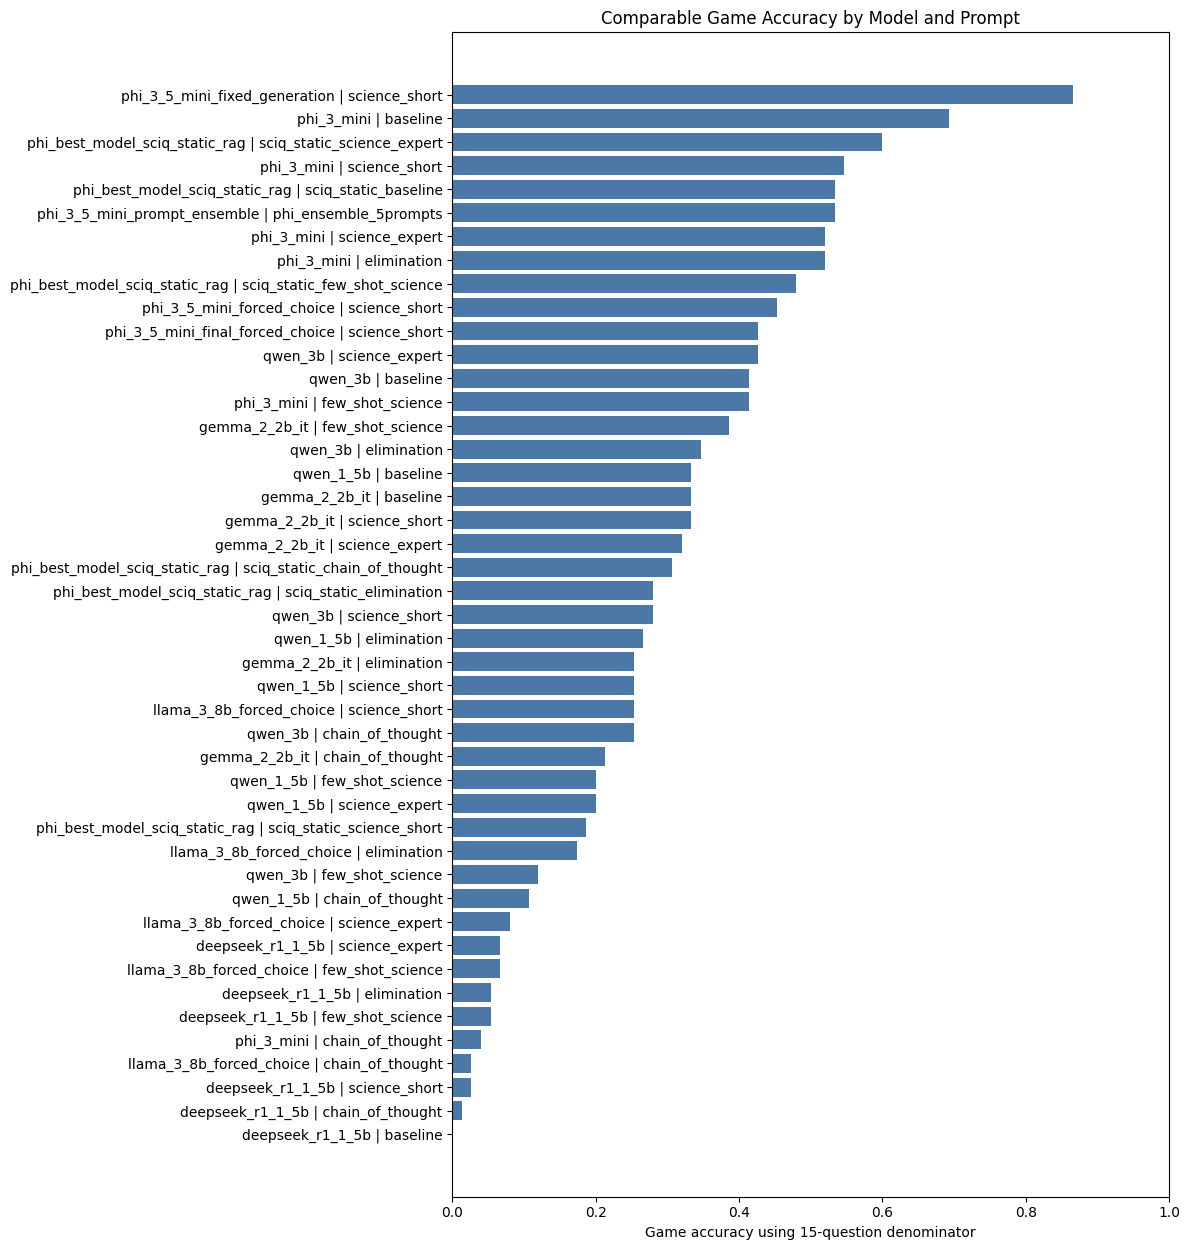

In [ ]:
if "df_top3_model_ensemble" in globals() and isinstance(df_top3_model_ensemble, pd.DataFrame) and not df_top3_model_ensemble.empty:
    top3_model_ensemble_analysis = analyse_model_runs(
        df_top3_model_ensemble,
        model_tag="Top-three model ensemble",
        output_prefix="science_nature_top3_model_ensemble",
        model_type="ensemble",
    )

if "df_top3_unweighted_ensemble" in globals() and isinstance(df_top3_unweighted_ensemble, pd.DataFrame) and not df_top3_unweighted_ensemble.empty:
    top3_unweighted_ensemble_analysis = analyse_model_runs(
        df_top3_unweighted_ensemble,
        model_tag="Top-three unweighted ensemble",
        output_prefix="science_nature_top3_unweighted_ensemble",
        model_type="ensemble",
    )

df_topic_analysis = collect_available_question_logs()

if df_topic_analysis.empty:
    print("No logs available yet. Run the model benchmark cells first, then rerun this cell.")
else:
    df_topic_analysis["model_prompt"] = (
        df_topic_analysis["model_label"].astype(str)
        + " | "
        + df_topic_analysis["prompt_type"].astype(str)
    )
    df_topic_analysis["correct"] = df_topic_analysis["correct"].astype(bool)

    run_counts = df_topic_analysis.groupby(["model_label", "prompt_type"])["run_key"].nunique().reset_index(name="runs")

    all_model_prompt_question_summary = df_topic_analysis.groupby(["model_label", "prompt_type"]).agg(
        questions_seen=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        valid_output_rate=("valid_output", "mean"),
        average_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        average_confidence=("confidence_score", "mean") if "confidence_score" in df_topic_analysis.columns else ("correct", "mean"),
    ).reset_index()

    all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
        run_counts,
        on=["model_label", "prompt_type"],
        how="left",
    )
    all_model_prompt_question_summary["game_accuracy_out_of_15"] = (
        all_model_prompt_question_summary["correct_answers"]
        / (all_model_prompt_question_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    if "confidence_score" in df_topic_analysis.columns:
        confidence_by_correctness = df_topic_analysis.groupby(["model_label", "prompt_type", "correct"])["confidence_score"].mean().reset_index()
        confidence_pivot = confidence_by_correctness.pivot_table(
            index=["model_label", "prompt_type"],
            columns="correct",
            values="confidence_score",
        ).reset_index().rename(columns={False: "average_confidence_when_wrong", True: "average_confidence_when_correct"})
        all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
            confidence_pivot,
            on=["model_label", "prompt_type"],
            how="left",
        )
        overconfident_wrong = df_topic_analysis.assign(
            overconfident_wrong=(~df_topic_analysis["correct"]) & (pd.to_numeric(df_topic_analysis["confidence_score"], errors="coerce") >= 0.60)
        ).groupby(["model_label", "prompt_type"])["overconfident_wrong"].sum().reset_index(name="overconfident_wrong_count")
        all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
            overconfident_wrong,
            on=["model_label", "prompt_type"],
            how="left",
        )
    else:
        all_model_prompt_question_summary["average_confidence_when_wrong"] = np.nan
        all_model_prompt_question_summary["average_confidence_when_correct"] = np.nan
        all_model_prompt_question_summary["overconfident_wrong_count"] = np.nan

    all_model_prompt_survival = make_survival_summary(df_topic_analysis)
    survival_columns = [
        "model_label",
        "prompt_type",
        "average_questions_reached",
        "best_questions_reached",
        "average_final_earned_amount",
        "best_final_earned_amount",
    ]
    all_model_prompt_question_summary = all_model_prompt_question_summary.merge(
        all_model_prompt_survival[[column for column in survival_columns if column in all_model_prompt_survival.columns]],
        on=["model_label", "prompt_type"],
        how="left",
    )

    all_model_prompt_question_summary = all_model_prompt_question_summary.sort_values(
        by=["average_questions_reached", "game_accuracy_out_of_15", "valid_output_rate"],
        ascending=False,
    ).reset_index(drop=True)
    all_model_prompt_question_summary.insert(0, "rank", range(1, len(all_model_prompt_question_summary) + 1))

    all_model_error_type_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "error_type"]).size().reset_index(name="count")
    all_model_topic_summary = df_topic_analysis.groupby(["model_label", "prompt_type", "topic"]).agg(
        questions=("question_id", "count"),
        correct_answers=("correct", "sum"),
        errors=("correct", lambda values: (~values).sum()),
        observed_topic_accuracy=("correct", "mean"),
        average_level_seen=("level_before_answer", "mean"),
        mean_answer_correct=("correct", "mean"),
        mean_response_time=("response_time", "mean"),
        max_response_time=("response_time", "max"),
        runs=("run_key", "nunique"),
    ).reset_index()
    all_model_topic_summary["game_accuracy_contribution"] = (
        all_model_topic_summary["correct_answers"]
        / (all_model_topic_summary["runs"].clip(lower=1) * MAX_GAME_QUESTIONS)
    )

    MIN_TOPIC_QUESTIONS_FOR_WINNER = 2
    best_model_by_topic = (
        all_model_topic_summary[all_model_topic_summary["questions"] >= MIN_TOPIC_QUESTIONS_FOR_WINNER]
        .sort_values(
            ["topic", "observed_topic_accuracy", "correct_answers", "questions", "mean_response_time"],
            ascending=[True, False, False, False, True],
        )
        .groupby("topic")
        .head(1)
        .reset_index(drop=True)
    )
    best_model_by_topic = best_model_by_topic.rename(
        columns={
            "model_label": "best_model",
            "prompt_type": "best_prompt",
            "observed_topic_accuracy": "mean_answer_accuracy",
            "average_level_seen": "mean_level_seen",
            "mean_response_time": "mean_time_seconds",
        }
    )
    topic_table_columns = [
        "topic",
        "best_model",
        "best_prompt",
        "questions",
        "correct_answers",
        "mean_answer_accuracy",
        "mean_level_seen",
        "mean_time_seconds",
        "runs",
        "game_accuracy_contribution",
    ]
    best_model_by_topic = best_model_by_topic[
        [column for column in topic_table_columns if column in best_model_by_topic.columns]
    ]

    all_model_prompt_question_summary.to_csv("science_nature_all_model_prompt_summary.csv", index=False)
    all_model_error_type_summary.to_csv("science_nature_all_model_error_type_summary.csv", index=False)
    all_model_topic_summary.to_csv("science_nature_all_model_topic_summary.csv", index=False)
    best_model_by_topic.to_csv("science_nature_best_model_by_topic.csv", index=False)

    print("Clear model/prompt performance table using the fixed 15-question denominator")
    display(all_model_prompt_question_summary)

    print("Error type counts for every model and prompt")
    display(all_model_error_type_summary.sort_values(["model_label", "prompt_type", "count"], ascending=[True, True, False]))

    print("Topic performance for every model and prompt")
    display(all_model_topic_summary.sort_values(["topic", "observed_topic_accuracy"], ascending=[True, False]))

    print("Best observed model/prompt by topic")
    display(best_model_by_topic)

    plt.figure(figsize=(12, max(4, 0.28 * len(all_model_prompt_question_summary))))
    plot_data = all_model_prompt_question_summary.sort_values("game_accuracy_out_of_15")
    labels = plot_data["model_label"].astype(str) + " | " + plot_data["prompt_type"].astype(str)
    plt.barh(labels, plot_data["game_accuracy_out_of_15"], color="#4C78A8")
    plt.xlabel("Game accuracy using 15-question denominator")
    plt.title("Comparable Game Accuracy by Model and Prompt")
    plt.xlim(0, 1)
    plt.tight_layout()
    plt.savefig("science_nature_all_model_game_accuracy.png", dpi=150, bbox_inches="tight")
    plt.show()


# Model size and performance analysis

This section compares model size against the average level reached using the best observed prompt/configuration for each model label.

The current saved outputs show a non-monotonic relationship between parameter count and performance. Qwen 3B improved over Qwen 1.5B, but Llama 3 8B did not outperform the smaller instruction-tuned models. The best result came from the Phi family: `phi_3_5_mini_fixed_generation_science_short` reached **13.8 average questions**, while the best Llama 8B setting reached **4.8**. Therefore, the report should avoid claiming that larger models are always better; the stronger conclusion is that model family, instruction tuning, prompt fit, answer extraction, and runtime reliability mattered more than size alone.

,summary_source,model_label,model_type,system_name,prompt_type,runs,average_questions_reached,best_questions_reached,average_correct_answers,total_correct_answers,accuracy,average_accuracy,best_accuracy,average_final_earned_amount,best_final_earned_amount,average_response_time,max_response_time,valid_output_rate,parameter_count_b
0,survival_summary_deepseek_sorted,deepseek_r1_1_5b,thinking,deepseek_r1_1_5b_science_expert,science_expert,5,2.0,5,1.0,5,0.066667,0.066667,0.266667,120.0,500,2.580359,4.007628,0.46,1.5
1,gemma_survival_summary_sorted,gemma_2_2b_it,non-thinking,gemma_2_2b_it_few_shot_science,few_shot_science,5,6.6,15,5.8,29,0.386667,0.386667,1.0,211280.0,1024000,0.542497,0.722529,1.00,2.6
2,llama_survival_summary_sorted,llama_3_8b_forced_choice,non-thinking,llama_3_8b_forced_choice_science_short,science_short,5,4.8,7,3.8,19,0.253333,0.253333,0.4,860.0,2000,1.377770,2.924235,1.00,8.0
3,final_survival_summary,phi_3_5_mini_final_forced_choice,non-thinking,phi_3_5_mini_final_forced_choice_science_short,science_short,10,7.3,15,6.4,64,0.426667,0.426667,1.0,108510.0,1024000,0.422350,0.626991,1.00,3.8
4,phi_fixed_generation_summary,phi_3_5_mini_fixed_generation,non-thinking,phi_3_5_mini_fixed_generation_science_short,science_short,5,13.8,15,13.0,65,0.866667,0.866667,1.0,464000.0,1024000,0.422788,0.941358,1.00,3.8
5,phi_forced_choice_summary,phi_3_5_mini_forced_choice,non-thinking,phi_3_5_mini_forced_choice_science_short,science_short,5,7.6,15,6.8,34,0.453333,0.453333,1.0,206740.0,1024000,0.414797,0.612885,1.00,3.8
6,phi_ensemble_summary_sorted,phi_3_5_mini_prompt_ensemble,non-thinking,phi_3_5_mini_prompt_ensemble_phi_ensemble_5pro...,phi_ensemble_5prompts,5,9.0,15,8.0,40,0.533333,0.533333,0.933333,106600.0,512000,2.912187,4.271116,1.00,3.8
7,survival_summary_current_model,phi_3_mini,NaN,phi_3_mini_baseline,baseline,5,11.2,15,10.4,52,0.693333,0.693333,1.0,313620.0,1024000,0.435798,1.130582,1.00,3.8
8,survival_summary_qwen_1_5b,qwen_1_5b,NaN,qwen_1_5b_baseline,baseline,5,6.0,11,5.0,25,0.333333,0.333333,0.666667,8240.0,32000,0.136050,0.314140,1.00,1.5
9,qwen_comparison_summary_sorted,qwen_3b,non-thinking,qwen_3b_science_expert,science_expert,5,7.4,12,6.4,32,0.426667,0.426667,0.733333,15600.0,64000,0.206760,0.251821,1.00,3.0


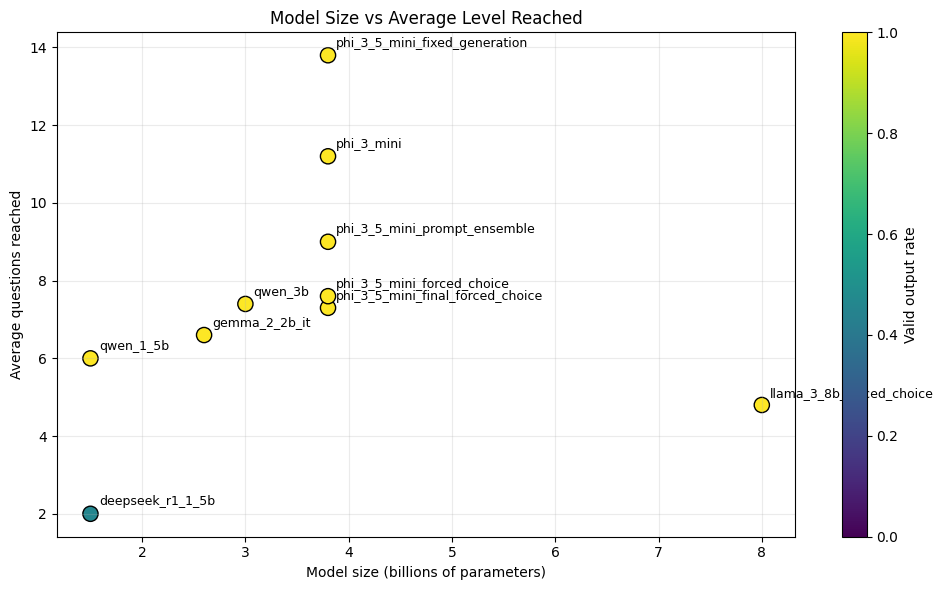

In [ ]:
MODEL_SIZE_BILLIONS = {
    "qwen_1_5b": 1.5,
    "qwen_3b": 3.0,
    "qwen_3b_final": 3.0,
    "qwen_3b_confidence": 3.0,
    "phi_3_mini": 3.8,
    "phi_3_5_mini_fixed_generation": 3.8,
    "phi_3_5_mini_forced_choice": 3.8,
    "phi_3_5_mini_prompt_ensemble": 3.8,
    "deepseek_r1_1_5b": 1.5,
    "deepseek_r1_1_5b_fixed": 1.5,
    "gemma_2_2b_it": 2.6,
    "llama_3_8b_forced_choice": 8.0,
}


def infer_model_size_billion(model_label):
    label = str(model_label)

    if label in MODEL_SIZE_BILLIONS:
        return MODEL_SIZE_BILLIONS[label]
    if "1_5b" in label or "1.5b" in label:
        return 1.5
    if "2_2b" in label or "2b" in label:
        return 2.6
    if "3b" in label or "3_b" in label:
        return 3.0
    if "phi_3" in label or "phi_3_5" in label:
        return 3.8
    if "8b" in label:
        return 8.0

    return None


if final_result_story_table.empty:
    print("Run the comparison summary cell first.")
else:
    model_size_performance_table = final_result_story_table.copy()
    model_size_performance_table["parameter_count_b"] = model_size_performance_table["model_label"].apply(infer_model_size_billion)
    model_size_performance_table = model_size_performance_table.dropna(subset=["parameter_count_b", "average_questions_reached"])

    best_prompt_per_model_size = (
        model_size_performance_table
        .sort_values(["model_label", "average_questions_reached", "best_questions_reached"], ascending=[True, False, False])
        .groupby("model_label")
        .head(1)
        .reset_index(drop=True)
    )

    model_size_performance_table.to_csv("science_nature_model_size_performance_all_configs.csv", index=False)
    best_prompt_per_model_size.to_csv("science_nature_model_size_performance_best_per_model.csv", index=False)

    display(best_prompt_per_model_size)

    fig, ax = plt.subplots(figsize=(10, 6))
    scatter = ax.scatter(
        best_prompt_per_model_size["parameter_count_b"],
        best_prompt_per_model_size["average_questions_reached"],
        s=120,
        c=best_prompt_per_model_size.get("valid_output_rate", pd.Series([1] * len(best_prompt_per_model_size))),
        cmap="viridis",
        vmin=0,
        vmax=1,
        edgecolor="black",
    )

    for _, row in best_prompt_per_model_size.iterrows():
        ax.annotate(
            row["model_label"],
            (row["parameter_count_b"], row["average_questions_reached"]),
            textcoords="offset points",
            xytext=(6, 6),
            fontsize=9,
        )

    ax.set_title("Model Size vs Average Level Reached")
    ax.set_xlabel("Model size (billions of parameters)")
    ax.set_ylabel("Average questions reached")
    ax.grid(True, alpha=0.25)
    fig.colorbar(scatter, ax=ax, label="Valid output rate")
    plt.tight_layout()
    plt.savefig("science_nature_model_size_vs_performance.png", dpi=150, bbox_inches="tight")
    plt.show()


In [ ]:
# Optional controlled rerun.


RUN_CONTROLLED_FINAL_COMPARISON = False
CONTROLLED_RUNS_PER_SYSTEM = 10

controlled_candidate_specs = [
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_forced_choice",
        "prompt_type": "science_short",
        "loader": "phi",
        "answer_fn": generate_answer_phi_scored,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "loader": "phi",
        "answer_fn": generate_answer_phi_scored,
    },
    {
        "model_id": "microsoft/Phi-3.5-mini-instruct",
        "model_label": "phi_3_5_mini_controlled_ensemble",
        "prompt_type": "phi_ensemble_5prompts",
        "loader": "phi",
        "answer_fn": generate_answer_phi_ensemble,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_controlled_science_short",
        "prompt_type": "science_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_controlled_elimination",
        "prompt_type": "elimination",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "model_id": "Qwen/Qwen2.5-3B-Instruct",
        "model_label": "qwen_3b_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template_with_confidence,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_controlled_science_short",
        "prompt_type": "science_short",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "model_id": "google/gemma-2-2b-it",
        "model_label": "gemma_2_2b_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "use_4bit": False,
        "answer_fn": generate_answer_chat_template,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_controlled_science_short",
        "prompt_type": "science_short",
        "use_4bit": True,
        "answer_fn": generate_answer_scored_options,
    },
    {
        "model_id": "meta-llama/Meta-Llama-3-8B",
        "model_label": "llama_3_8b_controlled_chain_of_thought",
        "prompt_type": "chain_of_thought",
        "use_4bit": True,
        "answer_fn": generate_answer_scored_options,
    },
]

if RUN_CONTROLLED_FINAL_COMPARISON:
    controlled_runs = []

    for candidate in controlled_candidate_specs:
        if candidate.get("loader") == "phi":
            load_phi_model()
        else:
            load_chat_model(
                model_id=candidate["model_id"],
                model_label=candidate["model_label"],
                use_4bit=candidate.get("use_4bit", False),
            )

        df_candidate = benchmark_answer_fn(
            answer_fn=candidate["answer_fn"],
            model_label=candidate["model_label"],
            prompt_type=candidate["prompt_type"],
            n_runs=CONTROLLED_RUNS_PER_SYSTEM,
            delay_seconds=1.5,
        )
        controlled_runs.append(df_candidate)

    df_controlled_final = pd.concat(controlled_runs, ignore_index=True)
    controlled_final_summary = make_survival_summary(df_controlled_final).sort_values(
        by=["average_questions_reached", "best_questions_reached", "average_final_earned_amount"],
        ascending=False,
    )

    df_controlled_final.to_csv("science_nature_controlled_final_question_level_results.csv", index=False)
    controlled_final_summary.to_csv("science_nature_controlled_final_summary.csv", index=False)

    display(controlled_final_summary)
else:
    print("Controlled final comparison is disabled. Set RUN_CONTROLLED_FINAL_COMPARISON = True when ready.")


Controlled final comparison is disabled. Set RUN_CONTROLLED_FINAL_COMPARISON = True when ready.


<!-- REPORT_MARKDOWN_FINAL_V2 -->
#Final conclusions from the current notebook outputs

The strongest observed system in the saved notebook outputs is `phi_3_5_mini_fixed_generation_science_short`. It reached an average of **13.8 questions** across 5 runs, achieved a best run of **15 questions**, kept a valid-output rate of **1.0**, and answered quickly with an average response time of about **0.42 seconds**. Using the fixed game denominator, its game accuracy was **65 / 75 = 0.867**.

The main findings to highlight in the report are:

- **Accuracy is calculated with the fixed game denominator.** For repeated runs, game accuracy is `total_correct_answers / (runs × 15)`, because 15 is the maximum number of questions in one game. This keeps model comparisons fair even when games end early.
- **Prompting mattered, but longer reasoning was not automatically better.** Qwen 1.5B performed best with the plain baseline prompt (**6.0 average questions**) and worse with chain-of-thought (**2.6 average questions**). This supports using concise, controlled prompts in the timed game.
- **Model family mattered more than size alone.** Qwen 3B improved over Qwen 1.5B, but Llama 3 8B did not win. The best Phi-3.5-mini setup strongly outperformed Gemma, Qwen, Llama, and DeepSeek in the saved outputs.
- **The best saved system is Phi-3.5-mini fixed generation, not the older Phi baseline.** The previous strong `phi_3_mini_baseline` reached **11.2 average questions**, but the corrected `phi_3_5_mini_fixed_generation_science_short` reached **13.8**.
- **Forced-choice scoring is useful for confidence analysis, but it was not the top survival system in this runtime.** The final 10-run forced-choice Phi check reached **7.3 average questions** with complete confidence coverage and no overconfident errors. It is useful for explaining calibration, while fixed generation is the better final-performance choice.
- **Thinking-style output was not enough.** DeepSeek R1 Distill 1.5B produced reasoning-style outputs, but the best DeepSeek prompt reached only **2.0 average questions** and had weaker valid-output behaviour.
- **RAG was mixed.** The best reproducible SciQ RAG setting reached **9.8 average questions** and a best run of **15**, but it did not beat the best non-RAG Phi fixed-generation setup and was slower. RAG should be presented as an extension rather than the final default.
- **Ensembling was not automatically better.** The Phi prompt ensemble reached **9.0 average questions**, while both top-three model ensembles failed in the current saved summaries. The strongest single Phi setup remained the best practical choice.

###Final system choice

For the final leaderboard/demo run, use:

**Phi-3.5-mini fixed generation + `science_short` prompt**

This is the best saved system because it combines the highest average survival, a perfect best run, fully valid outputs, and fast response time. The forced-choice Phi version can still be discussed as a cleaner confidence/calibration method, but it should not be presented as the highest-performing system in this runtime.

